## 1. Config

<details>
<summary><b>Config: Parámetros globales y logging</b></summary>

<br>

**Rutas Definidas:**
* **`DATA_PATH`**: Ruta a los archivos fuente (`data/delitos/csv`).

**Parámetros Globales:**
* **`START_DATE` / `END_DATE`**: Rango temporal de análisis (2016-01-01 a 2024-06-30).
* **`DATE_COL`**: Columna de fecha de los registros (`fecha_hecho`).
* **`TARGET_CRIME`**: Tipo penal bajo análisis.
* **`WINDOW_SIZE`**: Tamaño de la ventana temporal en semanas.
* **`STEP_SIZE`**: Desplazamiento entre ventanas consecutivas en semanas.

**Ejemplo del Log:**
```text
2026-10-05 19:21:57,120 - [<module>] - INFO - Configuración inicial cargada: Delito='ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA' | Ventana=104 sem | Paso=26 sem
2026-10-05 19:21:57,121 - [<module>] - INFO - EXITO. ✅

In [3]:
# [CONFIG] Imports, logging y parámetros globales

# 1. Biblioteca estándar
import logging
import math
from pathlib import Path
import random
import re
import sys
from typing import Iterator, Union
import warnings

# 2. Bibliotecas de terceros
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import openpyxl
import pandas as pd
import plotly.graph_objects as go
import powerlaw
from scipy.optimize import OptimizeWarning
from uuid import uuid4
from datetime import datetime, timezone


# Configuración del sistema de logging
logging.basicConfig(
    stream=sys.stdout,
    level=logging.INFO,
    format="%(asctime)s - [%(funcName)s] - %(levelname)s - %(message)s",
    force=True,
)
logger = logging.getLogger("Delitos")

# Constantes del sistema de archivos y temporales
DATA_PATH = Path("data/delitos/csv")
REPORT_PATH = Path("data/reports")
START_DATE = pd.Timestamp("2016-01-01")
END_DATE = pd.Timestamp("2024-06-30")
DATE_COL = "fecha_hecho"

# Delito bajo análisis
# TARGET_CRIME = "HOMICIDIO POR ARMA DE FUEGO"
# TARGET_CRIME = "FEMINICIDIO"
# TARGET_CRIME = "ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"
# TARGET_CRIME = "ROBO A CASA HABITACION CON VIOLENCIA"
# TARGET_CRIME = "ROBO A CASA HABITACION SIN VIOLENCIA"
# TARGET_CRIME = "ROBO A TRANSEUNTE SALIENDO DEL CAJERO CON VIOLENCIA"
TARGET_CRIME = "ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA"

# Parámetros del filtro de ventana deslizante (Rolling Window)
# WINDOW_SIZE = 4   # 1 Mes
# WINDOW_SIZE = 12  # 1 Trimestre
# WINDOW_SIZE = 26  # 1 Semestre
WINDOW_SIZE = 52  # 1 Año
# WINDOW_SIZE = 104  # 2 Años

# STEP_SIZE = 1   # 1 Semana
# STEP_SIZE = 2   # 2 Semanas
# STEP_SIZE = 4   # 1 Mes (~4 semanas)
# STEP_SIZE = 8   # 1 Bimestre (~8 semanas)
STEP_SIZE = 12  # 1 Trimestre (~12 semanas)
# STEP_SIZE = 26  # 1 Semestre (~26 semanas)

logger.info(
    f"Configuración inicial cargada: Delito='{TARGET_CRIME}' | "
    f"Ventana={WINDOW_SIZE} sem | Paso={STEP_SIZE} sem"
)
logger.info("EXITO. ✅")

2026-10-08 01:44:44,469 - [<module>] - INFO - Configuración inicial cargada: Delito='ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA' | Ventana=52 sem | Paso=12 sem
2026-10-08 01:44:44,469 - [<module>] - INFO - EXITO. ✅


## 2. Definiciones

### Data

#### Def. Extracción de CSV

<details>
<summary><b>Función: extract_crime_data(path, target_crime)</b></summary>

<br>

Extrae y consolida en un único `DataFrame` los registros asociados a una categoría específica de delito a partir de los archivos CSV presentes en un directorio.

**Parámetros**
* **`path`** (`str` | `Path`): Ruta al directorio que contiene los archivos CSV de origen.
* **`target_crime`** (`str`): Etiqueta exacta del delito a filtrar (columna `delito`).

**Retorno**
* **`pd.DataFrame`**: Registros consolidados. Si no hay coincidencias, retorna un `DataFrame` vacío.

**Excepciones**
* **`FileNotFoundError`**: Si el directorio no existe o no contiene archivos `.csv`.

</details>

In [5]:
# [FUNCION] extract_crime_data(path, target_crime)

def extract_crime_data(path: Union[str, Path], target_crime: str) -> pd.DataFrame:
    data_dir = Path(path)

    logger.info("Revisando directorio.")
    if not data_dir.exists() or not data_dir.is_dir():
        logger.error(f"Directorio inválido o inexistente: {data_dir}")
        raise FileNotFoundError(f"Directorio no encontrado: {data_dir}")

    csv_files = list(data_dir.glob("*.csv"))
    if not csv_files:
        logger.error(f"Sin archivos CSV en: {data_dir}")
        raise FileNotFoundError(f"No se encontraron CSV en: {data_dir}")

    logger.info(f"Buscando {target_crime}")
    logger.info("Extrayendo registros")
    records = []

    for file_path in csv_files:
        try:
            df_temp = pd.read_csv(file_path, low_memory=False)
            if "delito" in df_temp.columns:
                filtered = df_temp[df_temp["delito"] == target_crime]
                if not filtered.empty:
                    records.append(filtered)
        except Exception as e:
            logger.warning(f"No se pudo procesar {file_path.name}: {e}")

    if not records:
        logger.warning(f"No se encontraron registros para: {target_crime}")
        return pd.DataFrame()

    logger.info("Generando dataframe")
    df_raw = pd.concat(records, ignore_index=True)

    logger.info(f"EXITO. Se extrajeron {len(df_raw):,} registros.")
    return df_raw

#### Def. Filtrado por intervalo de tiempo

<details>
<summary><b>Helpers: Filtrado de datos RAW por intervalo de tiempo</b></summary>

<br>

Conjunto de funciones auxiliares para normalización de tipos temporales, extracción de series de fecha y filtrado por rangos cronológicos.

**Funciones incluidas**
* **`ensure_datetime_type(df, column)`**: Convierte la columna a `datetime64` con coerción de errores si no tiene el tipo correcto.
* **`extract_dates(df, date_column)`**: Extrae una proyección de la columna de fecha asegurando su tipado.
* **`filter_by_date_range(df, date_column, start, end)`**: Aplica máscara booleana para acotar registros dentro del intervalo `[start, end]`.

**Parámetros comunes**
* `df` (`pd.DataFrame`): DataFrame a procesar.
* `date_column` (`str`): Nombre de la columna que contiene los datos temporales.
* `start`, `end` (`pd.Timestamp`): Límites inferior y superior del rango de análisis.

</details>

In [6]:
# [HELPERS] Filtrado de datos RAW por intervalo de tiempo
# INPUT:  df (pd.DataFrame), date_column (str), start/end (pd.Timestamp)
# OUTPUT: pd.DataFrame


def ensure_datetime_type(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """Verifica si la columna es datetime; si no lo es, realiza la conversión."""
    if not pd.api.types.is_datetime64_any_dtype(df[column]):
        logger.info(f"Convirtiendo tiempo en columna '{column}'")
        df[column] = pd.to_datetime(df[column], errors="coerce")
    return df


def extract_dates(df: pd.DataFrame, date_column: str) -> pd.DataFrame:
    """Extrae la columna como DataFrame y garantiza que el tipo sea datetime."""
    logger.info("Extrayendo datos")
    df_dates = df[[date_column]].copy()
    df_dates = ensure_datetime_type(df_dates, date_column)
    logger.info("EXITO.")
    return df_dates


def filter_by_date_range(df: pd.DataFrame, date_column: str, start: pd.Timestamp, end: pd.Timestamp,) -> pd.DataFrame:
    """Filtra el DataFrame reteniendo estrictamente los registros dentro del periodo definido."""
    logger.info("Filtrando registros")
    mask = (df[date_column] >= start) & (df[date_column] <= end)
    df_filtered = df[mask].copy()
    logger.info("EXITO.")
    return df_filtered

#### Def. Agrupación semanal y nodos

<details>
<summary><b>Helpers: Agrupación Semanal e Indexación de Nodos</b></summary>

<br>

Prepara la serie temporal continua agrupando las frecuencias en intervalos de 7 días continuos y asigna un identificador secuencial de nodo a cada bloque cronológico.

**Funciones incluidas**
* **`events_by_week(df, date_column, origin_date)`**: Remuestrea observaciones temporales en intervalos de 168 horas anclados a la fecha de inicio.
* **`assign_network_nodes(df)`**: Asigna la numeración ordinal inicial de nodos para la serie temporal consolidada.

</details>

In [7]:
# [HELPERS] Agrupación Semanal e indexación de la serie temporal global
# INPUT:  df (pd.DataFrame), date_column (str), origin_date (pd.Timestamp)
# OUTPUT: pd.DataFrame
import pandas as pd


def events_by_week(
    df: pd.DataFrame,
    date_column: str = "fecha_hecho",
    origin_date: pd.Timestamp = START_DATE,
) -> pd.DataFrame:
    """Agrupa en bloques de 7 días absolutos (168 horas) anclados a origin_date."""
    logger.info("Agrupando serie temporal en bloques semanales")
    weekly_series = (
        df.resample("168h", on=date_column, origin=origin_date)
        .size()
        .reset_index(name="cantidad")
    )
    weekly_series[date_column] = weekly_series[date_column].dt.normalize()
    logger.info("EXITO.")
    return weekly_series


def assign_network_nodes(df: pd.DataFrame) -> pd.DataFrame:
    """Asigna un identificador secuencial (nodo) a cada bloque temporal."""
    logger.info("Asignando identificadores topologicos a nodos")
    df_nodes = df.copy()
    df_nodes["nodo"] = range(len(df_nodes))
    logger.info("EXITO.")
    return df_nodes[["nodo", "fecha_hecho", "cantidad"]]

### Windows

#### Def. Ventanas móviles

<details>
<summary><b>Helpers: Generador de Ventanas Deslizantes (Rolling Window)</b></summary>

<br>

Segmenta la serie temporal continua en subconjuntos finitos de longitud fija `WINDOW_SIZE` con desplazamiento `STEP_SIZE`. Para cada intervalo, reindexa localmente los identificadores de nodo en el rango $[0, W-1]$, garantizando que la distancia horizontal $\Delta t = j - i$ corresponda estrictamente a la métrica de visibilidad en esa ventana local.

**Parámetros**
* **`df`** (`pd.DataFrame`): Serie temporal global con columnas `nodo`, `fecha_hecho`, `cantidad`.
* **`window_size`** (`int`): Cantidad de semanas que integran cada ventana local.
* **`step`** (`int`, opcional): Paso o salto de desplazamiento entre ventanas consecutivas (por defecto `1`).

**Retorno (Generador / `Iterator[dict]`)**
* Produce diccionarios con la estructura:
  * `window_id` (`int`): Índice ordinal de la ventana.
  * `start_idx` / `end_idx` (`int`): Índices globales en la serie original.
  * `start_date` / `end_date` (`pd.Timestamp`): Intervalo temporal cubierto.
  * `df_window` (`pd.DataFrame`): Rebanada con columna `nodo` reindexada localmente $[0 \dots W-1]$.

</details>

In [8]:
# [HELPERS] Segmentación y reindexación por ventana deslizante
# INPUT:  df (pd.DataFrame), window_size (int), step (int)
# OUTPUT: Iterator[dict]
from typing import Iterator
import pandas as pd


def generate_rolling_windows(df: pd.DataFrame, window_size: int, step: int = 1) -> Iterator[dict]:
    """Genera sub-dataframes para ventanas deslizantes reindexando localmente los nodos."""
    logger.info(
        f"Inicializando generador de rolling window (W={window_size}, S={step})"
    )
    n = len(df)
    if n < window_size:
        logger.warning(
            f"Longitud de datos ({n}) insuficiente para ventana ({window_size})."
        )
        return

    window_id = 0
    for start_idx in range(0, n - window_size + 1, step):
        end_idx = start_idx + window_size
        sub_df = df.iloc[start_idx:end_idx].copy()

        start_date = sub_df["fecha_hecho"].iloc[0]
        end_date = sub_df["fecha_hecho"].iloc[-1]

        # Reindexación local 0 .. W-1 para mantener delta_t consistente en el NVG
        sub_df["nodo"] = range(len(sub_df))

        yield {
            "window_id": window_id,
            "start_idx": start_idx,
            "end_idx": end_idx - 1,
            "start_date": start_date,
            "end_date": end_date,
            "df_window": sub_df,
        }
        window_id += 1

    logger.info("EXITO.")

#### Def. Grafos Moviles

In [9]:
def build_rolling_graphs(df_nodes: pd.DataFrame, window_size: int | None = None, step_size: int | None = None, ) -> list[dict]:
    """Construye un grafo NVG por ventana móvil."""

    if window_size is None:
        window_size = WINDOW_SIZE

    if step_size is None:
        step_size = STEP_SIZE

    if window_size <= 0 or step_size <= 0:
        raise ValueError("window_size y step_size deben ser positivos.")

    rolling_graphs = []

    for window_data in generate_rolling_windows(
        df_nodes,
        window_size=window_size,
        step=step_size,
    ):
        g_window = build_natural_visibility_graph(
            window_data["df_window"],
            verbose=False,
        )

        rolling_graphs.append(
            {
                "window_id": window_data["window_id"],
                "start_date": window_data["start_date"],
                "end_date": window_data["end_date"],
                "graph": g_window,
            }
        )

    if rolling_graphs:
        primera = rolling_graphs[0]
        ultima = rolling_graphs[-1]

        logger.info(
            f"Resumen Rolling Window: {len(rolling_graphs)} grafos generados | "
            f"W={window_size}, S={step_size} | "
            f"Rango: {primera['start_date']:%Y-%m-%d} -> "
            f"{ultima['end_date']:%Y-%m-%d} | "
            f"Nodos por ventana: {primera['graph'].number_of_nodes()}"
        )
    else:
        logger.warning(
            "No se generaron ventanas con los parámetros provistos."
        )

    return rolling_graphs

### Graphs

#### Def. Grafo de visibilidad natural

<details>
<summary><b>Helpers: Constructor del Grafo de Visibilidad Natural (NVG)</b></summary>

<br>

Construye un grafo no dirigido $G = (V, E)$ a partir de una serie temporal continua aplicando el criterio de visibilidad geométrica de Lacasa et al. (2008). 

Dos observaciones $(t_a, y_a)$ y $(t_b, y_b)$ establecen una arista si para cualquier punto intermedio $(t_c, y_c)$ con $t_a < t_c < t_b$ se cumple:
$$y_c < y_b + (y_a - y_b) \frac{t_b - t_c}{t_b - t_a}$$

**Parámetros**
* **`df`** (`pd.DataFrame`): Serie temporal con columnas `nodo` (entero secuencial), `fecha_hecho` (temporal) y `cantidad` (numérico).

**Retorno**
* **`nx.Graph`**: Red compleja donde cada vértice conserva los atributos de fecha y magnitud observada.

</details>

In [10]:
# [HELPERS] Algoritmo que construye el  Grafo de Visibilidad Natural (NVG)
# INPUT:  df (pd.DataFrame), verbose (bool)
# OUTPUT: nx.Graph
import networkx as nx
import pandas as pd


def build_natural_visibility_graph(df: pd.DataFrame, verbose: bool = True) -> nx.Graph:
    """Construye el Grafo de Visibilidad Natural (NVG) a partir de una serie temporal."""
    if verbose:
        logger.info("Construyendo Grafo de Visibilidad Natural")

    g = nx.Graph()

    # 1. Asignar nodos con sus atributos
    for _, row in df.iterrows():
        g.add_node(
            int(row["nodo"]),
            fecha_hecho=row["fecha_hecho"],
            cantidad=float(row["cantidad"]),
        )

    y = df["cantidad"].to_numpy()
    n = len(y)

    # 2. Evaluación del criterio geométrico de visibilidad
    for i in range(n - 1):
        g.add_edge(i, i + 1)
        max_slope = y[i + 1] - y[i]

        for j in range(i + 2, n):
            slope = (y[j] - y[i]) / (j - i)
            if slope > max_slope:
                g.add_edge(i, j)
                max_slope = slope

    if verbose:
        logger.info(
            f"EXITO. Grafo generado (|V|={g.number_of_nodes()}, |E|={g.number_of_edges()})."
        )

    return g

### Metrics

#### Def. Métricas por ventana

<details>
<summary><b>Helpers: Extracción de Estadisticos por Ventana de Tiempo</b></summary>

<br>

Calcula un vector escalar multidimensional de propiedades topológicas y estadísticas sobre una instancia individual de la red de visibilidad (`nx.Graph`), asociándola a su intervalo temporal de observación.

**Métricas extraídas**
* **Conectividad y Densidad:** Grado medio ($\langle k \rangle$) y densidad empírica ($\rho$).
* **Complejidad Informacional:** Entropía de Shannon de la distribución empírica de grados ($S = -\sum P(k) \ln P(k)$).
* **Propiedades Geodésicas:** Coeficiente de agrupamiento medio ($C$), longitud de camino característico ($L$), diámetro ($D$) y radio ($r$).
* **Inferencia de Escala:** Exponente $\gamma$ del ajuste a Ley de Potencia y distancias euclidianas directas en la cola ($k \geq x_{\min}$) respecto a los modelos teóricos de Ley de Potencia ($D_{PL}$) y Exponencial ($D_{Exp}$).

**Parámetros**
* **`grafo`** (`nx.Graph`): Subgrafo de visibilidad generado para la ventana móvil.
* **`window_id`** (`int`): Identificador ordinal del intervalo deslizante.
* **`start_date`** (`pd.Timestamp`): Fecha de inicio del bloque temporal evaluado.
* **`end_date`** (`pd.Timestamp`): Fecha de cierre (corte) del bloque temporal evaluado.

**Retorno**
* **`dict`**: Diccionario plano estructurado con los identificadores temporales y los escalares topológicos calculados.

</details>

In [11]:
# [HELPERS] Extracción de métricas escalares para una ventana temporal
# INPUT:  grafo (nx.Graph), window_id (int), start_date, end_date (pd.Timestamp)
# OUTPUT: dict
import warnings
import networkx as nx
import numpy as np
import pandas as pd
import powerlaw
from scipy.optimize import OptimizeWarning


def extract_window_metrics(
    grafo: nx.Graph,
    window_id: int,
    start_date: pd.Timestamp,
    end_date: pd.Timestamp,
) -> dict:
    """Calcula el vector de invariantes topológicos escalares para un grafo de ventana."""
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()

    # 1. Parámetros de conectividad
    k_degrees = [d for _, d in grafo.degree()]
    k_avg = float(np.mean(k_degrees)) if k_degrees else 0.0
    density_val = float(nx.density(grafo))

    # 2. Entropía de Shannon de la distribución P(k)
    k_vals, counts = np.unique(k_degrees, return_counts=True)
    probs = counts / n_nodes
    shannon_entropy = -float(np.sum(probs * np.log(probs + 1e-12)))

    # 3. Métricas de distancia y agrupamiento
    clustering_avg = float(nx.average_clustering(grafo))

    if nx.is_connected(grafo):
        diametro = int(nx.diameter(grafo))
        radio = int(nx.radius(grafo))
        avg_path_length = float(nx.average_shortest_path_length(grafo))
    else:
        # Fallback para componentes desconectados (el NVG de serie regular suele ser conexo)
        diametro = np.nan
        radio = np.nan
        avg_path_length = np.nan

    # 4. Ajuste estadístico y distancias a modelos teóricos
    gamma_val, dist_pl, dist_exp = np.nan, np.nan, np.nan
    data_k = np.array([d for d in k_degrees if d > 0])

    if len(data_k) >= 10:  # Muestra mínima para estabilidad numérica
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=OptimizeWarning)
            try:
                fit = powerlaw.Fit(data_k, discrete=True, verbose=False)
                gamma_val = float(fit.power_law.alpha)

                # Distancia euclidiana respecto a Power Law y Exponencial en la cola
                xmin = fit.xmin
                data_tail = data_k[data_k >= xmin]
                if len(data_tail) > 0:
                    k_eval, c_eval = np.unique(data_tail, return_counts=True)
                    y_emp = c_eval / len(data_tail)
                    dist_pl = float(
                        np.linalg.norm(y_emp - fit.power_law.pdf(k_eval))
                    )
                    dist_exp = float(
                        np.linalg.norm(y_emp - fit.exponential.pdf(k_eval))
                    )
            except Exception:
                pass

    return {
        "window_id": window_id,
        "start_date": start_date,
        "end_date": end_date,
        "fecha_corte": end_date,
        "nodos": n_nodes,
        "enlaces": n_edges,
        "grado_promedio": round(k_avg, 4),
        "densidad": round(density_val, 5),
        "clustering": round(clustering_avg, 4),
        "camino_medio": round(avg_path_length, 4)
        if not np.isnan(avg_path_length)
        else np.nan,
        "diametro": diametro,
        "radio": radio,
        "entropia_grado": round(shannon_entropy, 4),
        "gamma_powerlaw": round(gamma_val, 4)
        if not np.isnan(gamma_val)
        else np.nan,
        "dist_eucl_pl": round(dist_pl, 5)
        if not np.isnan(dist_pl)
        else np.nan,
        "dist_eucl_exp": round(dist_exp, 5)
        if not np.isnan(dist_exp)
        else np.nan,
    }

#### Def. Métricas estructurales por ventana

<details>
<summary><b>Helpers: Extracción de Métricas Estructurales por Ventana</b></summary>

<br>

Calcula el vector escalar de descriptores de red y de inferencia estadística sobre el grafo de visibilidad (`nx.Graph`) correspondiente a una ventana temporal específica, garantizando respaldo directo en la literatura formal de sistemas complejos y grafos de visibilidad.

**Invariantes extraídos**
* **Conectividad:** 
  * Nodos ($N$) y Enlaces ($M$).
  * Grado promedio ($\langle k \rangle = \frac{2M}{N}$).
  * Densidad empírica ($\rho = \frac{2M}{N(N-1)}$).
* **Propiedades Geodésicas y de Agrupamiento:**
  * Coeficiente de agrupamiento medio ($C = \langle C_i \rangle$) según la formulación de Watts y Strogatz.
  * Longitud de camino característico ($L$), diámetro ($D$) y radio ($r$), condicionados a la conexidad de la red.
* **Inferencia Estadística en la Cola ($k \ge x_{\min}$):**
  * Estimación por máxima verosimilitud (CSN) del exponente de escala $\gamma$ mediante `powerlaw.Fit`.
  * Distancias euclidianas directas ($D_{\text{PL}}$ y $D_{\text{Exp}}$) entre las frecuencias empíricas observadas y las funciones de densidad teóricas ajustadas.

**Parámetros**
* **`grafo`** (`nx.Graph`): Subgrafo de visibilidad natural de la ventana temporal.
* **`window_id`** (`int`): Identificador ordinal del intervalo móvil.
* **`start_date`** (`pd.Timestamp`): Fecha de inicio del intervalo analizado.
* **`end_date`** (`pd.Timestamp`): Fecha de cierre (corte) del intervalo analizado.

**Retorno**
* **`dict`**: Diccionario plano estructurado con identificadores temporales y métricas de red redondeadas.

</details>

In [12]:
# [HELPERS] Extracción de metricas por ventana
# INPUT:  grafo (nx.Graph), window_id (int), start_date, end_date (pd.Timestamp)
# OUTPUT: dict

def extract_window_metrics(
    grafo: nx.Graph,
    window_id: int,
    start_date: pd.Timestamp,
    end_date: pd.Timestamp,
) -> dict:
    """Calcula el vector de invariantes topológicos sustentados en la literatura formal."""
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()

    # 1. Conectividad estructural directa
    k_degrees = [d for _, d in grafo.degree()]
    k_avg = float(np.mean(k_degrees)) if k_degrees else 0.0
    density_val = float(nx.density(grafo))
    clustering_avg = float(nx.average_clustering(grafo))

    # 2. Rutas geodésicas (condicionadas a conexidad)
    if nx.is_connected(grafo):
        diametro = int(nx.diameter(grafo))
        radio = int(nx.radius(grafo))
        avg_path_length = float(nx.average_shortest_path_length(grafo))
    else:
        diametro = np.nan
        radio = np.nan
        avg_path_length = np.nan

    # 3. Ajuste de Clauset-Shalizi-Newman (CSN) y distancias euclidianas
    gamma_val, dist_pl, dist_exp = np.nan, np.nan, np.nan
    data_k = np.array([d for d in k_degrees if d > 0])

    if len(data_k) >= 10:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=OptimizeWarning)
            try:
                fit = powerlaw.Fit(data_k, discrete=True, verbose=False)
                gamma_val = float(fit.power_law.alpha)

                xmin = fit.xmin
                data_tail = data_k[data_k >= xmin]
                if len(data_tail) > 0:
                    k_eval, c_eval = np.unique(data_tail, return_counts=True)
                    y_emp = c_eval / len(data_tail)
                    dist_pl = float(
                        np.linalg.norm(y_emp - fit.power_law.pdf(k_eval))
                    )
                    dist_exp = float(
                        np.linalg.norm(y_emp - fit.exponential.pdf(k_eval))
                    )
            except Exception:
                pass

    return {
        "window_id": window_id,
        "start_date": start_date,
        "end_date": end_date,
        "fecha_corte": end_date,
        "nodos": n_nodes,
        "enlaces": n_edges,
        "grado_promedio": round(k_avg, 4),
        "densidad": round(density_val, 5),
        "clustering": round(clustering_avg, 4),
        "camino_medio": round(avg_path_length, 4)
        if not np.isnan(avg_path_length)
        else np.nan,
        "diametro": diametro,
        "radio": radio,
        "gamma_powerlaw": round(gamma_val, 4)
        if not np.isnan(gamma_val)
        else np.nan,
        "dist_eucl_pl": round(dist_pl, 5)
        if not np.isnan(dist_pl)
        else np.nan,
        "dist_eucl_exp": round(dist_exp, 5)
        if not np.isnan(dist_exp)
        else np.nan,
    }

#### Def. Métricas topológicas globales

<details>
<summary><b>Stats: Métricas Topológicas Globales</b></summary>

<br>

Calcula las propiedades estructurales y de distancia geodésica global del grafo de visibilidad natural, identificando las rutas críticas correspondientes al diámetro y radio de la red.

**Parámetros**
* **`grafo`** (`nx.Graph`): Grafo de visibilidad construido.

**Retorno**
* **`dict`**: Diccionario con métricas escalares y subestructuras:
  * `densidad_empirica`: Proporción de aristas existentes respecto al total teórico posible.
  * `radio` y `diametro`: Excentricidad mínima y máxima de la red conexa.
  * `centro`: Conjunto de nodos cuya excentricidad iguala al radio.
  * `nodos_diametro` / `aristas_diametro`: Ruta geodésica de longitud máxima.
  * `nodos_radio` / `aristas_radio`: Ruta geodésica representativa desde el centro.

</details>

In [13]:
# [STATS] Métricas topológicas globales de la red
# INPUT:  grafo (nx.Graph)
# OUTPUT: dict

def compute_graph_metrics(grafo: nx.Graph) -> dict:
    """Calcula densidad, radio, diámetro, centro y rutas geodésicas del grafo."""
    logger.info("Calculando métricas topológicas globales")
    densidad_empirica = nx.density(grafo)

    radio, diametro, centro = None, None, []
    aristas_diametro, aristas_radio = [], []
    nodos_diametro, nodos_radio = [], []

    if not nx.is_connected(grafo):
        logger.warning("El grafo no es conexo. Métricas basadas en distancias no aplican.")
        return {
            "densidad_empirica": densidad_empirica,
            "radio": radio,
            "diametro": diametro,
            "centro": centro,
            "nodos_diametro": nodos_diametro,
            "aristas_diametro": aristas_diametro,
            "nodos_radio": nodos_radio,
            "aristas_radio": aristas_radio,
        }

    radio = nx.radius(grafo)
    diametro = nx.diameter(grafo)
    centro = nx.center(grafo)

    path_lengths = dict(nx.shortest_path_length(grafo))

    # Identificación del camino diametral
    n1_diam, n2_diam = None, None
    for u in grafo.nodes():
        for v in grafo.nodes():
            if path_lengths[u][v] == diametro:
                n1_diam, n2_diam = u, v
                break
        if n1_diam is not None:
            break

    if n1_diam is not None:
        nodos_diametro = nx.shortest_path(grafo, source=n1_diam, target=n2_diam)
        aristas_diametro = list(zip(nodos_diametro, nodos_diametro[1:]))

    # Identificación del camino radial desde el centro
    if centro:
        nodo_centro = centro[0]
        for target_node in grafo.nodes():
            if path_lengths[nodo_centro][target_node] == radio:
                nodos_radio = nx.shortest_path(
                    grafo, source=nodo_centro, target=target_node
                )
                aristas_radio = list(zip(nodos_radio, nodos_radio[1:]))
                break

    logger.info("EXITO.")
    return {
        "densidad_empirica": densidad_empirica,
        "radio": radio,
        "diametro": diametro,
        "centro": centro,
        "nodos_diametro": nodos_diametro,
        "aristas_diametro": aristas_diametro,
        "nodos_radio": nodos_radio,
        "aristas_radio": aristas_radio,
    }

#### Def. Métricas y centralidades por nodo

<details>
<summary><b>Stats: Métricas y Centralidades por Nodo</b></summary>

<br>

Calcula las métricas estructurales locales para cada vértice de la red (grado, intermediación, cercanía, agrupamiento y excentricidad) integrándolas con los atributos temporales y de frecuencia de eventos.

**Parámetros**
* **`grafo`** (`nx.Graph`): Red compleja con atributos `fecha_hecho` y `cantidad` asignados a cada nodo.

**Retorno**
* **`pd.DataFrame`**: Tabla consolidada con las métricas locales indexadas por nodo.

</details>

In [14]:
# [HELPERS] Métricas y centralidades por nodo
# INPUT:  grafo (nx.Graph)
# OUTPUT: pd.DataFrame

def compute_node_metrics(grafo: nx.Graph) -> pd.DataFrame:
    """Calcula métricas topológicas locales por nodo y devuelve un DataFrame consolidado."""
    logger.info("Calculando métricas y centralidades por nodo")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return pd.DataFrame()

    # 1. Medidas de conectividad y centralidad
    grados = dict(grafo.degree())
    intermediacion = nx.betweenness_centrality(grafo)
    cercania = nx.closeness_centrality(grafo)
    agrupamiento = nx.clustering(grafo)

    if nx.is_connected(grafo):
        excentricidad = nx.eccentricity(grafo)
    else:
        excentricidad = {n: "N/A" for n in grafo.nodes()}

    # 2. Construcción tabular con atributos del nodo
    registros = []
    for nodo, datos in sorted(grafo.nodes(data=True)):
        fecha_dt = pd.to_datetime(datos.get("fecha_hecho", pd.NaT))
        fecha_str = fecha_dt.strftime("%Y-%m-%d") if pd.notna(fecha_dt) else "N/A"

        registros.append(
            {
                "Nodo": nodo,
                "Inicio de Semana(fecha_hecho)": fecha_str,
                "Delitos(cantidad)": datos.get("cantidad", 0),
                "Grado (Conexiones)": grados.get(nodo, 0),
                "Intermediación": round(intermediacion.get(nodo, 0.0), 4),
                "Cercanía": round(cercania.get(nodo, 0.0), 4),
                "Agrupamiento": round(agrupamiento.get(nodo, 0.0), 4),
                "Excentricidad": excentricidad.get(nodo),
            }
        )

    logger.info(f"Exito. Métricas generadas para {len(registros)} nodos.")
    return pd.DataFrame(registros)

### Plot - Distributions

#### Def. Ajuste de ley de potencia

<details>
<summary><b>Análisis Estadístico: Ajuste de Ley de Potencia</b></summary>

<br>

Ajusta el modelo estadístico de Ley de Potencia ($P(k) \sim k^{-\gamma}$) a la distribución empírica de grados mediante el formalismo de Clauset, Shalizi y Newman (CSN) vía la librería `powerlaw`.

**Métodos y pruebas incluidas**
* **Estimación de parámetros:** Cálculo del umbral óptimo $x_{\min}$ y del exponente de escala $\gamma$ ($\alpha$) por máxima verosimilitud.
* **Test de razón de verosimilitud ($R$):** Comparación directa entre la hipótesis de Ley de Potencia frente al modelo alternativo Lognormal.
* **Visualización:** Gráfico en escala logarítmica ($\log$-$\log$) con simulación de dispersión en el exponente $\gamma$.

**Parámetros**
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito analizado para el título de la figura.

**Retorno**
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [15]:
# [HELPERS] Ajuste estadístico y gráfico de Ley de Potencia
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: None

def plot_power_law_fit(grafo: nx.Graph, crime_name: str) -> None:
    """Calcula y grafica el ajuste de Ley de Potencia (P(k)) para la red."""
    logger.info("Iniciando ajuste estadístico de Ley de Potencia")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Preparación de grados (filtrar nodos con k = 0)
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return

    # 2. Ajuste matemático (Clauset et al.) aislando warnings numéricos de SciPy
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)
        R, p_value_PL = fit.distribution_compare(
            "power_law", "lognormal", normalized_ratio=True
        )

    res_log = "Power Law" if R > 0 else "Alternativa"

    sigma_val = fit.power_law.sigma
    xmin_val = fit.power_law.xmin
    gamma_val = fit.power_law.alpha
    nodos_cumplen = np.sum(data >= xmin_val)

    # 3. Rango de fechas para el título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 4. Construcción del gráfico
    plt.figure(figsize=(7, 5), dpi=100)

    # Simulación de dispersión de gamma
    x_space = np.linspace(xmin_val, data.max(), 100)
    for s in np.linspace(-2, 2, 50):
        gamma_var = gamma_val + (s * sigma_val)
        y_var = (
            (gamma_var - 1)
            * (xmin_val ** (gamma_var - 1))
            * (x_space**-gamma_var)
        )
        plt.plot(
            x_space,
            y_var,
            color="royalblue",
            alpha=0.15,
            linewidth=0.6,
            zorder=1,
        )

    # Curva empírica y ajuste óptimo
    fit.plot_pdf(
        color="black",
        marker="o",
        linestyle="None",
        markersize=5,
        label="Datos Empíricos",
    )
    fit.power_law.plot_pdf(
        color="red",
        linestyle="--",
        linewidth=2,
        label="Ajuste Óptimo Power Law",
    )

    # 5. Caja de texto estadístico
    texto_stats = (
        r"$\mathbf{Métricas\ del\ Ajuste:}$" + "\n"
        f"Gamma ($\\gamma$): {gamma_val:.4f}\n"
        f"Xmin: {xmin_val:.2f}\n"
        f"Nodos (k >= Xmin): {nodos_cumplen} / {len(data)}\n\n"
        r"$\mathbf{Bondad\ de\ Ajuste:}$" + "\n"
        f"p-value (PL): {p_value_PL:.4f}\n\n"
        r"$\mathbf{Comparación\ (R):}$" + "\n"
        f"R: {R:.4f} ({res_log})"
    )

    plt.text(
        0.05,
        0.05,
        texto_stats,
        transform=plt.gca().transAxes,
        fontsize=8,
        verticalalignment="bottom",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    plt.title(titulo, fontsize=11, pad=15)
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.xscale("log")
    plt.yscale("log")
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()
    logger.info("Exito.")

#### Def. Comparación de distribuciones

<details>
<summary><b>Análisis Estadístico: Comparación Multimodelo y Distancia Euclidiana</b></summary>

<br>

Ajusta y compara de forma multimodelo las distribuciones teóricas alternativas (Ley de Potencia, Log-Normal y Exponencial) sobre el régimen de cola ($k \geq x_{\min}$), evaluando la bondad de ajuste mediante la distancia euclidiana discreta respecto a las frecuencias empíricas.

**Parámetros**
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito analizado para el título del gráfico.

**Retorno**
* **`pd.DataFrame`**: Tabla resumen de distancias euclidianas ordenadas descendentemente por proximidad al dato empírico.

</details>

In [16]:
# [HELPERS] Comparación multimodelo y distancia euclidiana
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def plot_model_comparison(grafo: nx.Graph, crime_name: str) -> pd.DataFrame:
    """Compara modelos teóricos frente a la distribución empírica y grafica las curvas."""
    logger.info("Iniciando comparacion multimodelo y calculo de distancias")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Grados positivos
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return pd.DataFrame()

    # 2. Ajuste multimodelo aislando warnings de convergencia
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)

    xmin_val = fit.xmin

    # 3. Filtrado de cola (k >= xmin) y frecuencias empíricas
    data_xmin = data[data >= xmin_val]
    if len(data_xmin) == 0:
        logger.warning("Muestra insuficiente para k >= xmin.")
        return pd.DataFrame()

    k_eval, counts = np.unique(data_xmin, return_counts=True)
    y_emp_eval = counts / len(data_xmin)

    # 4. Evaluación de funciones de densidad teóricas (PDF)
    y_pl = fit.power_law.pdf(k_eval)
    y_lognorm = fit.lognormal.pdf(k_eval)
    y_exp = fit.exponential.pdf(k_eval)

    # 5. Distancia euclidiana vectorial: ||y_emp - y_teorica||_2
    dist_pl = float(np.linalg.norm(y_emp_eval - y_pl))
    dist_lognorm = float(np.linalg.norm(y_emp_eval - y_lognorm))
    dist_exp = float(np.linalg.norm(y_emp_eval - y_exp))

    df_distancias = pd.DataFrame(
        {
            "Modelo": ["Ley de Potencia", "Log-Normal", "Exponencial"],
            "Distancia Euclidiana": [dist_pl, dist_lognorm, dist_exp],
        }
    ).sort_values(by="Distancia Euclidiana").reset_index(drop=True)

    # 6. Rango temporal para título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Comparación de Modelos Teóricos y Distancia Euclidiana\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 7. Renderizado en escala log-log
    plt.figure(figsize=(8, 6), dpi=100)
    plt.plot(
        k_eval,
        y_emp_eval,
        "ko",
        label=r"Datos Empíricos ($k \geq x_{min}$)",
        markersize=5,
    )
    plt.plot(
        k_eval,
        y_pl,
        "r--",
        linewidth=2,
        label=f"Power Law (D = {dist_pl:.5f})",
    )
    plt.plot(
        k_eval,
        y_lognorm,
        "b-.",
        linewidth=2,
        label=f"Log-Normal (D = {dist_lognorm:.5f})",
    )
    plt.plot(
        k_eval,
        y_exp,
        "g:",
        linewidth=2,
        label=f"Exponencial (D = {dist_exp:.5f})",
    )

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.title(titulo, fontsize=11, pad=12)
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="lower left", fontsize=9)
    plt.tight_layout()
    plt.show()

    logger.info("EXITO.")
    return df_distancias

#### Def. Análisis estadístico CSN

<details>
<summary><b>Análisis Estadístico: Validación Formal CSN (Clauset-Shalizi-Newman)</b></summary>

<br>

Aplica el protocolo riguroso de Clauset, Shalizi y Newman (2009) para contrastar la hipótesis de libre de escala en la red de visibilidad.

**Parámetros estadísticos calculados**
* **Exponente de escala ($\gamma$):** Estimador de máxima verosimilitud con desviación estándar asintótica ($\sigma$).
* **Punto de corte óptimo ($X_{\min}$):** Minimización de la distancia de Kolmogorov-Smirnov ($D_{KS}$).
* **Validación absoluta:** Distancia $D$ respecto a la distribución acumulada empírica.
* **Test de Razón de Verosimilitud Normalizado ($R$):** Contraste frente a la alternativa lognormal con criterio de significancia ($p < 0.05$).

**Parámetros de entrada**
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`crime_name`** (`str`): Delito bajo estudio para el encabezado del gráfico.

**Retorno**
* **`dict`**: Diccionario estructurado con los estimadores analíticos y el veredicto del test de razón de verosimilitud.

</details>

In [17]:
# [HELPERS] Validación analítica de Ley de Potencia bajo metodología CSN
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: dict

def plot_csn_analysis(grafo: nx.Graph, crime_name: str) -> dict:
    """Calcula y grafica el análisis de Ley de Potencia bajo metodología CSN."""
    logger.info("Iniciando análisis riguroso CSN")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return {}

    # 1. Extracción de grados positivos
    data = np.array([d for _, d in grafo.degree() if d > 0])
    if len(data) == 0:
        logger.warning("El grafo no contiene nodos con grado positivo.")
        return {}

    # 2. Ajuste matemático con supresión de advertencias de convergencia
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=OptimizeWarning)
        fit = powerlaw.Fit(data, discrete=True, verbose=False)
        R_log, p_comp = fit.distribution_compare(
            "power_law", "lognormal", normalized_ratio=True
        )

    ks_distancia = float(fit.power_law.D)
    gamma_val = float(fit.power_law.alpha)
    sigma_val = float(fit.power_law.sigma)
    xmin_val = float(fit.power_law.xmin)
    total_nodos = len(data)
    nodos_cumplen = int(np.sum(data >= xmin_val))

    # Criterio de verosimilitud relativa
    if p_comp < 0.05:
        veredicto = "Power Law" if R_log > 0 else "Lognormal"
    else:
        veredicto = "Inconclusivo (Ambas)"

    # 3. Formateo de fechas para el título
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo_grafico = (
        f"Distribución de Grado P(k) y Ajuste de Ley de Potencia (CSN)\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}"
    )

    # 4. Renderizado del gráfico
    plt.figure(figsize=(7, 5), dpi=100)
    fit.plot_pdf(
        color="black",
        marker="o",
        linestyle="None",
        markersize=5,
        label="Datos Empíricos",
    )
    fit.power_law.plot_pdf(
        color="red",
        linestyle="--",
        linewidth=2,
        label="Ajuste Óptimo Power Law",
    )

    # 5. Anotaciones de métricas
    texto_stats = (
        r"$\mathbf{Métricas\ del\ Ajuste:}$" + "\n"
        f"Exponente Gamma ($\\gamma$): {gamma_val:.4f} $\\pm$ {sigma_val:.4f}\n"
        f"Corte Inferior ($X_{{min}}$): {xmin_val:.2f}\n"
        f"Nodos ($k \\geq X_{{min}}$): {nodos_cumplen} / {total_nodos} "
        f"({nodos_cumplen / total_nodos * 100:.1f}%)\n\n"
        r"$\mathbf{Validación\ Absoluta:}$" + "\n"
        f"Distancia KS (D): {ks_distancia:.4f}\n\n"
        r"$\mathbf{Comparación\ Relativa:}$" + "\n"
        f"R (Log-Likelihood): {R_log:.4f}\n"
        f"p-value (Comp): {p_comp:.4f}\n"
        f"Ganador: {veredicto}"
    )

    plt.text(
        0.05,
        0.05,
        texto_stats,
        transform=plt.gca().transAxes,
        fontsize=8,
        verticalalignment="bottom",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9),
    )

    plt.title(titulo_grafico, fontsize=11, pad=15)
    plt.xlabel("Grado (k)", fontsize=10)
    plt.ylabel("P(k)", fontsize=10)
    plt.xscale("log")
    plt.yscale("log")
    plt.grid(True, which="both", ls="--", alpha=0.3)
    plt.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()

    logger.info("EXITO.")
    return {
        "gamma": gamma_val,
        "sigma": sigma_val,
        "xmin": xmin_val,
        "ks_distancia": ks_distancia,
        "R_log": R_log,
        "p_value": p_comp,
        "veredicto": veredicto,
    }

### Benchmarks

#### Def. Modelos y remoción de nodos

<details>
<summary><b>Helpers: Catálogo de referencia y perfiles de fragmentación</b></summary>

<br>

Define los componentes atómicos para construir modelos teóricos de control calibrados a $N$ y $\rho$, y simula la fragmentación progresiva de la red mediante remoción secuencial de nodos.

**Funciones definidas**
* **`sequential_regular_graph`**: Genera cadenas regulares con memoria local de alcance $k$.
* **`generate_benchmark_models`**: Construye el catálogo de grafos sintéticos calibrados al tamaño y densidad de la red empírica.
* **`simulate_node_removal_profile`**: Devuelve el vector discreto $C(r)$ (número de componentes conexas) bajo ataque dirigido o falla aleatoria.

</details>

In [18]:
# [HELPERS] Componentes atómicos para generación de modelos de control y simulación de remoción
# INPUT:  grafo (nx.Graph) / grafo (nx.Graph), sorting_strategy (str), seed (int)
# OUTPUT: dict[str, nx.Graph] / np.ndarray

import networkx as nx
import numpy as np

# sequential regular graph originalmente enlace_igualitario
def sequential_regular_graph(n: int, k: int) -> nx.Graph:
    """Genera un grafo lineal regular donde cada nodo i se conecta hacia adelante con min(i+k, n-1)."""
    g = nx.Graph()
    g.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, min(i + k + 1, n)):
            g.add_edge(i, j)
    return g


def generate_benchmark_models(grafo: nx.Graph) -> dict[str, nx.Graph]:
    """Genera el catálogo de modelos teóricos calibrados al tamaño N y densidad empírica del grafo recibido."""
    if not isinstance(grafo, nx.Graph) or grafo.number_of_nodes() <= 1:
        return {}

    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    density_val = float(nx.density(grafo))
    sqrt_nodes = int(np.sqrt(n_nodes))

    # INDENTACIÓN CORREGIDA AQUÍ
    modelos = {
        # f"Erdos Renyi (p={density_val:.4f})": nx.erdos_renyi_graph(n_nodes, density_val, seed=42),
        f"Erdos Renyi (p={density_val:.4f})": nx.erdos_renyi_graph(n_nodes, density_val),
        
        "Barabasi Albert (m=2)": (
            # nx.barabasi_albert_graph(n_nodes, 2, seed=42)
            nx.barabasi_albert_graph(n_nodes, 2)
            if n_nodes > 2
            else None
        ),
        "Barabasi Albert (m=3)": (
            # nx.barabasi_albert_graph(n_nodes, 3, seed=42)
            nx.barabasi_albert_graph(n_nodes, 3)
            if n_nodes > 3
            else None
        ),
        "Barabasi Albert (m=4)": (
            # nx.barabasi_albert_graph(n_nodes, 4, seed=42)
            nx.barabasi_albert_graph(n_nodes, 4)
            if n_nodes > 4
            else None
        ),
        f"Watts Strogatz (p={density_val:.4f})": (
            # nx.watts_strogatz_graph(n_nodes, 4, density_val, seed=42)
            nx.watts_strogatz_graph(n_nodes, 4, density_val)
            if n_nodes >= 4
            else None
        ),
        "Random Regular (k=2)": (
            # nx.random_regular_graph(2, n_nodes, seed=42)
            nx.random_regular_graph(2, n_nodes)
            if n_nodes > 2
            else None
        ),
        # Conserva Path y Enlace Igualitario 1 por compatibilidad, representan la misma estructura y pueden empatar.
        "Enlace Igualitario 1": sequential_regular_graph(n_nodes, 1),
        # Cadena lineal con memoria de 2 semanas hacia adelante (control de correlación local)
        "Enlace Igualitario 2": sequential_regular_graph(n_nodes, 2),
        "Star": nx.star_graph(n_nodes - 1) if n_nodes > 0 else None,
        "Grid 2D": (
            nx.grid_2d_graph(sqrt_nodes, sqrt_nodes)
            if sqrt_nodes > 0
            else None
        ),
        "Ladder": nx.ladder_graph(n_nodes // 2) if n_nodes >= 2 else None,
        "Hypercube": (
            nx.hypercube_graph(int(np.log2(n_nodes)))
            if (n_nodes > 0 and (n_nodes & (n_nodes - 1)) == 0)
            else None
        ),
        "Complete": nx.complete_graph(n_nodes),
        # Path equivale exactamente al enlace secuencial con k=1
        "Path": nx.path_graph(n_nodes),
        "Cycle": nx.cycle_graph(n_nodes),
        "Circular Ladder": (
            nx.circular_ladder_graph(n_nodes // 2) if n_nodes >= 2 else None
        ),
    }

    # INDENTACIÓN CORREGIDA AQUÍ
    # Descartar modelos que no pudieron instanciarse (valores None)
    return {nombre: g for nombre, g in modelos.items() if g is not None}

### Resilience

#### Def. Simulate resilence.

<details>
<summary><b>Simulación de Resiliencia: Perfil de Fragmentación</b></summary>

<br>

Calcula la curva de desintegración estructural de una red evaluando el número de componentes conexos a medida que se eliminan nodos secuencialmente. Esta métrica es fundamental para cuantificar la robustez de un grafo de visibilidad ante perturbaciones.

**Estrategias de remoción implementadas**
* **Ataque dirigido (`ataque`):** Remoción determinista priorizando los nodos con mayor grado de conectividad (hubs).
* **Fallo aleatorio (`aleatorio`):** Remoción estocástica uniforme de nodos, simulando ruido o pérdida aleatoria de información en la serie de tiempo original.

**Parámetros de entrada**
* **`grafo`** (`nx.Graph`): Red analizada (grafo de visibilidad).
* **`sorting_strategy`** (`str`): Criterio de ordenamiento para la eliminación (`"ataque"` o `"aleatorio"`).
* **`seed`** (`int`): Semilla de inicialización para el generador pseudoaleatorio, garantizando la reproducibilidad del experimento en fallos aleatorios.

**Retorno**
* **`np.ndarray`**: Arreglo unidimensional que registra la cantidad exacta de componentes conexos presentes en la red tras cada iteración de remoción.

</details>

In [19]:

def simulate_node_removal_profile(grafo: nx.Graph, sorting_strategy: str = "ataque", seed: int = 42) -> np.ndarray:
    """Calcula la curva de fragmentación (componentes conexos resultantes) bajo una estrategia de remoción."""
    g_copy = grafo.copy()
    n_nodes = g_copy.number_of_nodes()

    if n_nodes == 0:
        return np.array([])

    if sorting_strategy == "ataque":
        nodos_ordenados = sorted(g_copy.nodes(), key=lambda u: g_copy.degree(u), reverse=True)
    elif sorting_strategy == "aleatorio":
        rng = random.Random(seed)
        nodos_ordenados = rng.sample(list(g_copy.nodes()), n_nodes)
    else:
        raise ValueError(
            f"Estrategia '{sorting_strategy}' no reconocida. Use 'ataque' o 'aleatorio'."
        )

    componentes = []
    for nodo in nodos_ordenados:
        if nodo in g_copy:
            g_copy.remove_node(nodo)
        componentes.append(nx.number_connected_components(g_copy))

    return np.array(componentes)

#### Def. Distancia entre curvas

<details>
<summary><b>Helpers: Distancia euclidiana normalizada</b></summary>

<br>

Calcula la distancia euclidiana entre dos curvas de fragmentación escaladas por su valor máximo respectivo, permitiendo comparar la trayectoria de desmantelamiento sin sesgo por escala.

**Salida**
* Retorna un escalar (`float`) correspondiente a la métrica $D = \Vert{}\mathbf{y}_1^{\text{norm}} - \mathbf{y}_2^{\text{norm}}\Vert{}_2$.

</details>

In [20]:
# [HELPERS] Cálculo de distancia euclidiana entre curvas normalizadas
# INPUT:  y1 (np.ndarray), y2 (np.ndarray)
# OUTPUT: float


def compute_normalized_curve_distance(y1: np.ndarray, y2: np.ndarray) -> float:
    """Calcula la distancia euclidiana normalizada al pico máximo entre dos curvas de fragmentación."""
    min_len = min(len(y1), len(y2))
    if min_len == 0:
        return float(np.nan)

    y1_trim, y2_trim = y1[:min_len], y2[:min_len]
    max_y1 = max(y1_trim) if len(y1_trim) > 0 else 0
    max_y2 = max(y2_trim) if len(y2_trim) > 0 else 0

    y1_norm = y1_trim / max_y1 if max_y1 > 0 else y1_trim
    y2_norm = y2_trim / max_y2 if max_y2 > 0 else y2_trim

    return float(np.sqrt(np.sum((y1_norm - y2_norm) ** 2)))

#### Extrae Resiliencia de Ventanas Moviles

<details>
<summary><b>Extracción de Resiliencia en Ventanas Móviles</b></summary>

<br>

Evalúa iterativamente la secuencia de grafos para identificar qué modelo sintético de referencia se asemeja más al comportamiento de fragmentación empírico en cada periodo temporal.

**Proceso de evaluación por ventana**
* **Calibración:** Genera un catálogo de redes de referencia ajustadas al tamaño y densidad de la red observada.
* **Simulación dual:** Ejecuta perfiles de remoción por grado (ataque) y estocásticos (fallo aleatorio) tanto en la red real como en los modelos teóricos.
* **Ajuste de curva:** Minimiza la distancia normalizada entre los perfiles de desintegración para aislar el modelo estructural más cercano.
* **Extracción de hiperparámetros:** Recupera los parámetros generativos ($k$, $p$) del modelo ganador mediante expresiones regulares.

**Parámetros de entrada**
* **`rolling_graphs`** (`list[dict]`): Secuencia de diccionarios; cada elemento contiene la red empírica (`nx.Graph`) y los metadatos de su ventana (fechas e identificador).
* **`crime_name`** (`str`): Nombre de la serie analizada, utilizado para etiquetar y categorizar los resultados.

**Retorno**
* **`pd.DataFrame`**: Tabla consolidada (*Dataframe*) que documenta, para cada fragmento de tiempo, sus métricas base (nodos, aristas, densidad), el modelo de mayor ajuste ante ataques/fallos y sus parámetros matemáticos correspondientes.

</details>

In [21]:
# [HELPERS] Comparación de todos los modelos de resiliencia por ventana
# INPUT:  rolling_graphs (list[dict]), crime_name (str),
#         experiment_id (str), window_size (int), step_size (int),
#         executed_at (str), seed (int), guardar_curvas (bool)
# OUTPUT: df_resilience_test_report (pd.DataFrame)


def extract_rolling_resilience_scalars(
    rolling_graphs: list[dict],
    crime_name: str,
    experiment_id: str,
    window_size: int,
    step_size: int,
    executed_at: str,
    seed: int = 42,
    guardar_curvas: bool = True,
) -> pd.DataFrame:
    """Conserva todas las comparaciones y los metadatos del experimento."""
    logger.info(
        f"Experimento {experiment_id}: comparación de modelos sobre "
        f"{len(rolling_graphs)} ventanas | "
        f"W={window_size}, S={step_size}"
    )

    if not rolling_graphs:
        logger.warning("La lista de grafos temporales está vacía.")
        return pd.DataFrame()

    datos_experimento = {
        "experiment_id": experiment_id,
        "window_size": window_size,
        "step_size": step_size,
        "executed_at": executed_at,
    }

    registros = []

    estrategias = {
        "ataque": "ataque",
        "falla": "aleatorio",
    }

    for item in rolling_graphs:
        g = item["graph"]

        if g.number_of_nodes() == 0:
            logger.warning(
                f"Ventana {item['window_id']} omitida: grafo vacío."
            )
            continue

        catalogo = generate_benchmark_models(g)

        # Evitar comparar dos etiquetas de la misma estructura.
        if "Path" in catalogo:
            del catalogo["Path"]

        if not catalogo:
            logger.warning(
                f"Ventana {item['window_id']} sin modelos de referencia."
            )
            continue

        datos_ventana = {
            **datos_experimento,
            "window_id": item["window_id"],
            "crime_name": crime_name,
            "start_date": item["start_date"],
            "end_date": item["end_date"],
            "nodes": g.number_of_nodes(),
            "edges": g.number_of_edges(),
            "density": float(nx.density(g)),
        }

        for estrategia, estrategia_key in estrategias.items():
            # Calcular una sola vez por ventana y estrategia.
            curva_real = simulate_node_removal_profile(
                g,
                sorting_strategy=estrategia_key,
                seed=seed,
            )

            # Conservar las curvas como tuplas.
            curva_real_guardada = (
                tuple(curva_real.tolist())
                if guardar_curvas
                else None
            )

            for nombre_modelo, g_teorico in catalogo.items():
                curva_teorica = simulate_node_removal_profile(
                    g_teorico,
                    sorting_strategy=estrategia_key,
                    seed=seed,
                )

                distancia = compute_normalized_curve_distance(
                    curva_real,
                    curva_teorica,
                )

                fila = {
                    **datos_ventana,
                    "estrategia": estrategia,
                    "modelo": nombre_modelo,
                    "familia_modelo": nombre_modelo.split("(")[0].strip(),
                    "distancia": float(distancia),
                    "seed_remocion": seed,
                    "nodes_modelo": g_teorico.number_of_nodes(),
                    "edges_modelo": g_teorico.number_of_edges(),
                    "density_modelo": float(nx.density(g_teorico)),
                }

                if guardar_curvas:
                    fila["curva_empirica"] = curva_real_guardada
                    fila["curva_modelo"] = tuple(curva_teorica.tolist())

                registros.append(fila)

    if not registros:
        logger.warning("No se generaron comparaciones.")
        return pd.DataFrame()

    df_resilience_test_report = pd.DataFrame(registros)

    # Los empates reciben el mismo ranking.
    # Las distancias no finitas quedan sin ranking.
    distancia_valida = df_resilience_test_report["distancia"].where(
        np.isfinite(df_resilience_test_report["distancia"])
    )

    df_resilience_test_report["ranking"] = (
        distancia_valida.groupby(
            [
                df_resilience_test_report["experiment_id"],
                df_resilience_test_report["window_id"],
                df_resilience_test_report["estrategia"],
            ]
        )
        .rank(method="min", ascending=True)
        .astype("Int64")
    )

    df_resilience_test_report = (
        df_resilience_test_report
        .sort_values(
            ["experiment_id", "window_id", "estrategia", "ranking", "modelo"],
            na_position="last",
        )
        .reset_index(drop=True)
    )

    logger.info(
        f"EXITO. Experimento {experiment_id}: "
        f"{len(df_resilience_test_report)} comparaciones conservadas."
    )

    return df_resilience_test_report

### Plots — Serie y grafos

#### Def. Histograma semanal
<details>
<summary><b>Visualización: Histograma</b></summary>

<br>

Genera el gráfico interactivo de barras y marcadores discretos extrayendo la estructura y atributos de tiempo almacenados directamente en los nodos del grafo de visibilidad (`nx.Graph`).

**Parámetros**
* **`graph`** (`nx.Graph`): Red compleja con atributos `fecha_hecho` y `cantidad` en cada nodo.
* **`crime_name`** (`str`): Etiqueta del delito para el título descriptivo.

**Retorno**
* **`go.Figure`**: Objeto gráfico interactivo de Plotly renderizado.

</details>

In [22]:
# [HELPERS] Histograma
# INPUT:  graph (nx.Graph), crime_name (str)
# OUTPUT: go.Figure

def plot_weekly_network_nodes(graph: nx.Graph, crime_name: str) -> go.Figure:
    """Renderiza el histograma semanal y la asignación de nodos leyendo desde el grafo."""
    logger.info("Extrayendo atributos de nodos para renderizado")
    if graph.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return go.Figure()

    # 1. Extracción ordenada de atributos desde los nodos del grafo
    nodes = sorted(graph.nodes())
    fechas = [graph.nodes[n]["fecha_hecho"] for n in nodes]
    cantidades = [graph.nodes[n]["cantidad"] for n in nodes]

    max_val = max(cantidades) if cantidades else 0
    offset = max_val * 0.05 if max_val > 0 else 1

    fig = go.Figure()

    # 2. Barras de delitos por semana
    fig.add_trace(
        go.Bar(
            x=fechas,
            y=cantidades,
            marker=dict(color="white", line=dict(color="black", width=1)),
            name="Delitos",
        )
    )

    # 3. Marcadores de nodos sobre cada barra
    y_markers = [val + offset for val in cantidades]
    text_labels = [str(n) for n in nodes]

    fig.add_trace(
        go.Scatter(
            x=fechas,
            y=y_markers,
            mode="markers+text",
            marker=dict(
                symbol="circle",
                color="white",
                size=14,
                line=dict(color="black", width=1),
            ),
            text=text_labels,
            textfont=dict(color="black", size=8),
            textposition="middle center",
            name="Nodos",
        )
    )

    # 4. Configuración de títulos y ejes
    formatted_crime = str(crime_name).title()
    min_date = min(fechas)
    max_date = max(fechas)

    title_str = (
        f"Asignación de Nodos en la Serie de Tiempo Semanal de<br><b>{formatted_crime}</b><br>"
        f"<sub>Periodo: {min_date.strftime('%Y-%m-%d')} a {max_date.strftime('%Y-%m-%d')}</sub>"
    )

    # Etiquetas visibles en el eje X (cada 16 semanas)
    visible_ticks = fechas[::16]

    fig.update_layout(
        title=dict(
            text=title_str,
            x=0.5,
            xanchor="center",
            font=dict(size=16, color="black"),
        ),
        width=1300,
        height=750,
        plot_bgcolor="white",
        paper_bgcolor="white",
        bargap=0.1,
        margin=dict(l=70, r=50, t=110, b=100),
        showlegend=False,
        xaxis=dict(
            title="Inicio de Semana (Bloques de 168h)",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            tickangle=45,
            tickmode="array",
            tickvals=visible_ticks,
            tickformat="%Y-%m-%d",
        ),
        yaxis=dict(
            title="Cantidad de delitos",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            showgrid=True,
            gridcolor="lightgrey",
            gridwidth=0.2,
            griddash="dash",
            range=[0, max_val + (offset * 3)],
        ),
    )

    logger.info("Exito.")
    return fig

#### Def. Visualización del NVG

<details>
<summary><b>Visualización: Red de Visibilidad Natural (NVG)</b></summary>

<br>

Renderiza la serie temporal discreta junto con la topología de la Red de Visibilidad Natural (NVG), trazando las aristas entre las cúspides de las observaciones y superponiendo los identificadores de cada nodo.

**Parámetros**
* **`graph`** (`nx.Graph`): Red compleja con coordenadas y atributos temporales (`fecha_hecho`, `cantidad`).
* **`crime_name`** (`str`, opcional): Nombre del delito para la cabecera del gráfico.

**Retorno**
* **`go.Figure`**: Figura interactiva de Plotly con las 4 trazas superpuestas (barras, aristas de visibilidad, cúspides y etiquetas de nodo).

</details>

In [23]:
# [HELPERS] Visualización completa de la red NVG
# INPUT:  graph (nx.Graph), crime_name (str)
# OUTPUT: go.Figure

def plot_visibility_graph_from_network(
    graph: nx.Graph, crime_name: str = ""
) -> go.Figure:
    """Renderiza la serie temporal, aristas de visibilidad y nodos usando únicamente el grafo."""
    logger.info("Extrayendo topología y coordenadas de la red NVG")
    if graph.number_of_nodes() == 0:
        logger.warning("El grafo recibido no contiene nodos.")
        return go.Figure()

    # 1. Coordenadas de los nodos
    nodes = sorted(graph.nodes())
    x_bars = [graph.nodes[i]["fecha_hecho"] for i in nodes]
    y_bars = [graph.nodes[i]["cantidad"] for i in nodes]

    max_val = max(y_bars) if y_bars else 0
    offset = max_val * 0.05 if max_val > 0 else 1

    # 2. Segmentos de aristas de visibilidad (separados por None para trazo continuo)
    edge_x = []
    edge_y = []
    for u, v in graph.edges():
        edge_x.extend([graph.nodes[u]["fecha_hecho"], graph.nodes[v]["fecha_hecho"], None])
        edge_y.extend([graph.nodes[u]["cantidad"], graph.nodes[v]["cantidad"], None])

    fig = go.Figure()

    # Traza 1: Barras de la serie temporal
    fig.add_trace(
        go.Bar(
            x=x_bars,
            y=y_bars,
            marker=dict(color="white", line=dict(color="black", width=1)),
            name="Serie Temporal",
        )
    )

    # Traza 2: Líneas de visibilidad (aristas de la red)
    fig.add_trace(
        go.Scatter(
            x=edge_x,
            y=edge_y,
            mode="lines",
            line=dict(color="red", width=0.8),
            hoverinfo="none",
            name="Visibilidad",
        )
    )

    # Traza 3: Marcadores en la cúspide
    fig.add_trace(
        go.Scatter(
            x=x_bars,
            y=y_bars,
            mode="markers",
            marker=dict(size=4, color="black"),
            hoverinfo="skip",
            name="Cúspides",
        )
    )

    # Traza 4: Nodos numerados sobre las barras
    fig.add_trace(
        go.Scatter(
            x=x_bars,
            y=[y + offset for y in y_bars],
            mode="markers+text",
            marker=dict(
                symbol="circle",
                color="white",
                size=14,
                line=dict(color="black", width=1),
            ),
            text=[str(i) for i in nodes],
            textfont=dict(color="black", size=8),
            textposition="middle center",
            name="Nodos",
        )
    )

    # Configuración de layout
    title_text = "Red de Visibilidad Natural (NVG)"
    if crime_name:
        title_text += f"<br><b>{crime_name.title()}</b>"

    visible_ticks = x_bars[::16]

    fig.update_layout(
        title=dict(
            text=title_text,
            x=0.5,
            xanchor="center",
            font=dict(size=16, color="black"),
        ),
        width=1300,
        height=750,
        plot_bgcolor="white",
        paper_bgcolor="white",
        bargap=0.1,
        margin=dict(l=70, r=50, t=110, b=100),
        showlegend=False,
        xaxis=dict(
            title="Inicio de Semana (Bloques de 168h)",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            tickangle=45,
            tickmode="array",
            tickvals=visible_ticks,
            tickformat="%Y-%m-%d",
        ),
        yaxis=dict(
            title="Cantidad de delitos",
            color="black",
            showline=True,
            linecolor="black",
            linewidth=1.5,
            showgrid=True,
            gridcolor="lightgrey",
            gridwidth=0.2,
            griddash="dash",
            range=[0, max_val + (offset * 3)],
        ),
    )

    logger.info("Exito.")
    return fig

#### Def. Grafica la Red

<details>
<summary><b>Visualización: Métricas del grafo</b></summary>

<br>

Renderiza la topología del grafo en el espacio bidimensional mediante el algoritmo de fuerzas `spring_layout` de NetworkX y Matplotlib, resaltando las subestructuras críticas del diámetro (rojo), radio (verde) y centro (amarillo).

**Parámetros**
* **`grafo`** (`nx.Graph`): Red compleja a graficar con atributos de fecha en nodos.
* **`metricas`** (`dict`): Diccionario de métricas globales precalculadas (`densidad_empirica`, `centro`, rutas diametrales y radiales).
* **`crime_name`** (`str`): Delito analizado para el encabezado del lienzo.

**Retorno**
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [24]:
# [HELPERS] Visualización métricas del grafo
# INPUT:  grafo (nx.Graph), metricas (dict), crime_name (str)
# OUTPUT: None

def plot_network(grafo: nx.Graph, metricas: dict, crime_name: str) -> None:
    """Renderiza la red de visibilidad  usando Matplotlib con métricas precalculadas."""
    logger.info("Preparando renderizado del grafo topológico")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Rango temporal para el título
    fechas = [
        pd.to_datetime(data["fecha_hecho"])
        for _, data in grafo.nodes(data=True)
        if "fecha_hecho" in data
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else ""
    )
    titulo_grafico = (
        f"Red de Visibilidad Semanal con Métricas Clave\n"
        f"{crime_name.title()}\n{rango_fechas}"
    )

    # 2. Lienzo y disposición espacial
    fig, ax = plt.subplots(figsize=(15, 8))
    pos = nx.spring_layout(grafo, seed=42)

    # 3. Capas base
    nx.draw_networkx_edges(
        grafo, pos, edge_color="lightgray", width=1.0, alpha=0.6, ax=ax
    )
    nx.draw_networkx_nodes(
        grafo,
        pos,
        node_color="white",
        node_size=180,
        edgecolors="black",
        linewidths=0.6,
        ax=ax,
    )

    # 4. Capas para métricas extremas (diámetro, radio, centro)
    if metricas.get("aristas_diametro"):
        nx.draw_networkx_edges(
            grafo,
            pos,
            edgelist=metricas["aristas_diametro"],
            edge_color="red",
            width=2.5,
            ax=ax,
        )
    if metricas.get("aristas_radio"):
        nx.draw_networkx_edges(
            grafo,
            pos,
            edgelist=metricas["aristas_radio"],
            edge_color="green",
            width=2.5,
            ax=ax,
        )
    if metricas.get("centro"):
        nx.draw_networkx_nodes(
            grafo,
            pos,
            nodelist=metricas["centro"],
            node_color="yellow",
            node_size=220,
            edgecolors="black",
            ax=ax,
        )

    nx.draw_networkx_labels(grafo, pos, font_size=5.5, font_weight="bold", ax=ax)

    # 5. Construcción de leyenda
    elementos_leyenda = [
        Line2D(
            [0],
            [0],
            color="w",
            label=f"Densidad Empírica: {metricas.get('densidad_empirica', 0):.4f}",
        )
    ]
    if metricas.get("centro"):
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                marker="o",
                color="w",
                label=f"Centro: {metricas['centro']}",
                markerfacecolor="yellow",
                markersize=10,
                markeredgecolor="black",
            )
        )
    if metricas.get("diametro") is not None:
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                color="red",
                lw=3,
                label=f"Diámetro: {metricas['diametro']}",
            )
        )
    if metricas.get("radio") is not None:
        elementos_leyenda.append(
            Line2D(
                [0],
                [0],
                color="green",
                lw=3,
                label=f"Radio: {metricas['radio']}",
            )
        )

    ax.legend(
        handles=elementos_leyenda,
        loc="best",
        facecolor="white",
        framealpha=0.8,
        fontsize=10,
    )

    plt.title(titulo_grafico, fontsize=16, pad=15)
    plt.axis("off")
    plt.show()
    logger.info("Exito.")

### Plots - Grados

#### Def. Distribución de grados

<details>
<summary><b>Visualización: Distribución de Grados</b></summary>

<br>

Genera el diagrama de barras de la secuencia ordenada de grados (conectividad) de la red, permitiendo evaluar de forma preliminar la heterogeneidad en el número de enlaces y la presencia de hubs temporales.

**Parámetros**
* **`grafo`** (`nx.Graph`): Grafo de visibilidad con atributos temporales en los nodos.
* **`crime_name`** (`str`): Delito analizado para el encabezado del gráfico.

**Retorno**
* **`None`**: Despliegue directo del gráfico en el frontend de Matplotlib.

</details>

In [25]:
# [HELPERS] Visualización de la distribución de grados ordenada
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: None

def plot_degree_distribution(grafo: nx.Graph, crime_name: str) -> None:
    """Genera el gráfico de barras de la distribución ordenada de grados."""
    logger.info("Preparando gráfico de distribución de grados")
    if grafo.number_of_nodes() == 0:
        logger.warning("El grafo recibido está vacío.")
        return

    # 1. Grados ordenados descendentemente
    grados_ordenados = sorted((grado for _, grado in grafo.degree()), reverse=True)

    # 2. Rango de fechas para el título
    fechas = [
        pd.to_datetime(data["fecha_hecho"])
        for _, data in grafo.nodes(data=True)
        if "fecha_hecho" in data
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    titulo = (
        f"Distribución de Grados en la Red de Visibilidad Semanal\n"
        f"{crime_name.title()}\n{rango_fechas}"
    )

    # 3. Lienzo
    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=100)
    fig.patch.set_facecolor("white")
    ax.patch.set_facecolor("white")

    # 4. Barras
    x_pos = np.arange(len(grados_ordenados))
    ax.bar(
        x_pos,
        grados_ordenados,
        color="white",
        edgecolor="black",
        linewidth=1.2,
    )

    # 5. Estilos y formato
    ax.set_title(titulo, fontsize=13, pad=15, color="black")
    ax.set_ylabel("Grado del nodo (Conexiones)", fontsize=11, color="black")
    ax.set_xlabel(
        "Nodos (Semanas) ordenados por conectividad", fontsize=11, color="black"
    )

    gmax = max(grados_ordenados) if grados_ordenados else 0
    ax.set_ylim(0, gmax + max(1, int(gmax * 0.08)))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    ax.tick_params(axis="both", direction="out", colors="black", labelsize=9)
    ax.yaxis.grid(True, linestyle="--", alpha=0.3, color="gray")

    plt.tight_layout()
    plt.show()
    logger.info("Exito.")

### Plots - Resiliencia

#### Def. Cuadrícula de resiliencia

<details>
<summary><b>Visualización: Cuadrícula comparativa de resiliencia estructural</b></summary>

<br>

Grafica la cuadrícula completa de curvas de fragmentación (Ataque Dirigido vs. Falla Aleatoria) para la red empírica y los modelos sintéticos de control, calculando las métricas base de la ventana.

**Parámetros calculados**
* **`df_params`** (`pd.DataFrame`): Tabla con los invariantes de escala de la ventana: nodos ($N$), enlaces ($m$), grado promedio ($\langle k \rangle$) y densidad ($p$).

</details>

In [26]:
# [VISUALIZACIÓN] Cuadrícula comparativa de fragmentación estructural
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def evaluate_network_resilience_grid(grafo: nx.Graph, crime_name: str) -> pd.DataFrame:
    """Genera una cuadrícula de curvas de fragmentación para la red empírica y los modelos teóricos."""
    logger.info("Iniciando evaluación comparada de resiliencia estructural")
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Parámetros empíricos básicos de la ventana
    n_nodes = grafo.number_of_nodes()
    n_edges = grafo.number_of_edges()
    density_val = float(nx.density(grafo)) if n_nodes > 1 else 0.0
    k_avg = (
        sum(dict(grafo.degree()).values()) / n_nodes if n_nodes > 0 else 0.0
    )

    df_params = pd.DataFrame(
        {
            "Métrica": [
                "Nodos (Semanas)",
                "Enlaces (m)",
                "Grado Promedio (k)",
                "Densidad (p)",
            ],
            "Valor": [
                n_nodes,
                n_edges,
                round(k_avg, 4),
                round(density_val, 4),
            ],
        }
    )

    # 2. Catálogo completo: Red real + Modelos sintéticos de control
    modelos_sinteticos = generate_benchmark_models(grafo)
    
    # --- BLINDAJE CONTRA EMPATES TÉCNICOS ---
    # Eliminamos el modelo matemáticamente idéntico a "Enlace Igualitario 1"
    if "Path" in modelos_sinteticos:
        del modelos_sinteticos["Path"]
    # ----------------------------------------

    catalogo = {"Red Empírica Semanal": grafo, **modelos_sinteticos}

    # 3. Formateo de fechas para el encabezado
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 4. Estrategias a evaluar
    estrategias = [
        ("Ataque Dirigido (Nodos de Mayor Grado)", "ataque"),
        ("Falla Aleatoria (Nodos al Azar)", "aleatorio"),
    ]

    # 5. Generación de las figuras
    for titulo_estrategia, estrategia_key in estrategias:
        total_modelos = len(catalogo)
        filas = math.ceil(total_modelos / 5)

        fig, axes = plt.subplots(
            filas, 5, figsize=(18, 3.5 * filas), constrained_layout=True
        )
        axes = axes.flatten()

        for i, (nombre_red, red_obj) in enumerate(catalogo.items()):
            # Llamada al simulador atómico
            curva = simulate_node_removal_profile(red_obj, sorting_strategy=estrategia_key)

            # Resaltar la red empírica en azul oscuro y los modelos teóricos en gris/azul estándar
            color_linea = (
                "crimson"
                if nombre_red == "Red Empírica Semanal"
                else "royalblue"
            )

            axes[i].plot(curva, color=color_linea, linewidth=1.8)
            axes[i].set_title(nombre_red, fontsize=9)
            axes[i].set_xlabel("Nodos removidos", fontsize=8)
            axes[i].set_ylabel("Componentes conexos", fontsize=8)
            axes[i].grid(True, linestyle="--", alpha=0.3)

        # Ocultar subplots vacíos al final de la última fila
        for j in range(total_modelos, len(axes)):
            axes[j].set_visible(False)

        fig.suptitle(
            f"{titulo_estrategia}\n"
            f"Red de Visibilidad Semanal - {crime_name.title()}\n"
            f"{rango_fechas}",
            fontsize=13,
            fontweight="bold",
        )
        plt.show()

    logger.info("EXITO.")
    return df_params

#### Def. Contraste con modelo más cercano

<details>
<summary><b>Visualización: Contraste con el modelo sintético más cercano</b></summary>

<br>

Identifica el modelo teórico que minimiza la distancia euclidiana normalizada $D$ frente a la red empírica y grafica el contraste directo en dos paneles (Ataque Dirigido vs. Falla Aleatoria).

**Parámetros calculados**
* **`df_closest_models`** (`pd.DataFrame`): Tabla resumen con el modelo óptimo seleccionado, su distancia mínima $D$ y los parámetros de escala ($k$, $p$) por cada estrategia.

</details>

In [27]:
# [VISUALIZACIÓN] Identificación y contraste del modelo sintético más cercano
# INPUT:  grafo (nx.Graph), crime_name (str)
# OUTPUT: pd.DataFrame

def plot_closest_resilience_models(
    grafo: nx.Graph, crime_name: str
) -> pd.DataFrame:
    """Identifica el modelo teórico más cercano por distancia euclidiana y grafica la comparativa en dos paneles."""
    logger.info(
        "Identificando modelos sintéticos más cercanos por distancia estructural"
    )
    if getattr(grafo, "number_of_nodes", lambda: 0)() == 0:
        logger.warning("El grafo recibido está vacío.")
        return pd.DataFrame()

    # 1. Catálogo de modelos de referencia
    modelos_validos = generate_benchmark_models(grafo)

    # 2. Formateo de fechas para el encabezado
    fechas = [
        pd.to_datetime(d["fecha_hecho"])
        for _, d in grafo.nodes(data=True)
        if "fecha_hecho" in d
    ]
    rango_fechas = (
        f"({min(fechas).strftime('%Y-%m-%d')} – {max(fechas).strftime('%Y-%m-%d')})"
        if fechas
        else "(Periodo Desconocido)"
    )

    # 3. Estrategias de desmantelamiento
    estrategias = [
        ("Ataque Dirigido (Grado Alto)", "ataque"),
        ("Falla Aleatoria", "aleatorio"),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
    resultados = []

    # 4. Evaluación comparativa por estrategia
    for idx, (nombre_estrategia, estrategia_key) in enumerate(estrategias):
        # Curva de la red real
        curva_base = simulate_node_removal_profile(
            grafo, sorting_strategy=estrategia_key, seed=42
        )

        distancias = []
        for nombre_modelo, g_teorico in modelos_validos.items():
            curva_teorica = simulate_node_removal_profile(
                g_teorico, sorting_strategy=estrategia_key, seed=42
            )
            distancia = compute_normalized_curve_distance(
                curva_base, curva_teorica
            )
            distancias.append((nombre_modelo, curva_teorica, distancia))

        # Seleccionar el modelo con menor distancia
        mejor_nombre, mejor_curva, mejor_d = sorted(
            distancias, key=lambda item: item[2]
        )[0]

        # Extracción de parámetros k y p mediante expresiones regulares
        k_match = re.search(r"[kK]=(\d+)", mejor_nombre)
        p_match = re.search(r"[pP]=([\d\.]+)", mejor_nombre)

        resultados.append(
            {
                "Estrategia": nombre_estrategia,
                "Modelo": mejor_nombre,
                "Distancia (D)": round(mejor_d, 4),
                "Parametro k": int(k_match.group(1)) if k_match else "N/A",
                "Parametro p": float(p_match.group(1)) if p_match else "N/A",
            }
        )

        # Trazado del panel actual
        ax = axes[idx]
        ax.plot(
            curva_base,
            label=f"Red Empírica: {crime_name.title()}",
            linewidth=2.5,
            color="royalblue",
            zorder=3,
        )
        ax.plot(
            mejor_curva,
            label=f"Más cercano: {mejor_nombre}\n(D={mejor_d:.4f})",
            linestyle="--",
            color="crimson",
            linewidth=2.0,
            zorder=2,
        )

        ax.set_title(nombre_estrategia, fontsize=12, fontweight="bold")
        ax.set_xlabel("Nodos eliminados (Semanas)", fontsize=10)
        ax.set_ylabel("Componentes conexos", fontsize=10)
        ax.legend(fontsize=9, loc="best")
        ax.grid(True, linestyle="--", alpha=0.4)

    fig.suptitle(
        f"Contraste de Desmantelamiento vs. Modelo Sintético Más Cercano\n"
        f"Red de Visibilidad Semanal - {crime_name.title()}\n"
        f"{rango_fechas}",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()

    logger.info("EXITO.")
    return pd.DataFrame(resultados)

#### Plot Evolucion de Resiliencia

<details>
<summary><b>Visualización: Evolución Longitudinal de Resiliencia</b></summary>

<br>

Genera una figura de panel doble que ilustra la trayectoria a lo largo del tiempo de la distancia euclidiana $D$. Permite observar cómo cambian los modelos estructurales dominantes de la red en cada ventana de tiempo, tanto para ataques dirigidos como para fallos aleatorios.

**Parámetros de entrada**
* **`df_resilience_test`** (`pd.DataFrame`): Tabla consolidada con las métricas de resiliencia longitudinales (fechas de cierre, distancias calculadas y modelos de mejor ajuste por ventana).
* **`crime_name`** (`str`): Nombre de la serie analizada, utilizado para el encabezado principal de la figura.

**Retorno**
* **`None`**: No devuelve ninguna variable. Despliega directamente el gráfico estático mediante Matplotlib en el entorno de ejecución.

</details>

In [28]:
# [VISUALIZACIÓN] Evolución longitudinal de la distancia estructural D
# INPUT:  df_resilience_test (pd.DataFrame), crime_name (str)
# OUTPUT: None

def plot_rolling_resilience_evolution(
    df_resilience_test: pd.DataFrame, crime_name: str
) -> None:
    """Grafica la evolución temporal de la distancia euclidiana D y los modelos dominantes por ventana."""
    logger.info("Iniciando visualización temporal de distancias de resiliencia")

    if df_resilience_test.empty:
        logger.warning(
            "El DataFrame de métricas longitudinales de resiliencia está vacío."
        )
        return

    df_plot = df_resilience_test.copy()
    fechas_eje = pd.to_datetime(df_plot["end_date"])

    fig, axes = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True, constrained_layout=True
    )

    paneles = [
        (
            0,
            "distancia_ataque",
            "modelo_ataque",
            "Ataque Dirigido (Grado Alto)",
            "crimson",
        ),
        (
            1,
            "distancia_falla",
            "modelo_falla",
            "Falla Aleatoria",
            "royalblue",
        ),
    ]

    for ax_idx, col_d, col_mod, titulo, color in paneles:
        ax = axes[ax_idx]

        # Trayectoria continua de la distancia D
        ax.plot(
            fechas_eje,
            df_plot[col_d],
            color=color,
            marker="o",
            markersize=4,
            linewidth=1.8,
            label=f"Distancia D mínima ({titulo})",
            zorder=3,
        )

        # Anotación del modelo dominante en cada ventana
        for _, row in df_plot.iterrows():
            nombre_limpio = row[col_mod].split("(")[0].strip()
            ax.annotate(
                nombre_limpio,
                (pd.to_datetime(row["end_date"]), row[col_d]),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=7,
                rotation=40,
                alpha=0.85,
            )

        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.set_ylabel("Distancia Euclidiana $D$", fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(loc="upper right", fontsize=8)

        # Margen superior para evitar solapamiento del texto anotado
        lim_inf, lim_sup = ax.get_ylim()
        ax.set_ylim(lim_inf, lim_sup * 1.18)

    axes[1].set_xlabel("Fecha de Cierre de Ventana (Semanas)", fontsize=10)

    fig.suptitle(
        f"Evolución Longitudinal de Resiliencia Estructural ({len(df_plot)} Ventanas Anuales)\n"
        f"Delito: {crime_name.title()} | CDMX",
        fontsize=13,
        fontweight="bold",
    )
    plt.show()
    logger.info("EXITO.")

#### Plot Transicion de Resliencia

<details>
<summary><b>Visualización: Transición Categórica de Modelos Estructurales</b></summary>

<br>

Genera una figura de panel doble que ilustra el cambio de los modelos sintéticos de mayor ajuste a lo largo de la secuencia de ventanas móviles. El gráfico mapea las categorías de los modelos en el eje Y frente al avance de las ventanas en el eje X, utilizando una escala de color para representar la magnitud de la distancia euclidiana $D$ en cada bloque de tiempo.

**Parámetros de entrada**
* **`df_resilience_test`** (`pd.DataFrame`): Tabla consolidada con los resultados de resiliencia (identificadores de ventana, distancias y modelos dominantes).
* **`crime_name`** (`str`): Etiqueta de la serie analizada, utilizada en el encabezado principal de la figura.
* **`window_size`** (`int`): Extensión o longitud de cada ventana de análisis (en semanas).
* **`step_size`** (`int`): Magnitud del desplazamiento entre ventanas consecutivas (en semanas).

**Retorno**
* **`None`**: No devuelve ninguna variable. Renderiza y despliega directamente el gráfico mediante Matplotlib en el entorno de ejecución.

</details>

In [29]:
# [VISUALIZACIÓN] Variación temporal de modelos sintéticos más próximos
# INPUT:  df_resilience_test_report (pd.DataFrame), crime_name (str),
#         window_size (int), step_size (int)
# OUTPUT: None


def plot_rolling_resilience_categorical_transitions123(
    df_resilience_test_report: pd.DataFrame,
    crime_name: str,
    window_size: int,
    step_size: int,
) -> None:
    """Grafica tres modelos por ventana; une solamente el primer lugar."""
    logger.info("Iniciando visualización categórica de transición entre modelos")

    if df_resilience_test_report.empty:
        logger.warning("El reporte de resiliencia está vacío.")
        return

    columnas = ["window_id", "estrategia", "modelo", "distancia"]
    faltantes = set(columnas) - set(df_resilience_test_report.columns)

    if faltantes:
        raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")

    paneles = [
        {
            "ax_idx": 0,
            "estrategia": "ataque",
            "titulo": "Ataque Dirigido (Grado Alto)",
            "color": "crimson",
        },
        {
            "ax_idx": 1,
            "estrategia": "falla",
            "titulo": "Falla Aleatoria",
            "color": "royalblue",
        },
    ]

    estilos_adicionales = {
        2: {
            "color": "royalblue",
            "marker": "s",
            "label": "Segundo lugar",
        },
        3: {
            "color": "gray",
            "marker": "^",
            "label": "Tercer lugar",
        },
    }

    df_plot = df_resilience_test_report[columnas].copy()
    df_plot = df_plot.loc[
        df_plot["estrategia"].isin(["ataque", "falla"])
    ].copy()

    if df_plot.empty:
        logger.warning("No hay registros de ataque o falla para graficar.")
        return

    if df_plot[["window_id", "modelo"]].isna().any().any():
        raise ValueError("Hay identificadores de ventana o modelos faltantes.")

    df_plot["modelo"] = df_plot["modelo"].astype(str).str.strip()

    if df_plot["modelo"].eq("").any():
        raise ValueError("Hay nombres de modelos vacíos.")

    claves = ["window_id", "estrategia", "modelo"]

    if df_plot.duplicated(claves).any():
        raise ValueError(
            "Hay comparaciones duplicadas por ventana, estrategia y modelo. "
            "Selecciona un experimento o réplica antes de graficar."
        )

    df_plot["distancia"] = pd.to_numeric(
        df_plot["distancia"],
        errors="raise",
    )

    # Conservar todas las ventanas para representar posibles huecos.
    eje_x = np.sort(df_plot["window_id"].unique())

    distancias_validas = np.isfinite(df_plot["distancia"])

    if not distancias_validas.all():
        logger.warning(
            f"Se omiten {(~distancias_validas).sum()} "
            "comparaciones con distancia no finita."
        )

    df_plot = df_plot.loc[distancias_validas].copy()

    if df_plot.empty:
        logger.warning("No hay distancias válidas para graficar.")
        return

    # Ordenar por distancia; resolver empates alfabéticamente.
    df_plot = df_plot.sort_values(
        ["window_id", "estrategia", "distancia", "modelo"]
    )

    df_plot["lugar"] = (
        df_plot.groupby(["window_id", "estrategia"]).cumcount() + 1
    )

    df_top3 = df_plot.loc[df_plot["lugar"].le(3)].copy()

    # Mantener la agrupación visual por familia de modelos.
    df_top3["categoria"] = (
        df_top3["modelo"]
        .str.split("(", n=1, regex=False)
        .str[0]
        .str.strip()
    )

    if df_top3["categoria"].eq("").any():
        raise ValueError("Hay categorías de modelos vacías.")

    df_ganadores = df_top3.loc[df_top3["lugar"].eq(1)].copy()

    # Diccionario común para puntos y etiquetas de ambos paneles.
    todos_modelos = sorted(df_top3["categoria"].unique().tolist())

    modelo_a_posicion = {
        modelo: posicion
        for posicion, modelo in enumerate(todos_modelos)
    }

    posiciones_y = [
        modelo_a_posicion[modelo]
        for modelo in todos_modelos
    ]

    etiquetas_x = [
        f"Window {int(window_id)}"
        for window_id in eje_x
    ]

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 8.5),
        sharex=True,
        constrained_layout=True,
    )

    for panel in paneles:
        ax = axes[panel["ax_idx"]]

        # Alinear el primer lugar con todas las ventanas.
        # Los valores ausentes quedan como NaN y cortan la línea.
        df_primero = (
            df_ganadores.loc[
                df_ganadores["estrategia"].eq(panel["estrategia"])
            ]
            .set_index("window_id")
            .reindex(eje_x)
        )

        eje_y = df_primero["categoria"].map(modelo_a_posicion)

        # Línea únicamente para el primer lugar.
        ax.plot(
            eje_x,
            eje_y,
            color=panel["color"],
            linestyle="--",
            linewidth=1.2,
            alpha=0.45,
            zorder=2,
        )

        puntos_validos = eje_y.notna().to_numpy()

        # Primer lugar: conservar el color según la distancia.
        if puntos_validos.any():
            scatter = ax.scatter(
                eje_x[puntos_validos],
                eje_y.to_numpy()[puntos_validos],
                c=df_primero["distancia"].to_numpy()[puntos_validos],
                cmap="viridis_r",
                s=90,
                edgecolor="black",
                linewidth=0.8,
                zorder=5,
            )

            cbar = fig.colorbar(scatter, ax=ax, aspect=20, pad=0.01)
            cbar.set_label("Distancia $D$ — Primer lugar", fontsize=8)
        else:
            logger.warning(
                f"No hay ganadores válidos para {panel['estrategia']}."
            )

        # Segundo y tercer lugar: colores fijos, sin líneas.
        for lugar, estilo in estilos_adicionales.items():
            df_lugar = df_top3.loc[
                df_top3["estrategia"].eq(panel["estrategia"])
                & df_top3["lugar"].eq(lugar)
            ]

            if df_lugar.empty:
                continue

            ax.scatter(
                df_lugar["window_id"],
                df_lugar["categoria"].map(modelo_a_posicion),
                color=estilo["color"],
                marker=estilo["marker"],
                label=estilo["label"],
                s=60,
                edgecolor="black",
                linewidth=0.6,
                zorder=3,
            )

        ax.set_title(panel["titulo"], fontsize=11, fontweight="bold")
        ax.set_ylabel("Modelo Teórico", fontsize=9)

        ax.set_yticks(posiciones_y)
        ax.set_yticklabels(todos_modelos, fontsize=9)

        ax.set_ylim(-0.5, len(todos_modelos) - 0.5)
        ax.set_xlim(eje_x.min() - 0.5, eje_x.max() + 0.5)

        ax.grid(True, linestyle="--", alpha=0.35)

        if ax.get_legend_handles_labels()[0]:
            ax.legend(loc="best", fontsize=8)

    axes[1].set_xticks(eje_x)
    axes[1].set_xticklabels(etiquetas_x, rotation=90, fontsize=7.5)
    axes[1].set_xlabel(
        "Secuencia de Ventanas Móviles ($W_i$)",
        fontsize=10,
    )

    fig.suptitle(
        f"Cambio del Modelo Teórico más Próximo a la Red "
        f"({len(eje_x)} Ventanas)\n"
        f"Delito: {crime_name.title()} | "
        f"Ventana: {window_size} semanas | "
        f"Paso: {step_size} semanas",
        fontsize=13,
        fontweight="bold",
    )

    plt.show()
    logger.info("EXITO.")

In [30]:
# [VISUALIZACIÓN] Variación temporal de modelos sintéticos más próximos NEW
# INPUT:  df_resilience_test_report (pd.DataFrame), crime_name (str),
#         window_size (int), step_size (int)
# OUTPUT: None


def plot_rolling_resilience_categorical_transitions(
    df_resilience_test_report: pd.DataFrame,
    crime_name: str,
    window_size: int,
    step_size: int,
) -> None:
    """Grafica un modelo más cercano por ventana y estrategia."""
    logger.info("Iniciando visualización categórica de transición entre modelos")

    if df_resilience_test_report.empty:
        logger.warning("El reporte de resiliencia está vacío.")
        return

    columnas_requeridas = {
        "window_id",
        "estrategia",
        "modelo",
        "distancia",
    }

    columnas_faltantes = (
        columnas_requeridas - set(df_resilience_test_report.columns)
    )

    if columnas_faltantes:
        raise ValueError(
            f"Faltan columnas requeridas: {sorted(columnas_faltantes)}"
        )

    paneles = [
        {
            "ax_idx": 0,
            "estrategia": "ataque",
            "titulo": "Ataque Dirigido (Grado Alto)",
            "color": "crimson",
        },
        {
            "ax_idx": 1,
            "estrategia": "falla",
            "titulo": "Falla Aleatoria",
            "color": "royalblue",
        },
    ]

    # Copiar solamente las columnas necesarias para la gráfica.
    df_plot = df_resilience_test_report[
        ["window_id", "estrategia", "modelo", "distancia"]
    ].copy()

    estrategias = [panel["estrategia"] for panel in paneles]
    df_plot = df_plot.loc[
        df_plot["estrategia"].isin(estrategias)
    ].copy()

    if df_plot.empty:
        logger.warning("No hay registros de ataque o falla para graficar.")
        return

    if df_plot[["window_id", "modelo"]].isna().any().any():
        raise ValueError("Hay identificadores de ventana o modelos faltantes.")

    df_plot["distancia"] = pd.to_numeric(
        df_plot["distancia"],
        errors="raise",
    )

    # Mantener el catálogo de ventanas antes de descartar distancias inválidas.
    eje_x = np.sort(df_plot["window_id"].unique())

    distancias_validas = np.isfinite(df_plot["distancia"])

    if not distancias_validas.all():
        logger.warning(
            f"Se omiten {(~distancias_validas).sum()} "
            "comparaciones con distancia no finita."
        )

    df_plot = df_plot.loc[distancias_validas].copy()

    if df_plot.empty:
        logger.warning("No hay distancias válidas para graficar.")
        return

    df_plot["modelo"] = df_plot["modelo"].astype(str).str.strip()

    if df_plot["modelo"].eq("").any():
        raise ValueError("Hay nombres de modelos vacíos.")

    # Detectar empates en la distancia mínima de cada grupo.
    claves_grupo = ["window_id", "estrategia"]

    distancia_minima = (
        df_plot.groupby(claves_grupo)["distancia"].transform("min")
    )

    df_minimos = df_plot.loc[
        df_plot["distancia"].eq(distancia_minima)
    ]

    conteo_minimos = df_minimos.groupby(claves_grupo).size()
    grupos_empatados = int(conteo_minimos.gt(1).sum())

    if grupos_empatados:
        logger.warning(
            f"{grupos_empatados} grupos tienen empate en distancia mínima. "
            "Se muestra un modelo por orden alfabético."
        )

    # Seleccionar un único ganador por ventana y estrategia.
    df_ganadores = (
        df_plot
        .sort_values(
            ["window_id", "estrategia", "distancia", "modelo"]
        )
        .drop_duplicates(subset=claves_grupo, keep="first")
        .copy()
    )

    # Agrupar visualmente los modelos por familia, sin sus parámetros.
    df_ganadores["categoria"] = (
        df_ganadores["modelo"]
        .str.split("(", n=1, regex=False)
        .str[0]
        .str.strip()
    )

    if df_ganadores["categoria"].eq("").any():
        raise ValueError("Hay categorías de modelos vacías.")

    todos_modelos = sorted(
        df_ganadores["categoria"].unique().tolist()
    )

    # Diccionario común para ambos paneles.
    modelo_a_posicion = {
        modelo: posicion
        for posicion, modelo in enumerate(todos_modelos)
    }

    posiciones_y = [
        modelo_a_posicion[modelo]
        for modelo in todos_modelos
    ]

    etiquetas_x = [
        f"Window {int(window_id)}"
        for window_id in eje_x
    ]

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(16, 8.5),
        sharex=True,
        constrained_layout=True,
    )

    for panel in paneles:
        ax = axes[panel["ax_idx"]]

        # Alinear cada estrategia con todas las ventanas.
        # Los registros ausentes quedan como NaN y cortan la línea.
        df_panel = (
            df_ganadores.loc[
                df_ganadores["estrategia"].eq(panel["estrategia"])
            ]
            .set_index("window_id")
            .reindex(eje_x)
        )

        eje_y = df_panel["categoria"].map(modelo_a_posicion)

        ax.plot(
            eje_x,
            eje_y,
            color=panel["color"],
            linestyle="--",
            linewidth=1.2,
            alpha=0.45,
            zorder=2,
        )

        puntos_validos = eje_y.notna().to_numpy()

        if puntos_validos.any():
            scatter = ax.scatter(
                eje_x[puntos_validos],
                eje_y.to_numpy()[puntos_validos],
                c=df_panel["distancia"].to_numpy()[puntos_validos],
                cmap="viridis_r",
                s=90,
                edgecolor="black",
                linewidth=0.8,
                zorder=3,
            )

            cbar = fig.colorbar(scatter, ax=ax, aspect=20, pad=0.01)
            cbar.set_label("Distancia $D$", fontsize=8)
        else:
            logger.warning(
                f"No hay ganadores válidos para {panel['estrategia']}."
            )

        ax.set_title(panel["titulo"], fontsize=11, fontweight="bold")
        ax.set_ylabel("Modelo Teórico", fontsize=9)

        ax.set_yticks(posiciones_y)
        ax.set_yticklabels(todos_modelos, fontsize=9)

        ax.set_ylim(-0.5, len(todos_modelos) - 0.5)
        ax.set_xlim(eje_x.min() - 0.5, eje_x.max() + 0.5)
        ax.grid(True, linestyle="--", alpha=0.35)

    axes[1].set_xticks(eje_x)
    axes[1].set_xticklabels(etiquetas_x, rotation=90, fontsize=7.5)
    axes[1].set_xlabel(
        "Secuencia de Ventanas Móviles ($W_i$)",
        fontsize=10,
    )

    fig.suptitle(
        f"Cambio del Modelo Teórico más Próximo a la Red "
        f"({len(eje_x)} Ventanas)\n"
        f"Delito: {crime_name.title()} | "
        f"Ventana: {window_size} semanas | "
        f"Paso: {step_size} semanas",
        fontsize=13,
        fontweight="bold",
    )

    plt.show()
    logger.info("EXITO.")

### Reports

#### Def. Resumen de métricas

<details>
<summary><b>Reportes: Resumen Analítico de Métricas Topológicas</b></summary>

<br>

Genera el reporte tabular consolidado del análisis de la red de visibilidad, consumiendo las propiedades globales de `graph_metrics` y las métricas nodales precalculadas en `df_node_metrics`.

**Parámetros**
* **`grafo`** (`nx.Graph`): Red compleja evaluada.
* **`graph_metrics`** (`dict`): Diccionario con métricas globales (diámetro, radio, centro).
* **`df_nodes`** (`pd.DataFrame`): DataFrame con las métricas y centralidades por nodo.

**Retorno**
* **`None`**: Emisión del reporte analítico formateado en consola.

</details>

In [31]:
# [HELPERS] Generación de reporte analítico consolidado
# INPUT:  grafo (nx.Graph), graph_metrics (dict), df_nodes (pd.DataFrame)
# OUTPUT: None (impresión en consola)

def print_network_metrics_summary(grafo: nx.Graph, graph_metrics: dict, df_nodes: pd.DataFrame) -> None:
    """Imprime un reporte analítico exhaustivo consumiendo métricas precalculadas."""
    logger.info("Generando resumen analítico de métricas")
    if grafo.number_of_nodes() == 0 or df_nodes.empty:
        logger.warning("Grafo o DataFrame de métricas vacío.")
        return

    print("======================================================")
    print("   RESUMEN DE MÉTRICAS DE LA RED DE VISIBILIDAD SEMANAL ")
    print("======================================================")

    # 1. Métricas Generales
    print("\n--- 1. MÉTRICAS GENERALES DE LA RED ---")
    print(f"- Número total de Nodos (Semanas): {grafo.number_of_nodes()}")
    print(f"- Número total de Enlaces: {grafo.number_of_edges()}")
    print(f"- Componentes Conectados: {nx.number_connected_components(grafo)}")
    print(f"- Densidad Empírica: {graph_metrics.get('densidad_empirica', 0):.6f}")

    # 2. Métricas de Distancia
    print("\n--- 2. MÉTRICAS DE DISTANCIA ---")
    if nx.is_connected(grafo):
        print(f"- Diámetro de la Red: {graph_metrics.get('diametro')}")
        print(f"- Radio de la Red: {graph_metrics.get('radio')}")
        print(f"- Centro de la Red (Nodos): {graph_metrics.get('centro')}")

        top_centricos = df_nodes.sort_values(
            by=["Excentricidad", "Nodo"], ascending=[True, True]
        ).head(5)
        print("\n  - TOP 5 Nodos con Menor Excentricidad (más céntricos):")
        for _, r in top_centricos.iterrows():
            print(
                f"    - Nodo {r['Nodo']} (Semana {r['Inicio de Semana(fecha_hecho)']}): "
                f"Excentricidad = {r['Excentricidad']}"
            )
    else:
        print(
            "- El grafo no es conexo, no se pueden calcular Diámetro, Radio, Centro ni Excentricidad."
        )

    # 3. Análisis de Nodos Clave
    print("\n--- 3. ANÁLISIS DE NODOS CLAVE ---")
    nodo_pico_row = df_nodes.loc[df_nodes["Delitos(cantidad)"].idxmax()]
    print("\n  - Nodo Pico (Semana con Valor Máximo):")
    print(
        f"    - Nodo {int(nodo_pico_row['Nodo'])} "
        f"(Inicio {nodo_pico_row['Inicio de Semana(fecha_hecho)']}) con "
        f"{nodo_pico_row['Delitos(cantidad)']} delitos"
    )
    print("    - Métricas Específicas del Nodo Pico:")
    print(f"      - Grado (Conexiones): {nodo_pico_row['Grado (Conexiones)']}")
    print(f"      - Excentricidad: {nodo_pico_row['Excentricidad']}")
    print(
        f"      - Centralidad de Intermediación: {nodo_pico_row['Intermediación']:.4f}"
    )
    print(f"      - Centralidad de Cercanía: {nodo_pico_row['Cercanía']:.4f}")
    print(
        f"      - Coeficiente de Agrupamiento: {nodo_pico_row['Agrupamiento']:.4f}"
    )

    centros = graph_metrics.get("centro", [])
    if centros:
        print(f"\n  - Métricas de los Nodos del Centro Geodésico ({centros}):")
        df_centros = df_nodes[df_nodes["Nodo"].isin(centros)]
        for _, r in df_centros.iterrows():
            print(
                f"    - Análisis del Nodo {int(r['Nodo'])} (Semana {r['Inicio de Semana(fecha_hecho)']}):"
            )
            print(f"      - Grado (Conexiones): {r['Grado (Conexiones)']}")
            print(
                f"      - Centralidad de Intermediación: {r['Intermediación']:.4f}"
            )
            print(f"      - Centralidad de Cercanía: {r['Cercanía']:.4f}")
            print(
                f"      - Coeficiente de Agrupamiento: {r['Agrupamiento']:.4f}"
            )

    # 4. TOP 5 Nodos por Métrica
    print("\n--- 4. TOP 5 NODOS POR MÉTRICA ---")

    print("\n  - TOP 5 Nodos con Mayor Grado (más conectados):")
    for _, r in (
        df_nodes.sort_values(by="Grado (Conexiones)", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Grado (Conexiones)']} conexiones"
        )

    print("\n  - TOP 5 Nodos con Mayor Centralidad de Intermediación (puentes):")
    for _, r in (
        df_nodes.sort_values(by="Intermediación", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Intermediación']:.4f}"
        )

    print("\n  - TOP 5 Nodos con Mayor Centralidad de Cercanía (mejor acceso):")
    for _, r in (
        df_nodes.sort_values(by="Cercanía", ascending=False).head(5).iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Cercanía']:.4f}"
        )

    # 5. Coeficiente de Agrupamiento
    print("\n--- 5. COEFICIENTE DE AGRUPAMIENTO (CLUSTERING) ---")
    print("\n  - Nodos con Mayor Coeficiente (en grupos más densos):")
    for _, r in (
        df_nodes.sort_values(by="Agrupamiento", ascending=False)
        .head(5)
        .iterrows()
    ):
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Agrupamiento']:.4f}"
        )

    print("\n  - Nodos con Menor Coeficiente (>0):")
    df_clustering_pos = df_nodes[df_nodes["Agrupamiento"] > 0]
    nodos_menor = (
        df_clustering_pos.sort_values(by="Agrupamiento", ascending=True).head(5)
        if not df_clustering_pos.empty
        else df_nodes.sort_values(by="Agrupamiento", ascending=True).head(5)
    )

    for _, r in nodos_menor.iterrows():
        print(
            f"    - Nodo {int(r['Nodo'])} ({r['Inicio de Semana(fecha_hecho)']}): "
            f"{r['Agrupamiento']:.4f}"
        )

    print("\n======================================================")
    print("     Análisis de Métricas Semanales Finalizado        ")
    print("======================================================")
    logger.info("Exito.")

### Export

#### Exporta

<details>
<summary><b>Exportación de Datos: Guardado Local en Excel</b></summary>

<br>

Guarda los resultados del análisis en un archivo de hoja de cálculo (`.xlsx`), preservando los tipos de datos nativos e implementando ajustes de formato automático para facilitar su revisión.

**Procesamiento aplicado**
* **Tipado nativo:** Convierte las columnas de fechas (`start_date`, `end_date`, `fecha_corte`) a objetos `datetime` para asegurar su correcto reconocimiento en Excel.
* **Ergonomía visual:** Congela la primera fila (encabezados) y ajusta dinámicamente el ancho de cada columna según la longitud de su contenido utilizando el motor `openpyxl`.

**Parámetros de entrada**
* **`df`** (`pd.DataFrame`): Tabla de datos a exportar.
* **`output_path`** (`str`): Ruta del directorio y nombre del archivo de destino.
* **`sheet_name`** (`str`, opcional): Nombre asignado a la hoja de cálculo interna (por defecto: `"metricas_rolling"`).

**Retorno**
* **`str`**: Ruta absoluta del archivo generado en el sistema local.

</details>

In [32]:
# [HELPERS] Exportación local a Excel preservando dtypes nativos
# INPUT:  df (pd.DataFrame), output_path (str), sheet_name (str)
# OUTPUT: str (ruta absoluta del archivo generado)

def export_df_to_local_spreadsheet(
    df: pd.DataFrame,
    output_path: str,
    sheet_name: str = "metricas_rolling",
) -> str:
    """Exporta un DataFrame a un archivo .xlsx local preservando tipos de datos estrictos."""
    logger.info(
        f"Iniciando exportación local a hoja de cálculo: '{output_path}'"
    )
    if df.empty:
        logger.warning("El DataFrame a exportar está vacío.")
        return ""

    file_path = Path(output_path).resolve()
    file_path.parent.mkdir(parents=True, exist_ok=True)

    df_export = df.copy()

    # 1. Asegurar formato de fecha nativo (datetime de Python para que Excel reconozca el tipo Date)
    date_cols = ["start_date", "end_date", "fecha_corte"]
    for col in date_cols:
        if col in df_export.columns:
            df_export[col] = pd.to_datetime(df_export[col]).dt.date

    # 2. Escritura con openpyxl aplicando formateo automático por tipo
    with pd.ExcelWriter(
        file_path,
        engine="openpyxl",
        date_format="YYYY-MM-DD",
        datetime_format="YYYY-MM-DD",
    ) as writer:
        df_export.to_excel(writer, sheet_name=sheet_name, index=False)

        # Ajuste ergonómico: congelar fila de encabezados y auto-ajustar anchos
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"

        for col_cells in ws.columns:
            max_len = max(len(str(cell.value or "")) for cell in col_cells)
            col_letter = col_cells[0].column_letter
            ws.column_dimensions[col_letter].width = max(max_len + 3, 12)

    logger.info(f"Archivo generado exitosamente en: {file_path}")
    logger.info("EXITO.")
    return str(file_path)

## 3. Start

### Extracción de Datos iniciales

In [33]:
# [EJECUCIÓN] Extracción de datos iniciales
# INPUT:  DATA_PATH (Path), TARGET_CRIME (str)
# OUTPUT: df_raw (pd.DataFrame)

try:
    df_raw = extract_crime_data(DATA_PATH, TARGET_CRIME)
except FileNotFoundError as err:
    logger.error(f"Error de ejecución: {err}")

# [EJECUCIÓN] Extracción y filtrado por tiempo de registros
# INPUT:  df_raw (pd.DataFrame), START_DATE (pd.Timestamp), END_DATE (pd.Timestamp)
# OUTPUT: df_dates (pd.DataFrame), df_filtered_range (pd.DataFrame)

try:
    # 1. Extracción y conversión a fecha
    df_dates = extract_dates(df_raw, DATE_COL)

    # 2. Filtrado por rango temporal
    df_filtered_range = filter_by_date_range(df_dates, DATE_COL, START_DATE, END_DATE)

except KeyError as err:
    logger.error(f"Columna no encontrada en el DataFrame: {err}")
except Exception as err:
    logger.error(f"Error durante el procesamiento temporal: {err}")

# [EJECUCIÓN] Agrupación semanal e indexación de la serie global
# INPUT:  df_filtered_range (pd.DataFrame), DATE_COL (str), START_DATE (pd.Timestamp)
# OUTPUT: df_weekly (pd.DataFrame), df_nodes (pd.DataFrame)

try:
    df_weekly = events_by_week(df_filtered_range, DATE_COL, START_DATE)
    df_nodes = assign_network_nodes(df_weekly)

    logger.info(f"Total de bloques temporales generados: {len(df_nodes)}")
    display(df_nodes.head())
except Exception as err:
    logger.error(f"Fallo en la indexación de la serie temporal: {err}")


2026-10-07 07:56:46,172 - [extract_crime_data] - INFO - Revisando directorio.
2026-10-07 07:56:46,174 - [extract_crime_data] - INFO - Buscando FEMINICIDIO
2026-10-07 07:56:46,175 - [extract_crime_data] - INFO - Extrayendo registros
2026-10-07 07:56:54,299 - [extract_crime_data] - INFO - Generando dataframe
2026-10-07 07:56:54,302 - [extract_crime_data] - INFO - EXITO. Se extrajeron 322 registros.
2026-10-07 07:56:54,309 - [extract_dates] - INFO - Extrayendo datos
2026-10-07 07:56:54,311 - [ensure_datetime_type] - INFO - Convirtiendo tiempo en columna 'fecha_hecho'
2026-10-07 07:56:54,313 - [extract_dates] - INFO - EXITO.
2026-10-07 07:56:54,314 - [filter_by_date_range] - INFO - Filtrando registros
2026-10-07 07:56:54,315 - [filter_by_date_range] - INFO - EXITO.
2026-10-07 07:56:54,316 - [events_by_week] - INFO - Agrupando serie temporal en bloques semanales
2026-10-07 07:56:54,321 - [events_by_week] - INFO - EXITO.
2026-10-07 07:56:54,322 - [assign_network_nodes] - INFO - Asignando ide

,nodo,fecha_hecho,cantidad
0,0,2016-01-08,1
1,1,2016-01-15,2
2,2,2016-01-22,0
3,3,2016-01-29,1
4,4,2016-02-05,2


### Construye Grafo de Visibilidad General (8 Años)

In [34]:
# [EJECUCIÓN] Construcción del grafo de visibilidad global
# INPUT:  df_nodes (pd.DataFrame)
# OUTPUT: global_visibility_graph (nx.Graph)

try:
    # 1. Construcción del grafo sobre la serie completa
    global_visibility_graph = build_natural_visibility_graph(df_nodes)

    # 2. Verificación topológica de la red resultante
    logger.info(f"Total de nodos (|V|): {global_visibility_graph.number_of_nodes()}")
    logger.info(f"Total de aristas (|E|): {global_visibility_graph.number_of_edges()}")

except KeyError as err:
    logger.error(f"Error en columna requerida del DataFrame: {err}")
except Exception as err:
    logger.error(f"Fallo en la construcción del grafo global: {err}")

2026-10-07 07:56:54,342 - [build_natural_visibility_graph] - INFO - Construyendo Grafo de Visibilidad Natural


2026-10-07 07:56:54,420 - [build_natural_visibility_graph] - INFO - EXITO. Grafo generado (|V|=435, |E|=1210).
2026-10-07 07:56:54,422 - [<module>] - INFO - Total de nodos (|V|): 435
2026-10-07 07:56:54,425 - [<module>] - INFO - Total de aristas (|E|): 1210


## 4. Analisis Serie Completa Legacy

### Histograma

In [35]:
# [EJECUCIÓN] Renderizado gráfico de la red
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    fig = plot_weekly_network_nodes(global_visibility_graph, TARGET_CRIME)
    fig.show()
except Exception as err:
    logger.error(f"Error al renderizar el gráfico: {err}")

2026-10-07 07:56:54,437 - [plot_weekly_network_nodes] - INFO - Extrayendo atributos de nodos para renderizado
2026-10-07 07:56:54,590 - [plot_weekly_network_nodes] - INFO - Exito.


### Plot. Grafo de Visibilidad Natural

<details>
<summary><b>Ejecución: Visualización del Grafo de Visibilidad Natural</b></summary>

<br>

Invoca `plot_visibility_graph_from_network` sobre el grafo compilado `visibility_graph` para proyectar las interconexiones de visibilidad sobre la serie cronológica.

**Variables de entrada**
* **`visibility_graph`** (`nx.Graph`): Red compleja generada con aristas y atributos.
* **`TARGET_CRIME`** (`str`): Constante global con el nombre del delito en estudio.

</details>

In [36]:
# [EJECUCIÓN] Renderizado del Grafo de Visibilidad Natural (NVG)
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    fig_nvg = plot_visibility_graph_from_network(global_visibility_graph, TARGET_CRIME)
    fig_nvg.show()
except Exception as err:
    logger.error(f"Error al renderizar el grafo de visibilidad: {err}")

2026-10-07 07:56:54,735 - [plot_visibility_graph_from_network] - INFO - Extrayendo topología y coordenadas de la red NVG
2026-10-07 07:56:54,790 - [plot_visibility_graph_from_network] - INFO - Exito.


### Plot. Red

<details>
<summary><b>Ejecución: Visualización de la Red de Visibilidad</b></summary>

<br>

Ejecuta el trazado de la red global utilizando las métricas contenidas en `topologia_global` sobre `visibility_graph`.

**Variables de entrada**
* **`visibility_graph`** (`nx.Graph`): Red compleja del delito seleccionado.
* **`topologia_global`** (`dict`): Diccionario con rutas geodésicas y métricas de centralidad calculadas.
* **`TARGET_CRIME`** (`str`): Constante del delito analizado.

</details>

2026-10-07 07:56:54,850 - [compute_graph_metrics] - INFO - Calculando métricas topológicas globales
2026-10-07 07:56:55,198 - [compute_graph_metrics] - INFO - EXITO.
2026-10-07 07:56:55,200 - [<module>] - INFO - Densidad empírica: 0.012818
2026-10-07 07:56:55,200 - [<module>] - INFO - Radio: 5
2026-10-07 07:56:55,201 - [<module>] - INFO - Diámetro: 9
2026-10-07 07:56:55,202 - [<module>] - INFO - Centro: [75, 76, 84, 100, 132, 145, 168, 193]
2026-10-07 07:56:55,203 - [<module>] - INFO - Nodos en camino diametral: [0, 1, 10, 35, 75, 193, 359, 370, 372, 373]
2026-10-07 07:56:55,204 - [<module>] - INFO - Nodos en camino radial: [75, 193, 359, 370, 372, 373]
2026-10-07 07:56:55,205 - [plot_network] - INFO - Preparando renderizado del grafo topológico


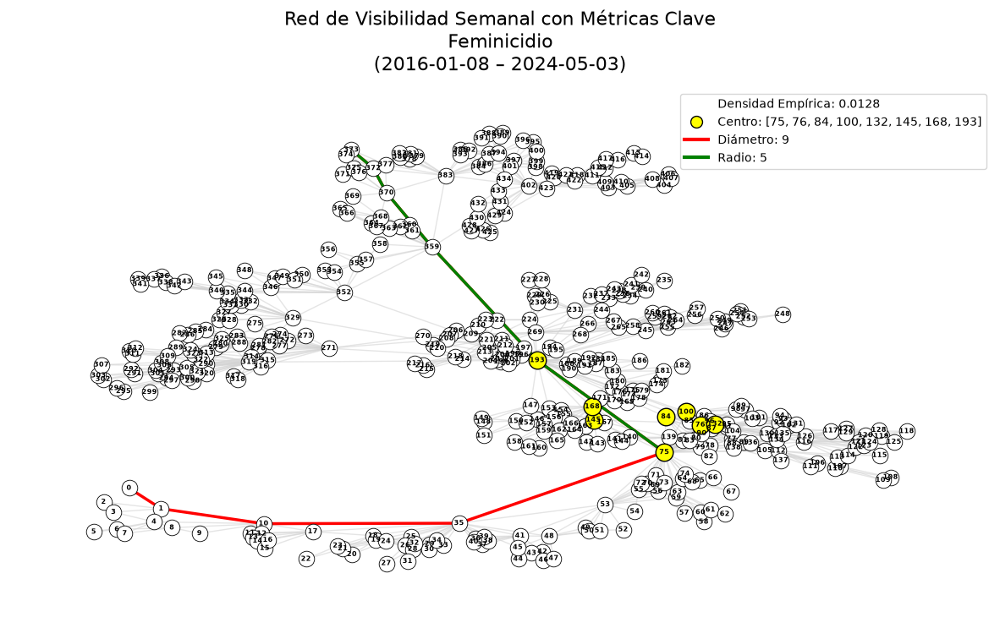

2026-10-07 07:56:56,928 - [plot_network] - INFO - Exito.


In [37]:
# [EJECUCIÓN] Extracción de métricas topológicas globales
# INPUT:  visibility_graph (nx.Graph)
# OUTPUT: topologia_global (dict)

try:
    graph_metrics = compute_graph_metrics(global_visibility_graph)

    logger.info(f"Densidad empírica: {graph_metrics['densidad_empirica']:.6f}")
    logger.info(f"Radio: {graph_metrics['radio']}")
    logger.info(f"Diámetro: {graph_metrics['diametro']}")
    logger.info(f"Centro: {graph_metrics['centro']}")
    logger.info(f"Nodos en camino diametral: {graph_metrics['nodos_diametro']}")
    logger.info(f"Nodos en camino radial: {graph_metrics['nodos_radio']}")
except Exception as err:
    logger.error(f"Fallo al calcular métricas topológicas: {err}")

# [EJECUCIÓN] Renderizado de red  con métricas
# INPUT:  visibility_graph (nx.Graph), graph_metrics (dict), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_network(global_visibility_graph, graph_metrics, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo al renderizar el gráfico topológico: {err}")

### Plot. Distribución de grados

<details>
<summary><b>Ejecución: Renderizado de la distribución de conectividad</b></summary>

<br>

Invoca `plot_degree_distribution` para graficar la secuencia decreciente de conexiones sobre `visibility_graph`.

**Variables de entrada**
* **`visibility_graph`** (`nx.Graph`): Red compleja generada.
* **`TARGET_CRIME`** (`str`): Constante global del delito analizado.

</details>

2026-10-07 07:56:56,940 - [plot_degree_distribution] - INFO - Preparando gráfico de distribución de grados


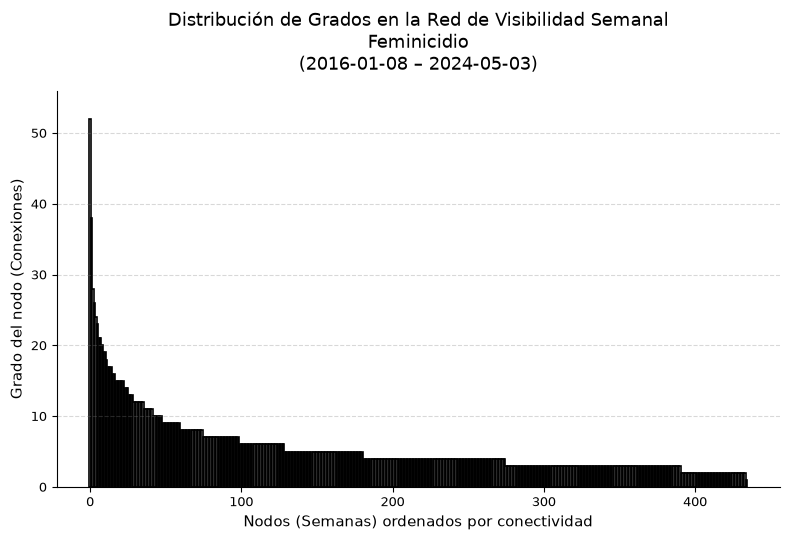

2026-10-07 07:56:57,485 - [plot_degree_distribution] - INFO - Exito.


In [38]:
# [EJECUCIÓN] Renderizado de distribución de grados
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_degree_distribution(global_visibility_graph, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo al graficar la distribución de grados: {err}")

### Plot. Ajuste de ley de potencia

<details>
<summary><b>Ejecución: Estimación y ajuste de Ley de Potencia</b></summary>

<br>

Invoca `plot_power_law_fit` para evaluar si la conectividad de `visibility_graph` exhibe invariancia de escala frente a la alternativa lognormal.

**Variables de entrada**
* **`visibility_graph`** (`nx.Graph`): Red compleja analizada.
* **`TARGET_CRIME`** (`str`): Delito bajo estudio.

</details>

2026-10-07 07:56:57,495 - [plot_power_law_fit] - INFO - Iniciando ajuste estadístico de Ley de Potencia


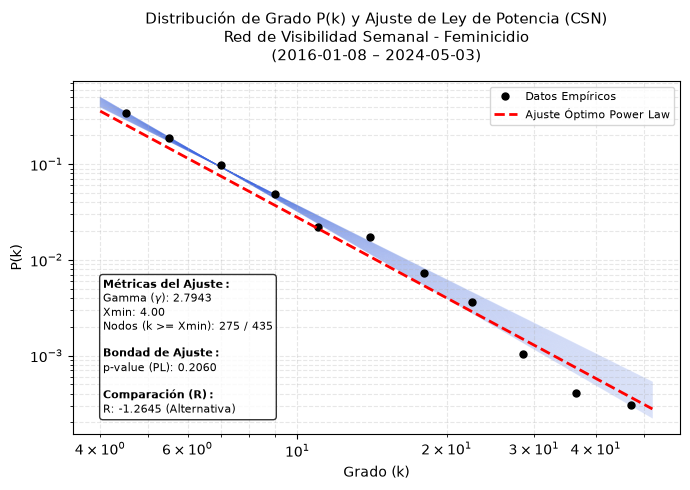

2026-10-07 07:56:58,281 - [plot_power_law_fit] - INFO - Exito.


In [39]:
# [EJECUCIÓN] Ajuste y evaluación de Ley de Potencia
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    plot_power_law_fit(global_visibility_graph, TARGET_CRIME)
except Exception as err:
    logger.error(f"Fallo en el ajuste de Ley de Potencia: {err}")

### Compara distribuciones de grado con modelos teoricos

<details>
<summary><b>Ejecución: Comparación multimodelo</b></summary>

<br>

Ejecuta `plot_model_comparison` para proyectar las curvas de distribución teóricas y genera la tabla comparativa de distancias euclidianas `df_model_distances`.

**Variables generadas**
* **`df_model_distances`** (`pd.DataFrame`): Métricas de bondad de ajuste por distancia euclidiana para cada familia de distribución evaluada.

</details>

2026-10-07 07:56:58,296 - [plot_model_comparison] - INFO - Iniciando comparacion multimodelo y calculo de distancias


c:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


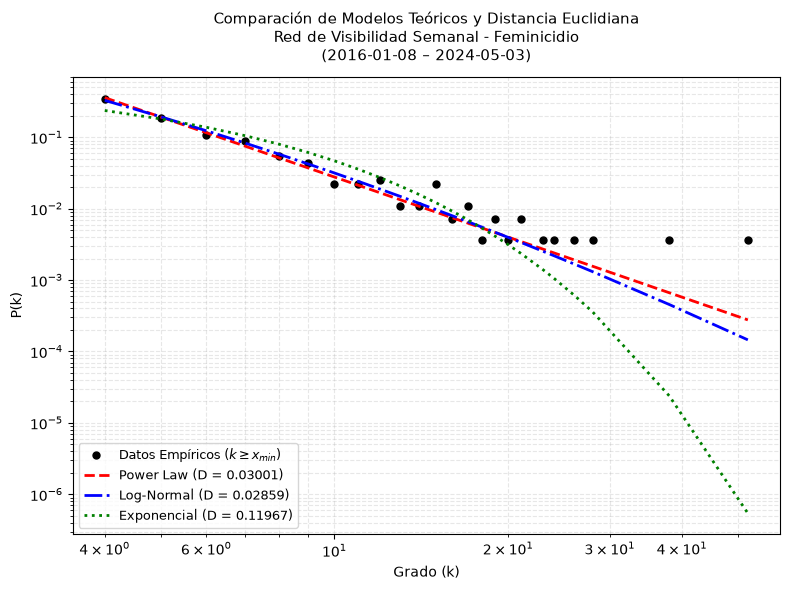

2026-10-07 07:56:58,894 - [plot_model_comparison] - INFO - EXITO.


,Modelo,Distancia Euclidiana
0,Log-Normal,0.028586
1,Ley de Potencia,0.030012
2,Exponencial,0.119674


In [40]:
# [EJECUCIÓN] Comparativa de modelos teóricos de grado
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: df_model_distances (pd.DataFrame)

try:
    df_model_distances = plot_model_comparison(global_visibility_graph, TARGET_CRIME)
    display(df_model_distances)
except Exception as err:
    logger.error(f"Fallo en la comparación de modelos: {err}")

### Plot. Análisis estadístico CSN

<details>
<summary><b>Ejecución: Protocolo estadístico CSN</b></summary>

<br>

Ejecuta `plot_csn_analysis` sobre `visibility_graph` para estimar los parámetros de máxima verosimilitud de la red y almacena los resultados en `csn_metrics`.

**Variables generadas**
* **`csn_metrics`** (`dict`): Diccionario con los parámetros formales $\gamma$, $x_{\min}$, $D_{KS}$ y el resultado del test relativo.

</details>

2026-10-07 07:56:58,909 - [plot_csn_analysis] - INFO - Iniciando análisis riguroso CSN


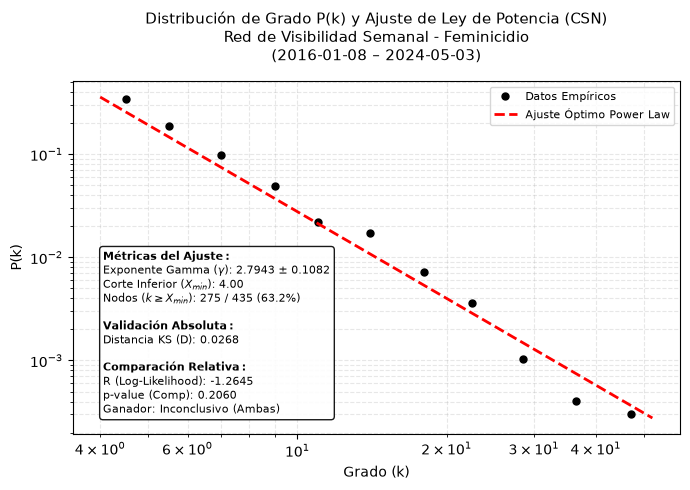

2026-10-07 07:56:59,416 - [plot_csn_analysis] - INFO - EXITO.
2026-10-07 07:56:59,417 - [<module>] - INFO - Veredicto CSN: Inconclusivo (Ambas)


In [41]:
# [EJECUCIÓN] Evaluación estadística bajo protocolo CSN
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: csn_metrics (dict)

try:
    csn_metrics = plot_csn_analysis(global_visibility_graph, TARGET_CRIME)
    logger.info(f"Veredicto CSN: {csn_metrics.get('veredicto')}")
except Exception as err:
    logger.error(f"Fallo en la evaluación CSN: {err}")

In [42]:
# Ejemplo de consumo directo y limpio:
catalogo_modelos = generate_benchmark_models(global_visibility_graph)
curva_empirica = simulate_node_removal_profile(global_visibility_graph, sorting_strategy="ataque")
print(curva_empirica)
print(catalogo_modelos)

[  2   3   4   5   6   7   8   8   9   9  11  12  13  14  15  16  17  18
  19  20  20  21  22  23  24  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  42  43  44  45  46  47  48  50  51  52  53  53
  54  55  56  57  58  59  60  61  62  63  63  63  64  65  66  66  67  68
  69  70  71  72  72  73  74  75  76  76  77  78  79  80  81  82  83  83
  84  85  86  87  88  89  90  91  91  91  92  92  91  91  91  92  93  94
  94  95  96  97  97  97  98  99 100 101 102 103 104 105 106 107 108 109
 110 111 111 112 113 114 114 115 116 117 117 118 119 120 121 121 121 122
 123 123 124 125 126 126 126 126 126 126 126 125 126 127 128 128 129 129
 129 130 130 130 130 131 131 131 130 131 132 133 134 135 135 136 137 138
 139 140 141 140 140 139 138 137 136 136 135 135 136 135 135 134 134 135
 136 136 136 137 137 137 137 137 137 137 137 138 138 139 138 139 138 137
 138 137 136 135 134 133 132 131 132 133 133 132 131 132 132 133 133 133
 133 133 133 132 131 132 132 131 132 132 132 132 13

### Plot. Cuadrícula de resiliencia

<details>
<summary><b>Ejecución: Evaluación de resiliencia en cuadrícula comparativa</b></summary>

<br>

Ejecuta `evaluate_network_resilience_grid` sobre `visibility_graph` para trazar los perfiles de remoción de todos los modelos bajo ataque y falla, almacenando los invariantes base de la ventana.

**Variables generadas**
* **`df_resilience_scalars`** (`pd.DataFrame`): Tabla con los valores escalares calculados ($N$, $m$, $\langle k \rangle$, $p$) para la ventana temporal activa.

</details>

2026-10-07 07:56:59,656 - [evaluate_network_resilience_grid] - INFO - Iniciando evaluación comparada de resiliencia estructural


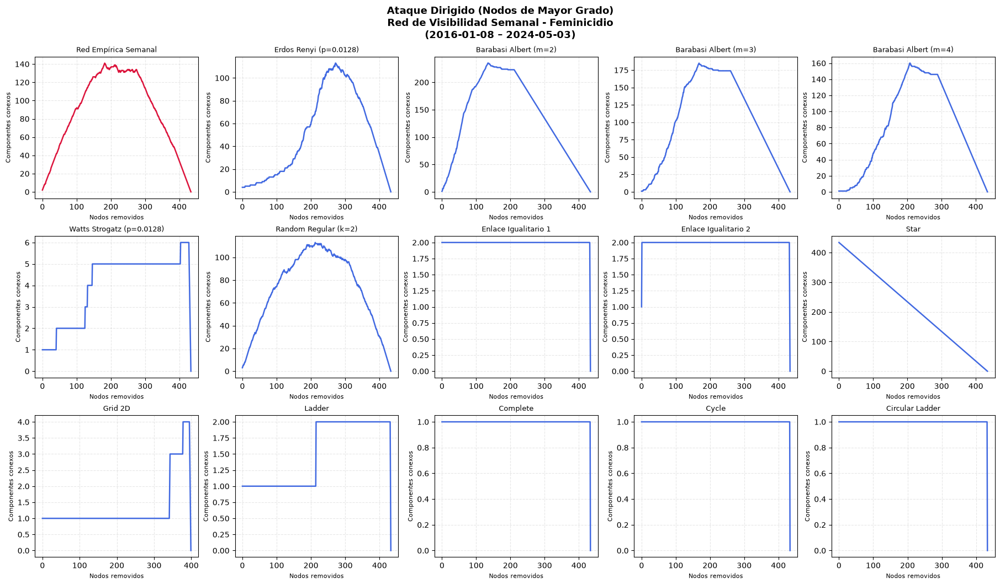

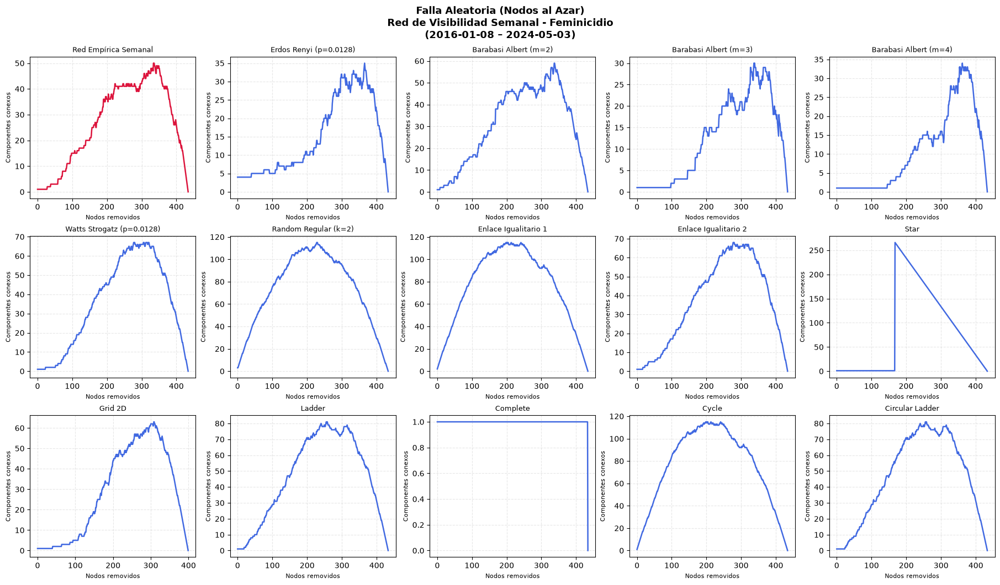

2026-10-07 07:57:04,856 - [evaluate_network_resilience_grid] - INFO - EXITO.
2026-10-07 07:57:04,864 - [<module>] - INFO - Resumen de parámetros base calculados:
              Métrica      Valor
0     Nodos (Semanas)   435.0000
1         Enlaces (m)  1210.0000
2  Grado Promedio (k)     5.5632
3        Densidad (p)     0.0128


,Métrica,Valor
0,Nodos (Semanas),435.0000
1,Enlaces (m),1210.0000
2,Grado Promedio (k),5.5632
3,Densidad (p),0.0128


In [43]:
# [EJECUCIÓN] Evaluación de resiliencia estructural en cuadrícula comparativa
# INPUT:  visibility_graph (nx.Graph), CRIME_NAME (str)
# OUTPUT: df_resilience_scalars (pd.DataFrame)

try:
    df_resilience_scalars = evaluate_network_resilience_grid(grafo=global_visibility_graph, crime_name=TARGET_CRIME)
    logger.info(
        f"Resumen de parámetros base calculados:\n{df_resilience_scalars}"
    )
    display(df_resilience_scalars)
except Exception as err:
    logger.error(
        f"Fallo al ejecutar la cuadrícula de resiliencia estructural: {err}"
    )

### Plot. Modelo más cercano

<details>
<summary><b>Ejecución: Contraste con el modelo sintético óptimo</b></summary>

<br>

Ejecuta `plot_closest_resilience_models` sobre `visibility_graph` para determinar el modelo sintético que mejor aproxima la curva de fragmentación empírica y renderizar los paneles comparativos.

**Variables generadas**
* **`df_closest_models`** (`pd.DataFrame`): Tabla con los modelos teóricos de menor distancia $D$ hallados para ataque y falla.

</details>

2026-10-07 07:57:04,879 - [plot_closest_resilience_models] - INFO - Identificando modelos sintéticos más cercanos por distancia estructural


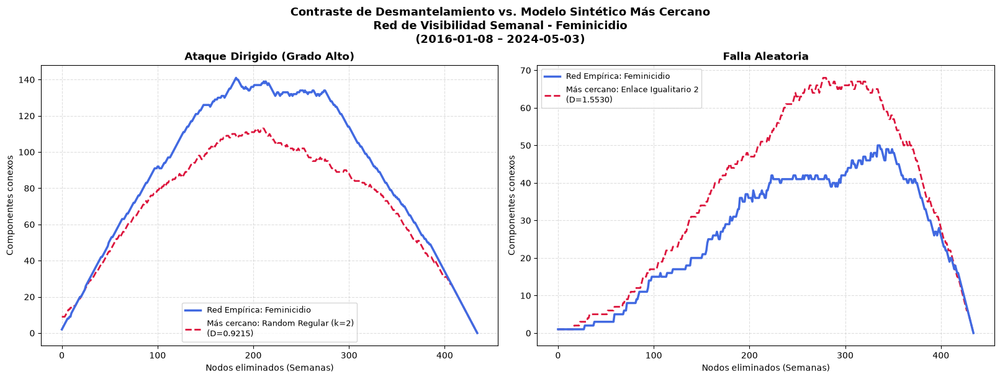

2026-10-07 07:57:07,067 - [plot_closest_resilience_models] - INFO - EXITO.
2026-10-07 07:57:07,076 - [<module>] - INFO - Modelos teóricos con menor distancia hallados:
                     Estrategia                Modelo  Distancia (D)  \
0  Ataque Dirigido (Grado Alto)  Random Regular (k=2)         0.9215   
1               Falla Aleatoria  Enlace Igualitario 2         1.5530   

  Parametro k Parametro p  
0           2         N/A  
1         N/A         N/A  


,Estrategia,Modelo,Distancia (D),Parametro k,Parametro p
0,Ataque Dirigido (Grado Alto),Random Regular (k=2),0.9215,2,N/A
1,Falla Aleatoria,Enlace Igualitario 2,1.5530,N/A,N/A


In [44]:
# [EJECUCIÓN] Búsqueda del modelo sintético con menor distancia estructural
# INPUT:  visibility_graph (nx.Graph), CRIME_NAME (str)
# OUTPUT: df_closest_models (pd.DataFrame)

try:
    df_closest_models = plot_closest_resilience_models(grafo=global_visibility_graph, crime_name=TARGET_CRIME)
    logger.info(
        f"Modelos teóricos con menor distancia hallados:\n{df_closest_models}"
    )
    display(df_closest_models)
except Exception as err:
    logger.error(f"Fallo al contrastar modelos sintéticos cercanos: {err}")

## 5. Ventanas Moviles

### Exec. Inicializa Ventanas Moviles

In [2]:
# [EJECUCIÓN] Construcción de grafos mediante Rolling Window
# INPUT:  df_nodes (pd.DataFrame), window_size (int), step_size (int)
# OUTPUT: rolling_graphs (list[dict])

# try:
#     rolling_graphs = build_rolling_graphs(
#         df_nodes,
#         window_size=52,
#         step_size=4,
#     )
try:
    rolling_graphs = build_rolling_graphs(df_nodes)
except Exception as err:
    logger.error(f"Fallo en la construcción de grafos por ventana: {err}")

NameError: name 'logger' is not defined

### Metricas de Ventanas Moviles

#### Exec. Genera Metricas de Ventanas Moviles

<details>
<summary><b>Ejecución: Extracción de Métricas sobre Ventanas Deslizantes</b></summary>

<br>

Aplica de forma secuencial la función `extract_window_metrics` sobre la colección de redes `rolling_graphs` y consolida los resultados en la serie temporal tabular `df_rolling_metrics`.

**Variables de entrada:**
* **`rolling_graphs`** (`list[dict]`): Secuencia de ventanas temporales con sus respectivos subgrafos de visibilidad.

**Variables generadas:**
* **`df_rolling_metrics`** (`pd.DataFrame`): Serie temporal de invariantes estructurales indexada por la fecha de corte de cada ventana móvil.

</details>

In [ ]:
# [EJECUCIÓN] Extracción y consolidación de invariantes por ventana deslizante
# INPUT:  rolling_graphs (list[dict])
# OUTPUT: df_rolling_metrics (pd.DataFrame)

try:
    logger.info(
        f"Iniciando extracción vectorial de métricas sobre {len(rolling_graphs)} ventanas"
    )

    df_rolling_metrics = pd.DataFrame(
        [
            extract_window_metrics(
                item["graph"],
                item["window_id"],
                item["start_date"],
                item["end_date"],
            )
            for item in rolling_graphs
        ]
    )

    logger.info(
        f"Métricas consolidadas exitosamente: {df_rolling_metrics.shape[0]} registros, {df_rolling_metrics.shape[1]} columnas."
    )
    logger.info("EXITO.")
    display(df_rolling_metrics.head())

except Exception as err:
    logger.error(f"Fallo en la extracción de métricas de ventanas: {err}")
    logger.info("FALLO.")

2026-10-07 07:57:07,222 - [<module>] - INFO - Iniciando extracción vectorial de métricas sobre 32 ventanas
2026-10-07 07:57:07,936 - [<module>] - INFO - Métricas consolidadas exitosamente: 32 registros, 15 columnas.
2026-10-07 07:57:07,937 - [<module>] - INFO - EXITO.


,window_id,start_date,end_date,fecha_corte,nodos,enlaces,grado_promedio,densidad,clustering,camino_medio,diametro,radio,gamma_powerlaw,dist_eucl_pl,dist_eucl_exp
0,0,2016-01-08,2016-12-30,2016-12-30,52,131,5.0385,0.09879,0.7535,2.9238,6,3,2.5870,0.12978,0.09318
1,1,2016-04-01,2017-03-24,2017-03-24,52,131,5.0385,0.09879,0.7651,2.8695,6,3,2.8998,0.12466,0.09827
2,2,2016-06-24,2017-06-16,2017-06-16,52,147,5.6538,0.11086,0.7766,2.6456,5,3,2.7314,0.11018,0.10083
3,3,2016-09-16,2017-09-08,2017-09-08,52,139,5.3462,0.10483,0.7743,2.7971,5,3,2.7875,0.11733,0.09530
4,4,2016-12-09,2017-12-01,2017-12-01,52,140,5.3846,0.10558,0.7602,2.5837,4,2,2.7209,0.14515,0.10645


#### Exporta métricas a Excel

<details>
<summary><b>Ejecución: Genera archivo local de métricas</b></summary>

<br>

Ejecuta `export_df_to_local_spreadsheet` para serializar `df_rolling_metrics` en un archivo `.xlsx` local, listo para ser consumido en local o arrastrado a Google Drive.

**Variables generadas**
* **`local_spreadsheet_path`** (`str`): Ruta del archivo Excel persistido en el almacenamiento local.

</details>

In [ ]:
# [EJECUCIÓN] Generación de archivo de hoja de cálculo offline
# INPUT:  df_rolling_metrics (pd.DataFrame), TARGET_CRIME (str)
# OUTPUT: local_spreadsheet_path (str)

# Sanitizar el nombre del delito para crear un nombre de archivo válido
crime_slug = (
    TARGET_CRIME.lower()
    .replace(" ", "_")
    .replace("/", "_")
    .replace("\\", "_")
)
OUTPUT_EXCEL = f"./data/metricas_rolling_{crime_slug}.xlsx"

try:
    local_spreadsheet_path = export_df_to_local_spreadsheet(
        df=df_rolling_metrics,
        output_path=OUTPUT_EXCEL,
        sheet_name="rolling_w52",
    )
    print(f"Archivo listo para usar en: {local_spreadsheet_path}")
except Exception as err:
    logger.error(f"Fallo al generar archivo Excel local: {err}")
    logger.info("FALLO.")

2026-10-07 07:57:07,953 - [export_df_to_local_spreadsheet] - INFO - Iniciando exportación local a hoja de cálculo: './data/metricas_rolling_feminicidio.xlsx'
2026-10-07 07:57:07,991 - [export_df_to_local_spreadsheet] - INFO - Archivo generado exitosamente en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\metricas_rolling_feminicidio.xlsx
2026-10-07 07:57:07,991 - [export_df_to_local_spreadsheet] - INFO - EXITO.
Archivo listo para usar en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\metricas_rolling_feminicidio.xlsx


#### Plot. Evolución de métricas

<details>
<summary><b>Visualización: Evolución Temporal de metricas de Red</b></summary>

<br>

Genera un tablero de 4 subgráficos alineados cronológicamente para monitorear la trayectoria temporal de las propiedades estructurales de la red a lo largo de las ventanas móviles.

**Dimensiones analizadas**
* **Conectividad media ($\langle k \rangle$):** Evolución del número promedio de conexiones por semana.
* **Separación geodésica media ($L$):** Distancia promedio (saltos de visibilidad) entre todos los pares de nodos.
* **Coeficiente de agrupamiento ($C$):** Proporción de enlaces efectivos entre los vecinos de cada nodo (densidad de triángulos locales).
* **Régimen de distribución ($\Delta D = D_{\text{Exp}} - D_{\text{PL}}$):** Diagnóstico de proximidad a Ley de Potencia frente a Exponencial en la cola ($>0$ indica ajuste superior a Ley de Potencia).

**Parámetros de entrada**
* **`df_rolling_metrics`** (`pd.DataFrame`): Serie temporal de descriptores calculados por ventana.
* **`TARGET_CRIME`** (`str`): Identificador del delito para el encabezado de la figura.
* **`WINDOW_SIZE`** (`int`): Longitud de la ventana móvil en semanas.

**Salida**
* **Figura Matplotlib**: Panel 2×2 con formato de fechas optimizado (`ConciseDateFormatter`) y espaciado desacoplado (`constrained_layout`).

</details>

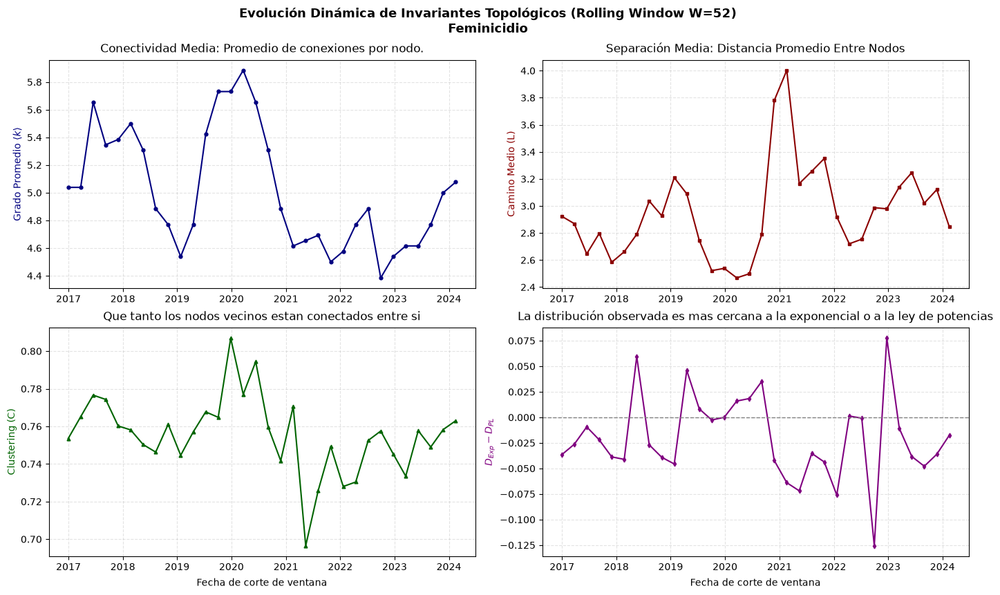

In [ ]:
# [VISUALIZACIÓN] Evolución temporal con espaciado vertical corregido
# INPUT:  df_rolling_metrics (pd.DataFrame), TARGET_CRIME (str)
# OUTPUT: None (figura 2x2)

# Usamos constrained_layout=True en lugar de tight_layout para evitar colisiones entre títulos y ticks
fig, axes = plt.subplots(
    2, 2, figsize=(14, 8.5), dpi=100, constrained_layout=True
)

fechas = pd.to_datetime(df_rolling_metrics["fecha_corte"])

# 1. Conectividad: Grado Promedio
axes[0, 0].plot(
    fechas,
    df_rolling_metrics["grado_promedio"],
    "o-",
    color="navy",
    markersize=3.5,
)
axes[0, 0].set_ylabel(r"Grado Promedio $\langle k \rangle$", color="navy")
axes[0, 0].grid(True, linestyle="--", alpha=0.35)
axes[0, 0].set_title("Conectividad Media: Promedio de conexiones por nodo.", pad=8)

# 2. Separación Geodésica: Camino Medio
axes[0, 1].plot(
    fechas,
    df_rolling_metrics["camino_medio"],
    "s-",
    color="darkred",
    markersize=3.5,
)
axes[0, 1].set_ylabel("Camino Medio (L)", color="darkred")
axes[0, 1].grid(True, linestyle="--", alpha=0.35)
axes[0, 1].set_title("Separación Media: Distancia Promedio Entre Nodos", pad=8)

# 3. Modularidad Local: Coeficiente de Agrupamiento
axes[1, 0].plot(
    fechas,
    df_rolling_metrics["clustering"],
    "^-",
    color="darkgreen",
    markersize=3.5,
)
axes[1, 0].set_ylabel("Clustering (C)", color="darkgreen")
axes[1, 0].set_xlabel("Fecha de corte de ventana", labelpad=6)
axes[1, 0].grid(True, linestyle="--", alpha=0.35)
axes[1, 0].set_title("Que tanto los nodos vecinos estan conectados entre si", pad=8)

# 4. Régimen Dinámico: Brecha de Distancias Euclidianas
brecha = df_rolling_metrics["dist_eucl_exp"] - df_rolling_metrics["dist_eucl_pl"]
axes[1, 1].plot(fechas, brecha, "d-", color="purple", markersize=3.5)
axes[1, 1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1, 1].set_ylabel(r"$D_{Exp} - D_{PL}$", color="purple")
axes[1, 1].set_xlabel("Fecha de corte de ventana", labelpad=6)
axes[1, 1].grid(True, linestyle="--", alpha=0.35)
axes[1, 1].set_title("La distribución observada es mas cercana a la exponencial o a la ley de potencias", pad=8)

# Formateo explícito de fechas para cada uno de los 4 ejes
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
formatter = mdates.ConciseDateFormatter(locator)

for ax in axes.flat:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)
    # Forzar que se muestren las marcas de fechas en todos los plots sin solaparse
    ax.tick_params(axis="x", labelbottom=True, rotation=0)

fig.suptitle(
    f"Evolución Dinámica de Invariantes Topológicos (Rolling Window W={WINDOW_SIZE})\n"
    f"{TARGET_CRIME.title()}",
    fontsize=13,
    fontweight="bold",
)

plt.show()

### EXEC. Analisis de Resiliencia

In [ ]:
# [EJECUCIÓN] Procesamiento de resiliencia de todas las ventanas
# INPUT:  rolling_graphs (list[dict]), TARGET_CRIME (str),
#         experiment_id, window_size, step_size, executed_at
# OUTPUT: df_resilience_test_report (pd.DataFrame)

experiment_id = uuid4().hex
executed_at = datetime.now(timezone.utc).isoformat()

# Deben coincidir con los parámetros usados para construir rolling_graphs.
window_size = WINDOW_SIZE
step_size = STEP_SIZE

try:
    df_resilience_test_report = extract_rolling_resilience_scalars(
        rolling_graphs=rolling_graphs,
        crime_name=TARGET_CRIME,
        experiment_id=experiment_id,
        window_size=window_size,
        step_size=step_size,
        executed_at=executed_at,
        guardar_curvas=True,
    )

    # Nombre del delito válido para carpetas y archivos.
    nombre_delito = re.sub(r'[<>:"/\\|?*\x00-\x1f]',"_",TARGET_CRIME,).strip().rstrip(". ")

    # Crear la carpeta del delito si no existe.
    carpeta_delito = REPORT_PATH / nombre_delito
    carpeta_delito.mkdir(parents=True, exist_ok=True)

    # Guardar un archivo por experimento.
    ruta_reporte = carpeta_delito / f"{nombre_delito}_{experiment_id}.pkl"
    df_resilience_test_report.to_pickle(ruta_reporte)

    logger.info(f"Reporte guardado en: {ruta_reporte.resolve()}")

    logger.info(
        f"Experimento {experiment_id}: "
        f"{df_resilience_test_report['window_id'].nunique() if not df_resilience_test_report.empty else 0} "
        f"ventanas evaluadas, "
        f"{len(df_resilience_test_report)} comparaciones registradas."
    )

    display(df_resilience_test_report.head())

except Exception as err:
    logger.error(
        f"Fallo en el experimento {experiment_id}: {err}"
    )

2026-10-07 07:57:08,815 - [extract_rolling_resilience_scalars] - INFO - Experimento 44b373bf4b294df3b151d11dbd0dccc7: comparación de modelos sobre 32 ventanas | W=52, S=12
2026-10-07 07:57:10,488 - [extract_rolling_resilience_scalars] - INFO - EXITO. Experimento 44b373bf4b294df3b151d11dbd0dccc7: 896 comparaciones conservadas.
2026-10-07 07:57:10,492 - [<module>] - INFO - Reporte guardado en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\FEMINICIDIO\FEMINICIDIO_44b373bf4b294df3b151d11dbd0dccc7.pkl
2026-10-07 07:57:10,493 - [<module>] - INFO - Experimento 44b373bf4b294df3b151d11dbd0dccc7: 32 ventanas evaluadas, 896 comparaciones registradas.


,experiment_id,window_size,step_size,executed_at,window_id,crime_name,start_date,end_date,nodes,edges,...,modelo,familia_modelo,distancia,seed_remocion,nodes_modelo,edges_modelo,density_modelo,curva_empirica,curva_modelo,ranking
0,44b373bf4b294df3b151d11dbd0dccc7,52,12,2026-10-07T13:57:08.815013+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=3),Barabasi Albert,0.906702,42,52,147,0.110860,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 1, 1, 1, 3, 3, 4, 4, 5, 6, 7, 10, 14, 16, ...",1
1,44b373bf4b294df3b151d11dbd0dccc7,52,12,2026-10-07T13:57:08.815013+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Random Regular (k=2),Random Regular,1.085965,42,52,52,0.039216,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(2, 3, 4, 5, 5, 6, 7, 8, 9, 10, 10, 11, 12, 11...",2
2,44b373bf4b294df3b151d11dbd0dccc7,52,12,2026-10-07T13:57:08.815013+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=2),Barabasi Albert,1.160991,42,52,100,0.075415,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 3, 6, 10, 14, 14, 17, 21, 22, 23, 25, 27, ...",3
3,44b373bf4b294df3b151d11dbd0dccc7,52,12,2026-10-07T13:57:08.815013+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Erdos Renyi (p=0.0988),Erdos Renyi,1.305770,42,52,132,0.099548,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(2, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 5, 6, ...",4
4,44b373bf4b294df3b151d11dbd0dccc7,52,12,2026-10-07T13:57:08.815013+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=4),Barabasi Albert,1.475419,42,52,192,0.144796,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 1, 1, 1, 1, 1, 1, 1, 3, 5, 6, 6, 6, 7, 8, ...",5


In [ ]:
# [EJECUCIÓN] Transiciones de modelos más cercanos
# INPUT:  df_resilience_test_report (pd.DataFrame), TARGET_CRIME (str),
#         WINDOW_SIZE (int), STEP_SIZE (int)
# OUTPUT: None

try:
    plot_rolling_resilience_categorical_transitions123(
        df_resilience_test_report=df_resilience_test_report,
        crime_name=TARGET_CRIME,
        window_size=WINDOW_SIZE,
        step_size=STEP_SIZE,
    )
except Exception as err:
    logger.error(f"Fallo al graficar las transiciones de modelos: {err}")

NameError: name 'logger' is not defined

#### Solo primer lugar

2026-10-07 07:57:11,319 - [plot_rolling_resilience_categorical_transitions] - INFO - Iniciando visualización categórica de transición entre modelos


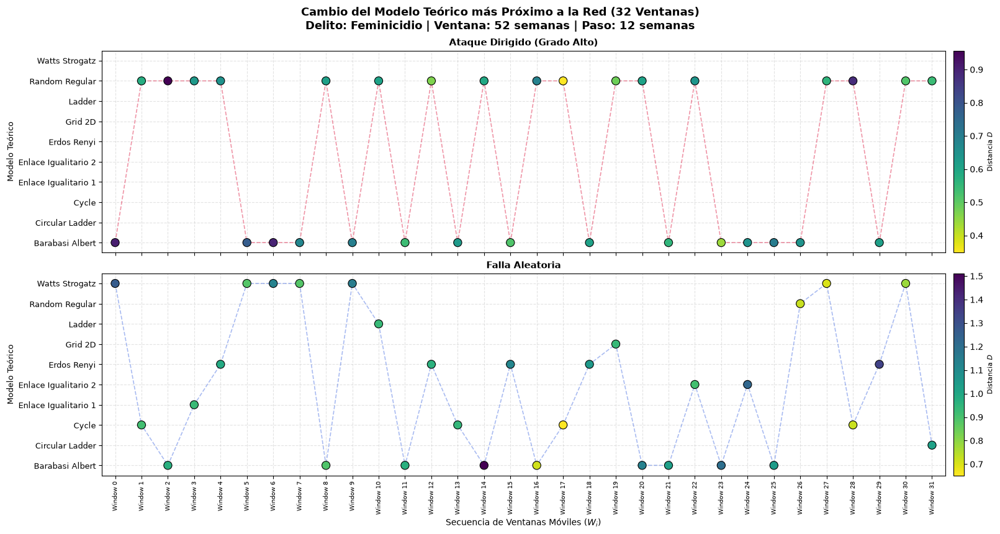

2026-10-07 07:57:12,011 - [plot_rolling_resilience_categorical_transitions] - INFO - EXITO.


In [ ]:
# [EJECUCIÓN] Transiciones de modelos más cercanos
# INPUT:  df_resilience_test_report (pd.DataFrame), TARGET_CRIME (str),
#         WINDOW_SIZE (int), STEP_SIZE (int)
# OUTPUT: None

try:
    plot_rolling_resilience_categorical_transitions(
        df_resilience_test_report=df_resilience_test_report,
        crime_name=TARGET_CRIME,
        window_size=WINDOW_SIZE,
        step_size=STEP_SIZE,
    )
except Exception as err:
    logger.error(f"Fallo al graficar las transiciones de modelos: {err}")

## 6. Analisis de un Solo Grafo [To Do]

In [52]:
print(len(rolling_graphs))

32


In [53]:
# [EJECUCIÓN] Extracción segura de subgrafo individual desde rolling_graphs
# INPUT:  rolling_graphs (list[dict]), SELECTED_WINDOW_IDX (int)
# OUTPUT: visibility_graph (nx.Graph)

SELECTED_WINDOW_IDX = 25

try:
    total_ventanas = len(rolling_graphs)
    logger.info(
        f"Total de ventanas disponibles en rolling_graphs: {total_ventanas} (indices válidos: 0 a {total_ventanas - 1})"
    )

    if total_ventanas == 0:
        raise ValueError("La lista 'rolling_graphs' está vacía.")

    # Validación estricta de límites de indexación
    if not (0 <= SELECTED_WINDOW_IDX < total_ventanas):
        raise IndexError(
            f"SELECTED_WINDOW_IDX={SELECTED_WINDOW_IDX} fuera de rango. "
            f"Debe estar entre 0 y {total_ventanas - 1}."
        )

    # Extracción del grafo y metadatos asociados
    selected_window = rolling_graphs[SELECTED_WINDOW_IDX]
    visibility_graph = selected_window["graph"]

    f_inicio = selected_window["start_date"].strftime("%Y-%m-%d")
    f_fin = selected_window["end_date"].strftime("%Y-%m-%d")

    logger.info(
        f"Ventana [{SELECTED_WINDOW_IDX}] extraída exitosamente: "
        f"{f_inicio} a {f_fin} | "
        f"|V|={visibility_graph.number_of_nodes()} nodos, |E|={visibility_graph.number_of_edges()} aristas"
    )
    logger.info("EXITO.")

except (IndexError, ValueError) as err:
    logger.error(f"Error de validación en índice de ventana: {err}")
    logger.info("FALLO.")
except Exception as err:
    logger.error(f"Fallo inesperado al extraer el grafo de la ventana: {err}")
    logger.info("FALLO.")

2026-10-07 07:57:12,050 - [<module>] - INFO - Total de ventanas disponibles en rolling_graphs: 32 (indices válidos: 0 a 31)
2026-10-07 07:57:12,052 - [<module>] - INFO - Ventana [25] extraída exitosamente: 2021-10-08 a 2022-09-30 | |V|=52 nodos, |E|=114 aristas
2026-10-07 07:57:12,054 - [<module>] - INFO - EXITO.


## 7. Experimentos Resiliencia [Work In Progress]

### Ejecuta Manualmente un Experimento de Resiliencia [Just for Test]

In [54]:
# [SANDBOX] Ejecución manual de un experimento de resiliencia
# INPUT:  df_nodes, TARGET_CRIME, REPORT_PATH, window_size, step_size
# OUTPUT: df_resilience_test_report y archivo .pkl

window_size = 52
step_size = 1

experiment_id = uuid4().hex
executed_at = datetime.now(timezone.utc).isoformat()

try:
    # 1. Construir los grafos con los parámetros de este experimento.
    rolling_graphs = build_rolling_graphs(
        df_nodes,
        window_size=window_size,
        step_size=step_size,
    )

    if not rolling_graphs:
        raise ValueError("No se generaron grafos por ventana.")

    # 2. Calcular todas las comparaciones una sola vez.
    df_resilience_test_report = extract_rolling_resilience_scalars(
        rolling_graphs=rolling_graphs,
        crime_name=TARGET_CRIME,
        experiment_id=experiment_id,
        window_size=window_size,
        step_size=step_size,
        executed_at=executed_at,
        guardar_curvas=True,
    )

    if df_resilience_test_report.empty:
        raise ValueError("El reporte de resiliencia está vacío.")

    # 3. Crear la carpeta del delito.
    nombre_delito = re.sub(
        r'[<>:"/\\|?*\x00-\x1f]',
        "_",
        TARGET_CRIME,
    ).strip().rstrip(". ")

    carpeta_delito = REPORT_PATH / nombre_delito
    carpeta_delito.mkdir(parents=True, exist_ok=True)

    # 4. Guardar el reporte del experimento.
    ruta_reporte = carpeta_delito / f"{nombre_delito}_{experiment_id}.pkl"
    df_resilience_test_report.to_pickle(ruta_reporte)

    logger.info(f"Reporte guardado en: {ruta_reporte.resolve()}")

    logger.info(
        f"Experimento {experiment_id} | "
        f"W={window_size}, S={step_size} | "
        f"{df_resilience_test_report['window_id'].nunique()} "
        f"ventanas evaluadas, "
        f"{len(df_resilience_test_report)} comparaciones registradas."
    )

    display(df_resilience_test_report.head())

except Exception as err:
    logger.error(f"Fallo en el experimento {experiment_id}: {err}")
    raise

2026-10-07 07:57:12,083 - [generate_rolling_windows] - INFO - Inicializando generador de rolling window (W=52, S=1)
2026-10-07 07:57:13,618 - [generate_rolling_windows] - INFO - EXITO.
2026-10-07 07:57:13,619 - [build_rolling_graphs] - INFO - Resumen Rolling Window: 384 grafos generados | W=52, S=1 | Rango: 2016-01-08 -> 2024-05-03 | Nodos por ventana: 52
2026-10-07 07:57:13,620 - [extract_rolling_resilience_scalars] - INFO - Experimento 0dbce2b10a8e487881cf1f16a5e19b5b: comparación de modelos sobre 384 ventanas | W=52, S=1
2026-10-07 07:57:27,660 - [extract_rolling_resilience_scalars] - INFO - EXITO. Experimento 0dbce2b10a8e487881cf1f16a5e19b5b: 10752 comparaciones conservadas.
2026-10-07 07:57:27,680 - [<module>] - INFO - Reporte guardado en: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-delito-Semanal\data\reports\FEMINICIDIO\FEMINICIDIO_0dbce2b10a8e487881cf1f16a5e19b5b.pkl
2026-10-07 07:57:27,682 - [<module>] - INFO - Experimento 0dbce2b10a8e4

,experiment_id,window_size,step_size,executed_at,window_id,crime_name,start_date,end_date,nodes,edges,...,modelo,familia_modelo,distancia,seed_remocion,nodes_modelo,edges_modelo,density_modelo,curva_empirica,curva_modelo,ranking
0,0dbce2b10a8e487881cf1f16a5e19b5b,52,1,2026-10-07T13:57:12.083161+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=2),Barabasi Albert,1.017868,42,52,100,0.075415,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 1, 2, 4, 6, 8, 12, 14, 16, 19, 20, 21, 22,...",1
1,0dbce2b10a8e487881cf1f16a5e19b5b,52,1,2026-10-07T13:57:12.083161+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Random Regular (k=2),Random Regular,1.051810,42,52,52,0.039216,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 2, 3, 4, 5, 6, 7, 7, 8, 9, 9, 10, 11, 11, ...",2
2,0dbce2b10a8e487881cf1f16a5e19b5b,52,1,2026-10-07T13:57:12.083161+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Erdos Renyi (p=0.0988),Erdos Renyi,1.327954,42,52,125,0.094268,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 5, 6, 6, ...",3
3,0dbce2b10a8e487881cf1f16a5e19b5b,52,1,2026-10-07T13:57:12.083161+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=3),Barabasi Albert,1.437196,42,52,147,0.110860,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 3, 6, 7, ...",4
4,0dbce2b10a8e487881cf1f16a5e19b5b,52,1,2026-10-07T13:57:12.083161+00:00,0,FEMINICIDIO,2016-01-08,2016-12-30,52,131,...,Barabasi Albert (m=4),Barabasi Albert,1.937223,42,52,192,0.144796,"(2, 3, 4, 4, 5, 6, 8, 9, 10, 11, 11, 11, 12, 1...","(2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, ...",5


### Ejecuta Multiples Experimentos de Resiliencia

#### Define las Combinaciones

In [55]:
combinaciones = [
    (12, 1),
    (12, 4),
    (12, 12),
    (26, 1),
    (26, 4),
    (26, 12),
    (52, 1),
    (52, 4),
    (52, 12),
    (104, 1),
    (104, 4),
    (104, 12),
]

##### Realiza los Experimentos y genera los archivos

In [56]:
# [SANDBOX] Ejecución de múltiples experimentos de resiliencia
# INPUT:  df_nodes, TARGET_CRIME, REPORT_PATH
# OUTPUT: Un archivo .pkl por combinación y df_experiments_summary



# Crear una sola vez la carpeta del delito.
nombre_delito = re.sub(
    r'[<>:"/\\|?*\x00-\x1f]',
    "_",
    TARGET_CRIME,
).strip().rstrip(". ")

if not nombre_delito:
    raise ValueError("El nombre del delito no permite crear una carpeta.")

carpeta_delito = Path(REPORT_PATH) / nombre_delito
carpeta_delito.mkdir(parents=True, exist_ok=True)

resumen_experimentos = []

for numero, (window_size, step_size) in enumerate(combinaciones, start=1):
    experiment_id = uuid4().hex
    executed_at = datetime.now(timezone.utc).isoformat()

    resumen = {
        "experiment_id": experiment_id,
        "crime_name": TARGET_CRIME,
        "window_size": window_size,
        "step_size": step_size,
        "traslape_pct": round(
            100 * (1 - step_size / window_size),
            2,
        ),
        "executed_at": executed_at,
        "ventanas": 0,
        "comparaciones": 0,
        "archivo": None,
        "estado": "ERROR",
        "error": None,
    }

    logger.info(
        f"Experimento {numero}/{len(combinaciones)} | "
        f"W={window_size}, S={step_size} | "
        f"ID={experiment_id}"
    )

    try:
        # 1. Construir los grafos de esta combinación.
        grafos_experimento = build_rolling_graphs(
            df_nodes,
            window_size=window_size,
            step_size=step_size,
        )

        if not grafos_experimento:
            raise ValueError("No se generaron grafos por ventana.")

        # 2. Calcular todas las comparaciones una sola vez.
        reporte_experimento = extract_rolling_resilience_scalars(
            rolling_graphs=grafos_experimento,
            crime_name=TARGET_CRIME,
            experiment_id=experiment_id,
            window_size=window_size,
            step_size=step_size,
            executed_at=executed_at,
            guardar_curvas=True,
        )

        if reporte_experimento.empty:
            raise ValueError("El reporte de resiliencia está vacío.")

        # 3. Guardar un archivo exclusivo para este experimento.
        ruta_reporte = carpeta_delito / (
            f"{nombre_delito}_"
            f"W{window_size}_S{step_size}_"
            f"{experiment_id}.pkl"
        )

        reporte_experimento.to_pickle(ruta_reporte)

        resumen.update({
            "ventanas": reporte_experimento["window_id"].nunique(),
            "comparaciones": len(reporte_experimento),
            "archivo": str(ruta_reporte.resolve()),
            "estado": "EXITO",
        })

        logger.info(
            f"EXITO | W={window_size}, S={step_size} | "
            f"{resumen['ventanas']} ventanas | "
            f"{resumen['comparaciones']} comparaciones | "
            f"Archivo: {ruta_reporte.resolve()}"
        )

    except Exception as err:
        resumen["error"] = str(err)

        logger.exception(
            f"Fallo en el experimento {experiment_id} | "
            f"W={window_size}, S={step_size}"
        )

    resumen_experimentos.append(resumen)

# 4. Mostrar el estado de las nueve ejecuciones.
df_experiments_summary = pd.DataFrame(resumen_experimentos)

display(df_experiments_summary)

logger.info(
    f"Lote finalizado: "
    f"{df_experiments_summary['estado'].eq('EXITO').sum()} exitosos, "
    f"{df_experiments_summary['estado'].eq('ERROR').sum()} fallidos."
)

2026-10-07 07:57:27,721 - [<module>] - INFO - Experimento 1/12 | W=12, S=1 | ID=70f3a5e57a814c88aba59a8371519d03
2026-10-07 07:57:27,723 - [generate_rolling_windows] - INFO - Inicializando generador de rolling window (W=12, S=1)
2026-10-07 07:57:28,266 - [generate_rolling_windows] - INFO - EXITO.
2026-10-07 07:57:28,267 - [build_rolling_graphs] - INFO - Resumen Rolling Window: 424 grafos generados | W=12, S=1 | Rango: 2016-01-08 -> 2024-05-03 | Nodos por ventana: 12
2026-10-07 07:57:28,268 - [extract_rolling_resilience_scalars] - INFO - Experimento 70f3a5e57a814c88aba59a8371519d03: comparación de modelos sobre 424 ventanas | W=12, S=1
2026-10-07 07:57:30,992 - [extract_rolling_resilience_scalars] - INFO - EXITO. Experimento 70f3a5e57a814c88aba59a8371519d03: 11872 comparaciones conservadas.
2026-10-07 07:57:31,005 - [<module>] - INFO - EXITO | W=12, S=1 | 424 ventanas | 11872 comparaciones | Archivo: C:\Users\user\OneDrive - Universidad Abierta y a Distancia de México\Code\Analis-del-de

,experiment_id,crime_name,window_size,step_size,traslape_pct,executed_at,ventanas,comparaciones,archivo,estado,error
0,70f3a5e57a814c88aba59a8371519d03,FEMINICIDIO,12,1,91.67,2026-10-07T13:57:27.721996+00:00,424,11872,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
1,02b1c4facbb04c9fa1dc7966932181a2,FEMINICIDIO,12,4,66.67,2026-10-07T13:57:31.006532+00:00,106,2968,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
2,9bc0437e0ba44cfba573e56c98f9557a,FEMINICIDIO,12,12,0.00,2026-10-07T13:57:31.759913+00:00,36,1008,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
3,5b7d22f8bb3e4cb0b8b6f102b53f57c1,FEMINICIDIO,26,1,96.15,2026-10-07T13:57:32.026022+00:00,410,11480,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
4,5ed622cf301a468ea3dc433a39d5a49a,FEMINICIDIO,26,4,84.62,2026-10-07T13:57:38.707887+00:00,103,2884,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
5,3f28ebe40f4a42dea7d7a2a874e7f92b,FEMINICIDIO,26,12,53.85,2026-10-07T13:57:40.660808+00:00,35,980,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
6,503132ee41d64d848a3594dd83642e7b,FEMINICIDIO,52,1,98.08,2026-10-07T13:57:41.214146+00:00,384,10752,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
7,a4e90ed7c91549c3aa4c137a5dbb553a,FEMINICIDIO,52,4,92.31,2026-10-07T13:57:56.507906+00:00,96,2688,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
8,8d22979710bb4c7fa60f38a3a69015bd,FEMINICIDIO,52,12,76.92,2026-10-07T13:58:00.806300+00:00,32,896,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None
9,8971640a94294bb9aef278a4a2da85eb,FEMINICIDIO,104,1,99.04,2026-10-07T13:58:02.071026+00:00,332,9296,C:\Users\user\OneDrive - Universidad Abierta y...,EXITO,None


2026-10-07 07:58:54,905 - [<module>] - INFO - Lote finalizado: 12 exitosos, 0 fallidos.


### Graficas

#### Histogramas Individuales [Just For Test]

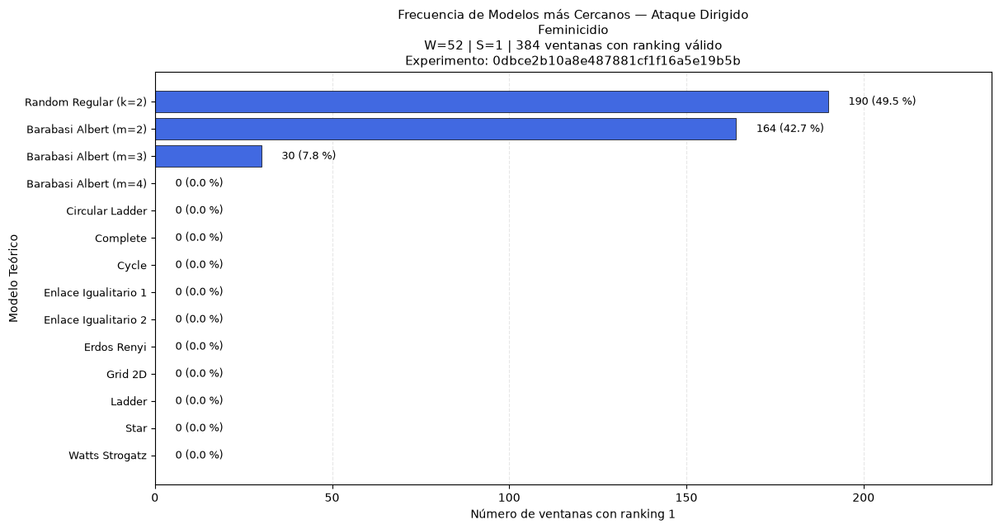

2026-10-07 07:58:55,241 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_0dbce2b10a8e487881cf1f16a5e19b5b.pkl


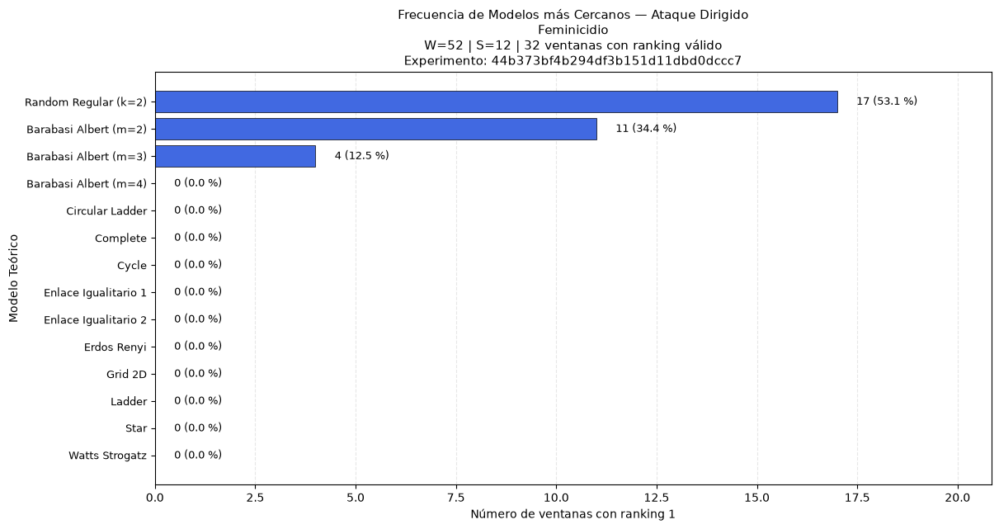

2026-10-07 07:58:55,569 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_44b373bf4b294df3b151d11dbd0dccc7.pkl


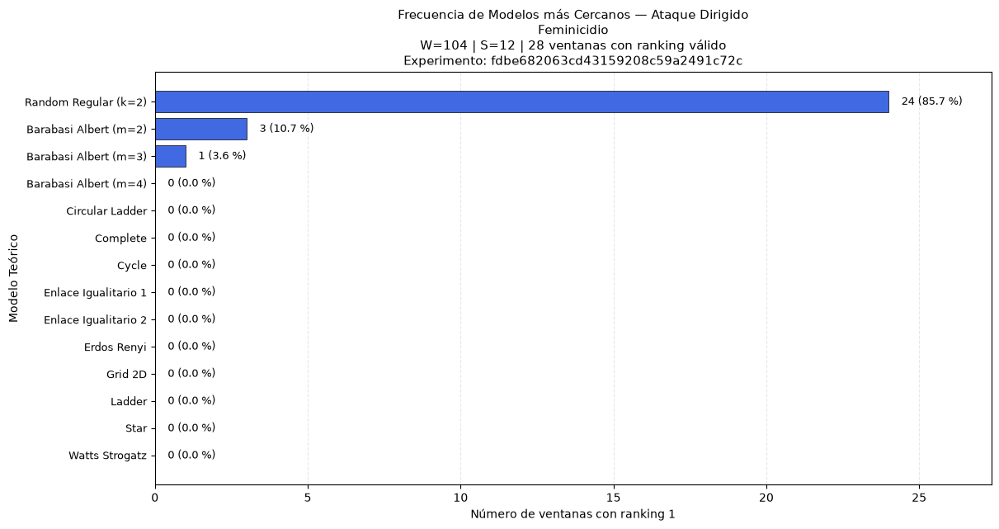

2026-10-07 07:58:55,879 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W104_S12_fdbe682063cd43159208c59a2491c72c.pkl


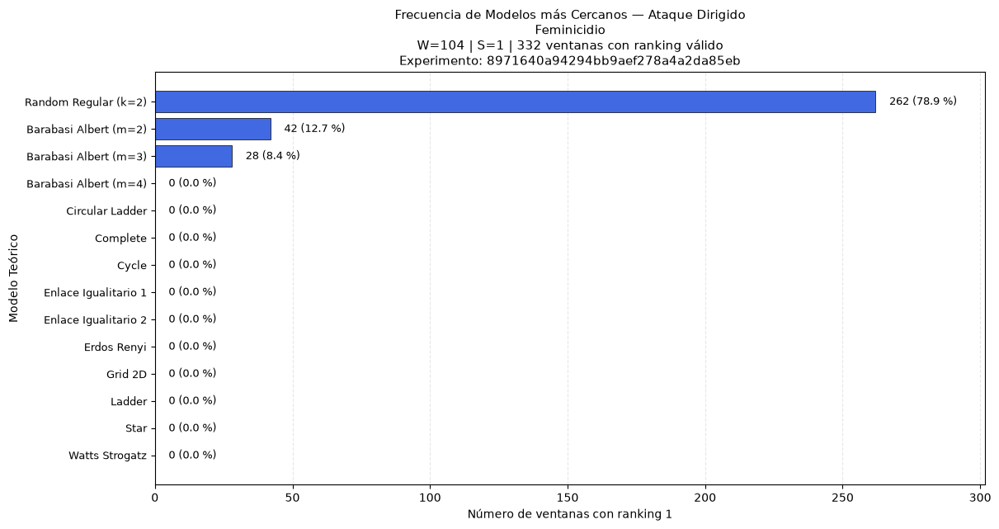

2026-10-07 07:58:56,196 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W104_S1_8971640a94294bb9aef278a4a2da85eb.pkl


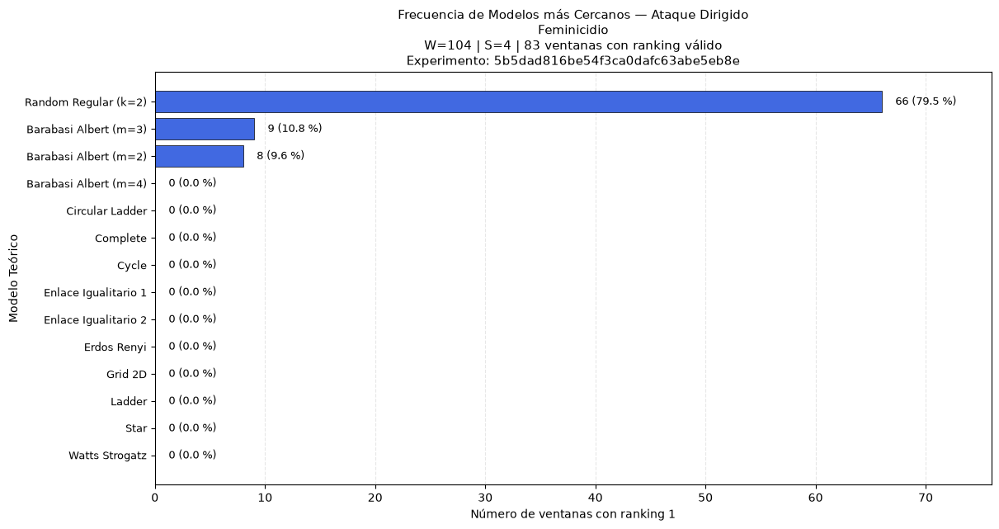

2026-10-07 07:58:56,504 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W104_S4_5b5dad816be54f3ca0dafc63abe5eb8e.pkl


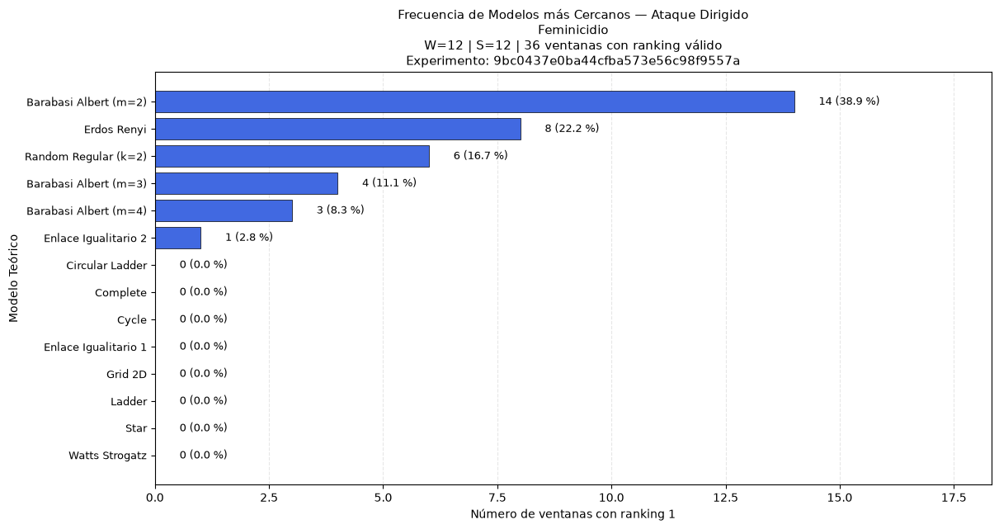

2026-10-07 07:58:56,813 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W12_S12_9bc0437e0ba44cfba573e56c98f9557a.pkl


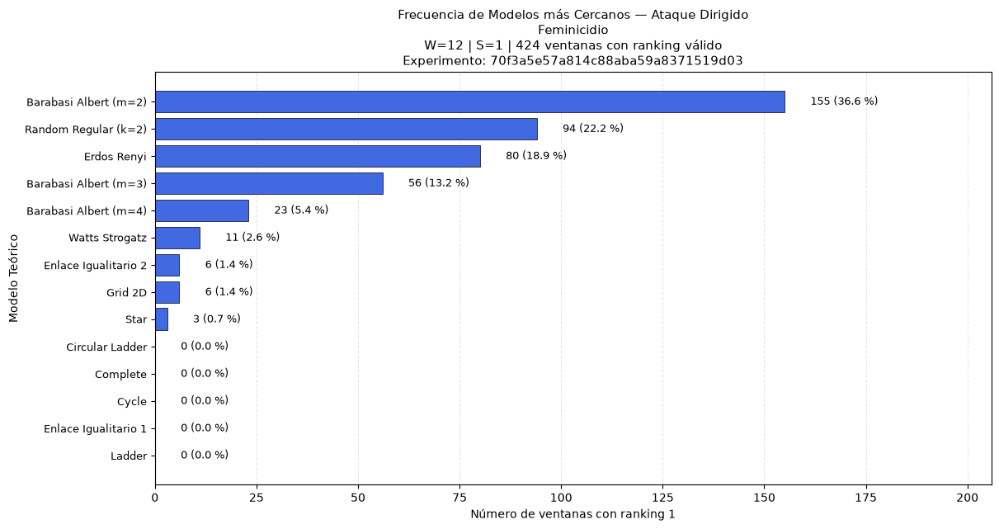

2026-10-07 07:58:57,163 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W12_S1_70f3a5e57a814c88aba59a8371519d03.pkl


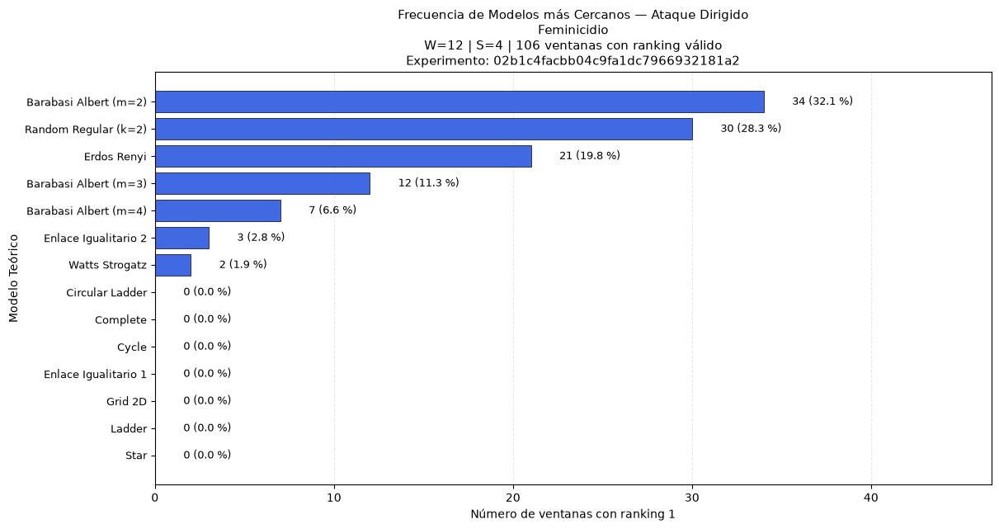

2026-10-07 07:58:57,466 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W12_S4_02b1c4facbb04c9fa1dc7966932181a2.pkl


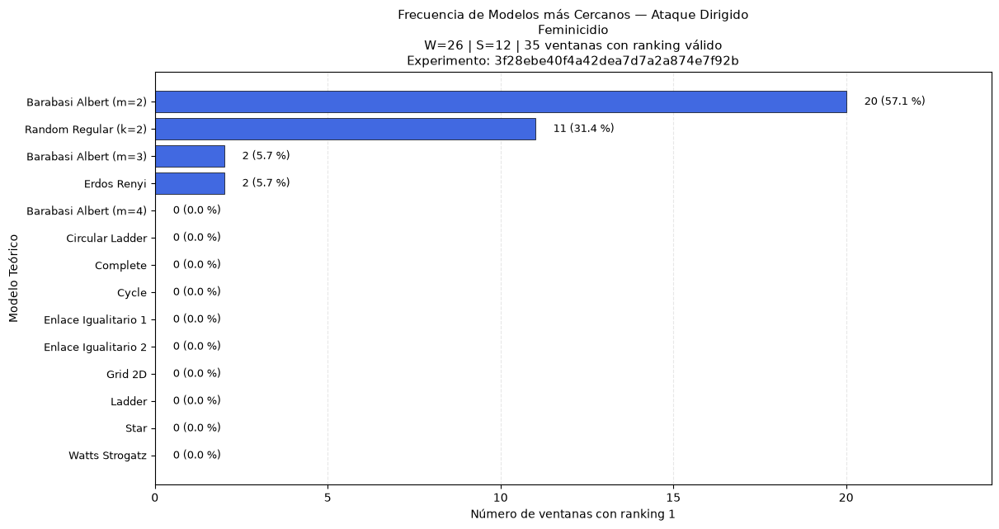

2026-10-07 07:58:57,804 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W26_S12_3f28ebe40f4a42dea7d7a2a874e7f92b.pkl


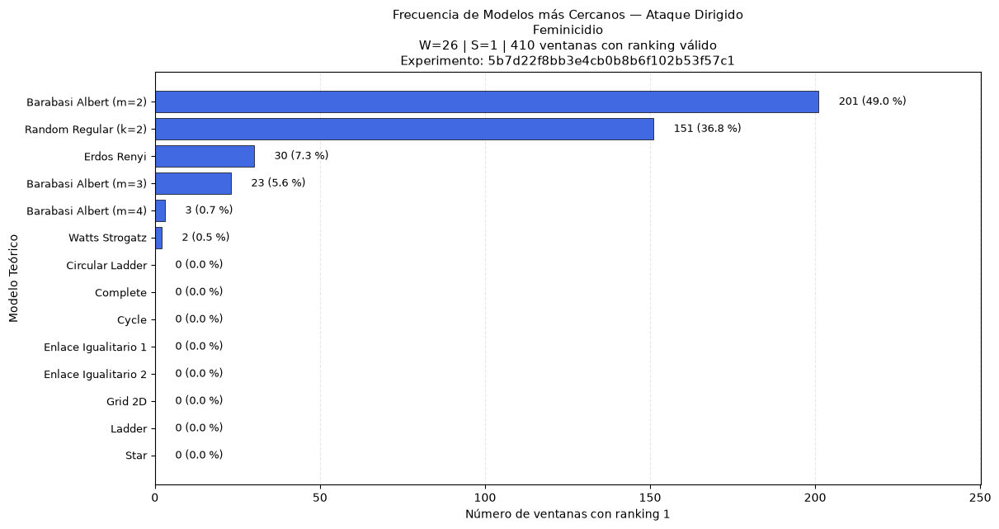

2026-10-07 07:58:58,119 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W26_S1_5b7d22f8bb3e4cb0b8b6f102b53f57c1.pkl


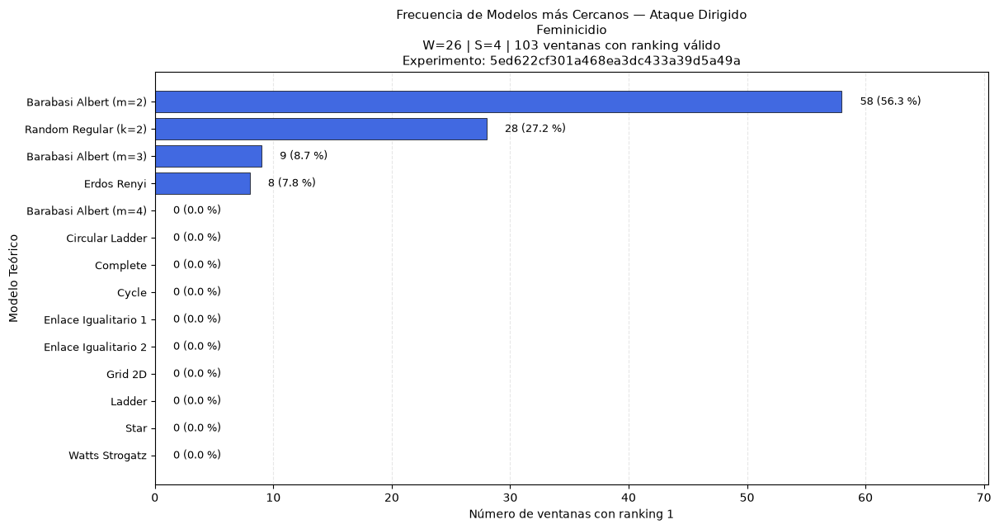

2026-10-07 07:58:58,427 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W26_S4_5ed622cf301a468ea3dc433a39d5a49a.pkl


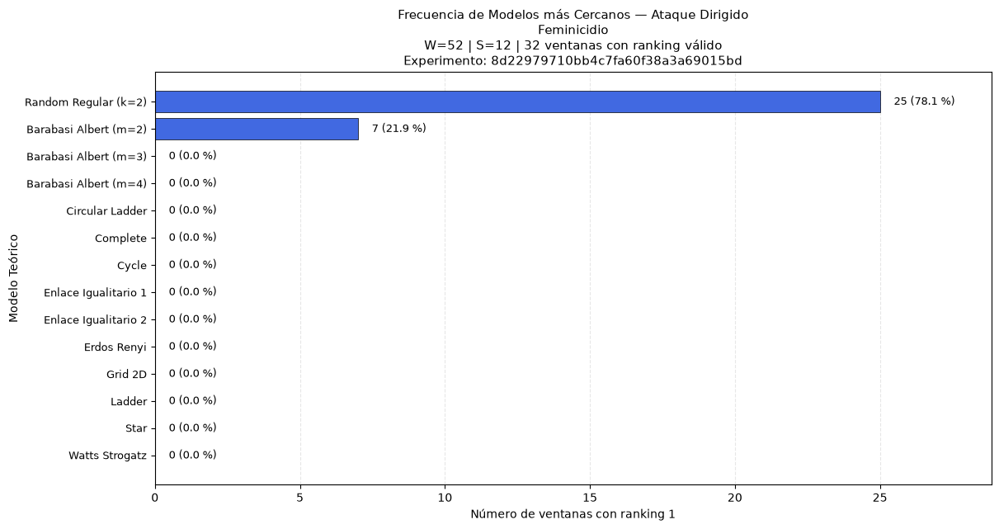

2026-10-07 07:58:58,718 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W52_S12_8d22979710bb4c7fa60f38a3a69015bd.pkl


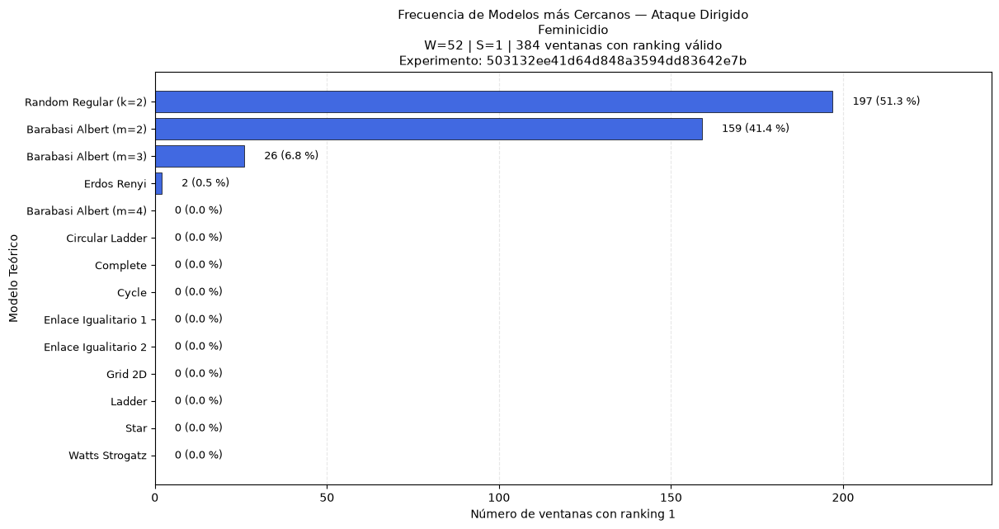

2026-10-07 07:58:59,020 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W52_S1_503132ee41d64d848a3594dd83642e7b.pkl


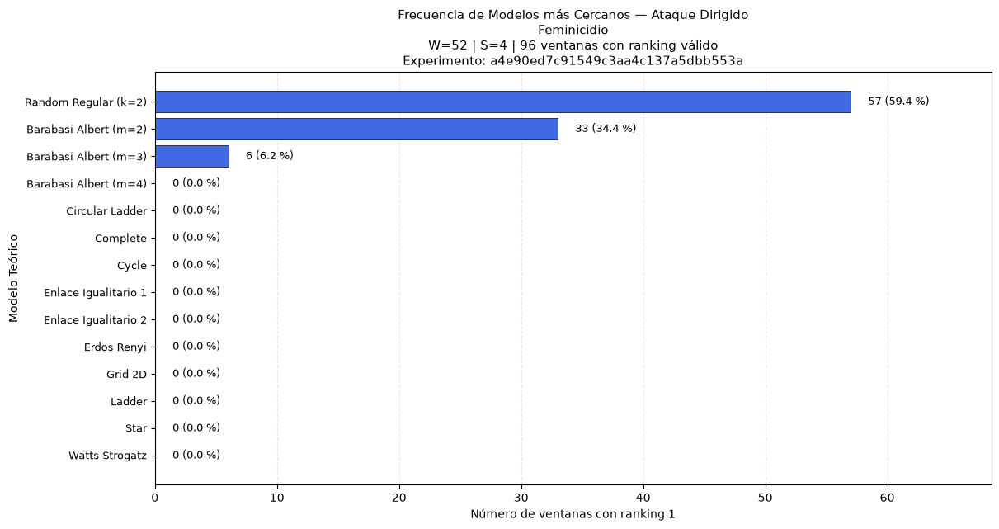

2026-10-07 07:58:59,443 - [<module>] - INFO - Gráfica generada: FEMINICIDIO_W52_S4_a4e90ed7c91549c3aa4c137a5dbb553a.pkl


In [57]:
# [SANDBOX] Frecuencia de modelos ganadores por experimento
# INPUT:  REPORT_PATH, TARGET_CRIME
# OUTPUT: Una gráfica de barras por archivo .pkl

nombre_delito = re.sub(
    r'[<>:"/\\|?*\x00-\x1f]',
    "_",
    TARGET_CRIME,
).strip().rstrip(". ")

carpeta_delito = REPORT_PATH / nombre_delito

if not carpeta_delito.is_dir():
    raise FileNotFoundError(
        f"No existe la carpeta de reportes: {carpeta_delito}"
    )

archivos_reportes = sorted(carpeta_delito.glob("*.pkl"))

if not archivos_reportes:
    logger.warning(f"No hay archivos .pkl en: {carpeta_delito}")


def etiqueta_modelo(nombre: str) -> str:
    """Agrupa los valores variables de p y conserva los otros parámetros."""
    if nombre.startswith("Erdos Renyi ("):
        return "Erdos Renyi"
    if nombre.startswith("Watts Strogatz ("):
        return "Watts Strogatz"
    return nombre


for archivo_reporte in archivos_reportes:
    try:
        df_reporte = pd.read_pickle(archivo_reporte)

        columnas_requeridas = {
            "experiment_id",
            "crime_name",
            "window_size",
            "step_size",
            "window_id",
            "estrategia",
            "modelo",
            "ranking",
        }

        faltantes = columnas_requeridas - set(df_reporte.columns)

        if faltantes:
            raise ValueError(
                f"Faltan columnas: {sorted(faltantes)}"
            )

        if df_reporte.empty:
            logger.warning(f"Reporte vacío: {archivo_reporte.name}")
            continue

        # Cada archivo debe corresponder a un único experimento.
        metadatos = {}

        for columna in (
            "experiment_id",
            "crime_name",
            "window_size",
            "step_size",
        ):
            valores = df_reporte[columna].drop_duplicates()

            if len(valores) != 1 or pd.isna(valores.iloc[0]):
                raise ValueError(
                    f"El campo '{columna}' no tiene un único valor válido."
                )

            metadatos[columna] = valores.iloc[0]

        # Analizar exclusivamente ataque dirigido.
        df_ataque = df_reporte.loc[
            df_reporte["estrategia"].eq("ataque"),
            ["window_id", "modelo", "ranking"],
        ].copy()

        if df_ataque.empty:
            logger.warning(
                f"Sin resultados de ataque: {archivo_reporte.name}"
            )
            continue

        if df_ataque[["window_id", "modelo"]].isna().any().any():
            raise ValueError("Hay ventanas o modelos faltantes.")

        df_ataque["ranking"] = pd.to_numeric(
            df_ataque["ranking"],
            errors="raise",
        )

        df_ataque["modelo_visual"] = (
            df_ataque["modelo"]
            .astype(str)
            .str.strip()
            .map(etiqueta_modelo)
        )

        # Denominador: ventanas con al menos un ranking válido.
        ranking_valido = (
            df_ataque["ranking"].notna()
            & np.isfinite(
                df_ataque["ranking"].to_numpy(
                    dtype=float, na_value=np.nan
                )
            )
            & df_ataque["ranking"].ge(1).fillna(False)
        )

        total_ventanas = df_ataque.loc[
            ranking_valido, "window_id"
        ].nunique()

        if total_ventanas == 0:
            logger.warning(
                f"Sin rankings válidos: {archivo_reporte.name}"
            )
            continue

        # Conservar modelos que nunca ganaron, con frecuencia cero.
        modelos = sorted(df_ataque["modelo_visual"].unique())

        df_ganadores = (
            df_ataque.loc[
                df_ataque["ranking"].eq(1).fillna(False)
            ]
            .drop_duplicates(["window_id", "modelo_visual"])
        )

        frecuencias = (
            df_ganadores["modelo_visual"]
            .value_counts()
            .reindex(modelos, fill_value=0)
            .sort_values(ascending=False, kind="stable")
        )

        fig, ax = plt.subplots(
            figsize=(12, max(5, len(frecuencias) * 0.45)),
            constrained_layout=True,
        )

        posiciones = np.arange(len(frecuencias))

        ax.barh(
            posiciones,
            frecuencias.to_numpy(),
            color="royalblue",
            edgecolor="black",
            linewidth=0.5,
        )

        ax.set_yticks(posiciones)
        ax.set_yticklabels(frecuencias.index, fontsize=9)
        ax.invert_yaxis()

        margen = max(0.3, total_ventanas * 0.015)

        for posicion, frecuencia in enumerate(frecuencias):
            porcentaje = 100 * frecuencia / total_ventanas

            ax.text(
                frecuencia + margen,
                posicion,
                f"{int(frecuencia)} ({porcentaje:.1f} %)",
                va="center",
                fontsize=9,
            )

        ax.set_xlim(0, max(1, frecuencias.max()) + 8 * margen)
        ax.set_xlabel("Número de ventanas con ranking 1")
        ax.set_ylabel("Modelo Teórico")
        ax.grid(axis="x", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        ax.set_title(
            f"Frecuencia de Modelos más Cercanos — Ataque Dirigido\n"
            f"{str(metadatos['crime_name']).title()}\n"
            f"W={metadatos['window_size']} | "
            f"S={metadatos['step_size']} | "
            f"{total_ventanas} ventanas con ranking válido\n"
            f"Experimento: {metadatos['experiment_id']}",
            fontsize=11,
        )

        plt.show()

        logger.info(f"Gráfica generada: {archivo_reporte.name}")

    except Exception as err:
        logger.error(
            f"No se pudo procesar {archivo_reporte.name}: {err}"
        )

#### Cuadricula de Histogramas

2026-10-07 07:58:59,757 - [<module>] - INFO - Panel (1, 1): FEMINICIDIO_0dbce2b10a8e487881cf1f16a5e19b5b.pkl
2026-10-07 07:58:59,776 - [<module>] - INFO - Panel (1, 2): FEMINICIDIO_44b373bf4b294df3b151d11dbd0dccc7.pkl
2026-10-07 07:58:59,818 - [<module>] - INFO - Panel (1, 3): FEMINICIDIO_W104_S12_fdbe682063cd43159208c59a2491c72c.pkl
2026-10-07 07:58:59,857 - [<module>] - INFO - Panel (2, 1): FEMINICIDIO_W104_S1_8971640a94294bb9aef278a4a2da85eb.pkl
2026-10-07 07:58:59,880 - [<module>] - INFO - Panel (2, 2): FEMINICIDIO_W104_S4_5b5dad816be54f3ca0dafc63abe5eb8e.pkl
2026-10-07 07:58:59,906 - [<module>] - INFO - Panel (2, 3): FEMINICIDIO_W12_S12_9bc0437e0ba44cfba573e56c98f9557a.pkl
2026-10-07 07:58:59,931 - [<module>] - INFO - Panel (3, 1): FEMINICIDIO_W12_S1_70f3a5e57a814c88aba59a8371519d03.pkl
2026-10-07 07:58:59,952 - [<module>] - INFO - Panel (3, 2): FEMINICIDIO_W12_S4_02b1c4facbb04c9fa1dc7966932181a2.pkl
2026-10-07 07:58:59,971 - [<module>] - INFO - Panel (3, 3): FEMINICIDIO_W26_S12_3

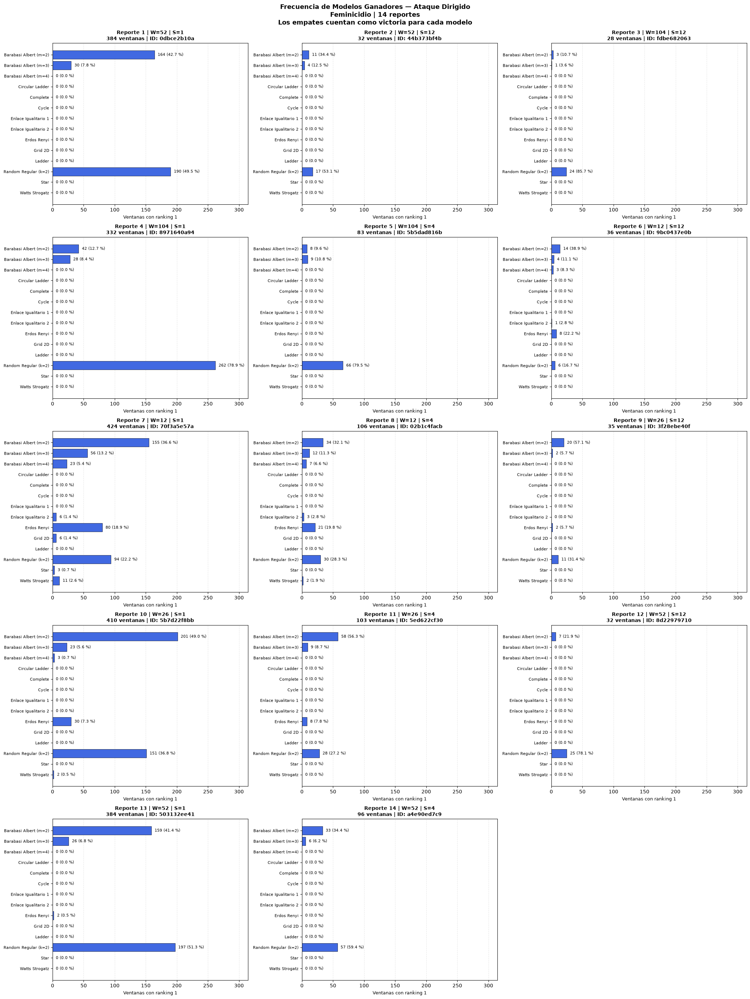

In [58]:
# [SANDBOX] Cuadrícula de frecuencias de ganadores por experimento
# INPUT:  REPORT_PATH, TARGET_CRIME, columnas_cuadricula
# OUTPUT: Una figura con un panel por archivo .pkl

columnas_cuadricula = 3

nombre_delito = re.sub(
    r'[<>:"/\\|?*\x00-\x1f]',
    "_",
    TARGET_CRIME,
).strip().rstrip(". ")

carpeta_delito = REPORT_PATH / nombre_delito

if not carpeta_delito.is_dir():
    raise FileNotFoundError(
        f"No existe la carpeta de reportes: {carpeta_delito}"
    )

archivos_reportes = sorted(carpeta_delito.glob("*.pkl"))

if not archivos_reportes:
    raise FileNotFoundError(
        f"No hay archivos .pkl en: {carpeta_delito}"
    )

if columnas_cuadricula <= 0:
    raise ValueError("columnas_cuadricula debe ser positivo.")


def etiqueta_modelo(nombre: str) -> str:
    if nombre.startswith("Erdos Renyi ("):
        return "Erdos Renyi"
    if nombre.startswith("Watts Strogatz ("):
        return "Watts Strogatz"
    return nombre


# 1. Leer los archivos y calcular sus frecuencias.
reportes = []

columnas_requeridas = {
    "experiment_id",
    "crime_name",
    "window_size",
    "step_size",
    "window_id",
    "estrategia",
    "modelo",
    "ranking",
}

for archivo_reporte in archivos_reportes:
    try:
        df_reporte = pd.read_pickle(archivo_reporte)

        faltantes = columnas_requeridas - set(df_reporte.columns)

        if faltantes:
            raise ValueError(
                f"Faltan columnas: {sorted(faltantes)}"
            )

        if df_reporte.empty:
            raise ValueError("El reporte está vacío.")

        metadatos = {}

        for columna in (
            "experiment_id",
            "crime_name",
            "window_size",
            "step_size",
        ):
            valores = df_reporte[columna].drop_duplicates()

            if len(valores) != 1 or pd.isna(valores.iloc[0]):
                raise ValueError(
                    f"'{columna}' no tiene un único valor válido."
                )

            metadatos[columna] = valores.iloc[0]

        df_ataque = df_reporte.loc[
            df_reporte["estrategia"].eq("ataque"),
            ["window_id", "modelo", "ranking"],
        ].copy()

        if df_ataque.empty:
            raise ValueError("No hay resultados de ataque dirigido.")

        if df_ataque[["window_id", "modelo"]].isna().any().any():
            raise ValueError("Hay ventanas o modelos faltantes.")

        df_ataque["modelo_visual"] = (
            df_ataque["modelo"]
            .astype(str)
            .str.strip()
            .map(etiqueta_modelo)
        )

        df_ataque["ranking"] = pd.to_numeric(
            df_ataque["ranking"],
            errors="raise",
        )

        ranking_valido = (
            df_ataque["ranking"].notna()
            & np.isfinite(
                df_ataque["ranking"].to_numpy(
                    dtype=float, na_value=np.nan
                )
            )
            & df_ataque["ranking"].ge(1).fillna(False)
        )

        total_ventanas = df_ataque.loc[
            ranking_valido, "window_id"
        ].nunique()

        if total_ventanas == 0:
            raise ValueError("No hay ventanas con ranking válido.")

        df_ganadores = (
            df_ataque.loc[
                df_ataque["ranking"].eq(1).fillna(False)
            ]
            .drop_duplicates(["window_id", "modelo_visual"])
        )

        frecuencias = (
            df_ganadores["modelo_visual"]
            .value_counts()
            .reindex(
                sorted(df_ataque["modelo_visual"].unique()),
                fill_value=0,
            )
        )

        reportes.append(
            {
                **metadatos,
                "archivo": archivo_reporte.name,
                "total_ventanas": total_ventanas,
                "frecuencias": frecuencias,
            }
        )

    except Exception as err:
        logger.error(
            f"No se pudo procesar {archivo_reporte.name}: {err}"
        )

if not reportes:
    raise ValueError("No hay reportes válidos para graficar.")

# 2. Usar un catálogo común y el mismo orden en todos los paneles.
modelos = sorted(
    {
        modelo
        for reporte in reportes
        for modelo in reporte["frecuencias"].index
    }
)

for reporte in reportes:
    reporte["frecuencias"] = reporte["frecuencias"].reindex(
        modelos, fill_value=0
    )

max_frecuencia = max(
    int(reporte["frecuencias"].max())
    for reporte in reportes
)

# 3. Crear la cuadrícula.
n_reportes = len(reportes)
n_columnas = min(columnas_cuadricula, n_reportes)
n_filas = math.ceil(n_reportes / n_columnas)

fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(
        7 * n_columnas,
        max(5, len(modelos) * 0.4) * n_filas,
    ),
    squeeze=False,
    constrained_layout=True,
)

posiciones = np.arange(len(modelos))
margen = max(0.3, max_frecuencia * 0.02)

# 4. Colocar cada reporte en un panel.
for indice, reporte in enumerate(reportes):
    fila, columna = divmod(indice, n_columnas)
    ax = axes[fila, columna]

    frecuencias = reporte["frecuencias"]

    ax.barh(
        posiciones,
        frecuencias.to_numpy(),
        color="royalblue",
        edgecolor="black",
        linewidth=0.5,
    )

    ax.set_yticks(posiciones)
    ax.set_yticklabels(modelos, fontsize=8)
    ax.invert_yaxis()

    for posicion, frecuencia in enumerate(frecuencias):
        porcentaje = (
            100 * frecuencia / reporte["total_ventanas"]
        )

        ax.text(
            frecuencia + margen,
            posicion,
            f"{int(frecuencia)} ({porcentaje:.1f} %)",
            va="center",
            fontsize=8,
        )

    ax.set_xlim(0, max(1, max_frecuencia) + 10 * margen)
    ax.set_xlabel("Ventanas con ranking 1", fontsize=9)
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.set_title(
        f"Reporte {indice + 1} | "
        f"W={reporte['window_size']} | S={reporte['step_size']}\n"
        f"{reporte['total_ventanas']} ventanas | "
        f"ID: {str(reporte['experiment_id'])[:10]}",
        fontsize=10,
        fontweight="bold",
    )

    logger.info(
        f"Panel ({fila + 1}, {columna + 1}): "
        f"{reporte['archivo']}"
    )

# Ocultar los espacios sobrantes.
for indice in range(n_reportes, n_filas * n_columnas):
    fila, columna = divmod(indice, n_columnas)
    axes[fila, columna].set_visible(False)

fig.suptitle(
    f"Frecuencia de Modelos Ganadores — Ataque Dirigido\n"
    f"{TARGET_CRIME.title()} | {n_reportes} reportes\n"
    f"Los empates cuentan como victoria para cada modelo",
    fontsize=13,
    fontweight="bold",
)

plt.show()

#### Cuadricula de Cambios de Red

In [2]:
# [SANDBOX] Cuadrícula 3×3 de transiciones bajo ataque dirigido
# INPUT:  report_path (Path), crime_name (str)
# OUTPUT: Una figura por cada grupo de hasta nueve reportes

from matplotlib.colors import Normalize


def plot_resilience_reports_grid(
    report_path: Path,
    crime_name: str,
) -> None:
    """Lee los reportes y grafica solo la estrategia de ataque dirigido."""

    nombre_delito = re.sub(
        r'[<>:"/\\|?*\x00-\x1f]',
        "_",
        crime_name,
    ).strip().rstrip(". ")

    carpeta_delito = Path(report_path) / nombre_delito

    if not carpeta_delito.is_dir():
        raise FileNotFoundError(
            f"No existe la carpeta: {carpeta_delito}"
        )

    archivos = sorted(carpeta_delito.glob("*.pkl"))

    if not archivos:
        raise FileNotFoundError(
            f"No hay archivos .pkl en: {carpeta_delito}"
        )

    columnas = ["window_id", "estrategia", "modelo", "distancia"]
    metadatos = [
        "experiment_id",
        "crime_name",
        "window_size",
        "step_size",
    ]

    reportes = []

    # 1. Leer y preparar cada reporte.
    for archivo in archivos:
        try:
            df_reporte = pd.read_pickle(archivo)

            if not isinstance(df_reporte, pd.DataFrame):
                raise ValueError("El archivo no contiene un DataFrame.")

            faltantes = (
                set(columnas + metadatos) - set(df_reporte.columns)
            )

            if faltantes:
                raise ValueError(
                    f"Faltan columnas: {sorted(faltantes)}"
                )

            if df_reporte.empty:
                raise ValueError("El reporte está vacío.")

            datos = {}

            for campo in metadatos:
                valores = df_reporte[campo].drop_duplicates()

                if len(valores) != 1 or pd.isna(valores.iloc[0]):
                    raise ValueError(
                        f"'{campo}' no tiene un único valor válido."
                    )

                datos[campo] = valores.iloc[0]

            if datos["crime_name"] != crime_name:
                raise ValueError("El delito del reporte no coincide.")

            # Conservar únicamente ataque dirigido.
            df_plot = df_reporte.loc[
                df_reporte["estrategia"].eq("ataque"),
                columnas,
            ].copy()

            if df_plot.empty:
                raise ValueError("No hay registros de ataque dirigido.")

            if df_plot[["window_id", "modelo"]].isna().any().any():
                raise ValueError("Hay ventanas o modelos faltantes.")

            df_plot["modelo"] = (
                df_plot["modelo"].astype(str).str.strip()
            )

            if df_plot["modelo"].eq("").any():
                raise ValueError("Hay nombres de modelos vacíos.")

            claves = ["window_id", "estrategia", "modelo"]

            if df_plot.duplicated(claves).any():
                raise ValueError("Hay comparaciones duplicadas.")

            df_plot["distancia"] = pd.to_numeric(
                df_plot["distancia"],
                errors="raise",
            )

            # Conservar las ventanas para representar posibles huecos.
            ventanas = np.sort(df_plot["window_id"].unique())

            df_plot = df_plot.loc[
                np.isfinite(df_plot["distancia"])
            ].copy()

            if df_plot.empty:
                raise ValueError("No hay distancias válidas.")

            # Mantener el desempate alfabético de la gráfica original.
            df_plot = df_plot.sort_values(
                ["window_id", "distancia", "modelo"]
            )

            df_plot["lugar"] = (
                df_plot.groupby("window_id").cumcount() + 1
            )

            df_top3 = df_plot.loc[
                df_plot["lugar"].le(3)
            ].copy()

            # # Mantener la agrupación por familia de la gráfica original.
            # df_top3["categoria"] = (
            #     df_top3["modelo"]
            #     .str.split("(", n=1, regex=False)
            #     .str[0]
            #     .str.strip()
            # )

            # # Conservar cada modelo con sus parámetros.
            # df_top3["categoria"] = df_top3["modelo"]

            # Conservar m y k. Agrupar únicamente los valores de p
            # de Erdos Renyi y Watts Strogatz para la visualización.
            df_top3["categoria"] = df_top3["modelo"].str.replace(
                r"^(Erdos Renyi|Watts Strogatz)\s*\(p=[^)]*\)$",
                r"\1",
                regex=True,
            )

            if df_top3["categoria"].eq("").any():
                raise ValueError("Hay categorías vacías.")

            reportes.append({
                **datos,
                "archivo": archivo.name,
                "ventanas": ventanas,
                "top3": df_top3,
            })

        except Exception as err:
            logger.error(
                f"No se pudo preparar {archivo.name}: {err}"
            )

    if not reportes:
        raise ValueError("No hay reportes válidos para graficar.")

    # Ordenar por tamaño de ventana, paso e identificador.
    reportes.sort(
        key=lambda reporte: (
            reporte["window_size"],
            reporte["step_size"],
            str(reporte["experiment_id"]),
        )
    )

    # 2. Posiciones categóricas comunes para todos los reportes.
    modelos = sorted({
        modelo
        for reporte in reportes
        for modelo in reporte["top3"]["categoria"]
    })

    modelo_a_posicion = {
        modelo: posicion
        for posicion, modelo in enumerate(modelos)
    }

    # Escala de distancia común para todos los primeros lugares.
    distancias_primeros = np.concatenate([
        reporte["top3"].loc[
            reporte["top3"]["lugar"].eq(1),
            "distancia",
        ].to_numpy(dtype=float)
        for reporte in reportes
    ])

    minimo = float(distancias_primeros.min())
    maximo = float(distancias_primeros.max())

    if minimo == maximo:
        maximo = minimo + max(1e-6, abs(minimo) * 0.01)

    normalizacion = Normalize(vmin=minimo, vmax=maximo)

    estilos_adicionales = {
        2: {
            "color": "royalblue",
            "marker": "s",
            "label": "Segundo lugar",
        },
        3: {
            "color": "gray",
            "marker": "^",
            "label": "Tercer lugar",
        },
    }

    # 3. Crear una cuadrícula de 4 filas y 3 columnas.
    filas = 5
    columnas = 3
    reportes_por_figura = filas * columnas

    for inicio in range(0, len(reportes), reportes_por_figura):
        grupo = reportes[inicio:inicio + reportes_por_figura]
        numero_figura = inicio // reportes_por_figura + 1

        fig, axes = plt.subplots(
            filas,
            columnas,
            figsize=(27, 30),
            constrained_layout=True,
        )

        for posicion, reporte in enumerate(grupo):
            fila, columna = divmod(posicion, columnas)
            ax = axes[fila, columna]

            ventanas = reporte["ventanas"]
            df_top3 = reporte["top3"]

            df_primero = (
                df_top3.loc[df_top3["lugar"].eq(1)]
                .set_index("window_id")
                .reindex(ventanas)
            )

            eje_y = df_primero["categoria"].map(
                modelo_a_posicion
            )

            # Línea únicamente para el primer lugar.
            ax.plot(
                ventanas,
                eje_y,
                color="crimson",
                linestyle="--",
                linewidth=1,
                alpha=0.45,
                zorder=2,
            )

            validos = eje_y.notna().to_numpy()

            # Primer lugar: color según su distancia.
            if validos.any():
                scatter = ax.scatter(
                    ventanas[validos],
                    eje_y.to_numpy()[validos],
                    c=df_primero["distancia"].to_numpy()[validos],
                    cmap="viridis_r",
                    norm=normalizacion,
                    s=35,
                    edgecolor="black",
                    linewidth=0.5,
                    zorder=5,
                )

                cbar = fig.colorbar(
                    scatter,
                    ax=ax,
                    pad=0.01,
                    fraction=0.035,
                )
                cbar.set_label("D — Primero", fontsize=7)
                cbar.ax.tick_params(labelsize=6)

            # Segundo y tercer lugar: colores fijos, sin líneas.
            for lugar, estilo in estilos_adicionales.items():
                df_lugar = df_top3.loc[
                    df_top3["lugar"].eq(lugar)
                ]

                if df_lugar.empty:
                    continue

                ax.scatter(
                    df_lugar["window_id"],
                    df_lugar["categoria"].map(modelo_a_posicion),
                    color=estilo["color"],
                    marker=estilo["marker"],
                    label=estilo["label"],
                    s=25,
                    edgecolor="black",
                    linewidth=0.4,
                    zorder=3,
                )

            ax.set_yticks(range(len(modelos)))
            ax.set_yticklabels(modelos, fontsize=7)
            ax.set_ylabel("Modelo teórico", fontsize=8)

            ax.set_ylim(-0.5, len(modelos) - 0.5)
            ax.set_xlim(
                ventanas.min() - 0.5,
                ventanas.max() + 0.5,
            )

            # Mostrar aproximadamente doce etiquetas por gráfica.
            salto = max(1, int(np.ceil(len(ventanas) / 12)))
            ticks = ventanas[::salto]

            ax.set_xticks(ticks)
            ax.set_xticklabels(
                [f"W{int(window)}" for window in ticks],
                rotation=90,
                fontsize=6,
            )
            ax.set_xlabel("Ventana", fontsize=8)

            ax.grid(True, linestyle="--", alpha=0.3)

            ax.set_title(
                f"Reporte {inicio + posicion + 1} | "
                f"W={reporte['window_size']} | "
                f"S={reporte['step_size']} | "
                f"{len(ventanas)} ventanas\n"
                f"ID: {str(reporte['experiment_id'])[:10]}\n"
                f"Ataque dirigido",
                fontsize=9,
                fontweight="bold",
            )

            if ax.get_legend_handles_labels()[0]:
                ax.legend(loc="best", fontsize=6)

            logger.info(
                f"Figura {numero_figura}, "
                f"casilla ({fila + 1}, {columna + 1}): "
                f"{reporte['archivo']}"
            )

        # Ocultar las casillas sin reporte.
        for posicion in range(len(grupo), reportes_por_figura):
            fila, columna = divmod(posicion, columnas)
            axes[fila, columna].set_axis_off()

        fig.suptitle(
            f"Transiciones de los Tres Modelos más Próximos "
            f"bajo Ataque Dirigido\n"
            f"{crime_name.title()} | "
            f"Figura {numero_figura}",
            fontsize=15,
            fontweight="bold",
        )

        plt.show()

NameError: name 'Path' is not defined

In [1]:
plot_resilience_reports_grid(
    report_path=REPORT_PATH,
    crime_name=TARGET_CRIME,
)

NameError: name 'plot_resilience_reports_grid' is not defined

#### Cuadricula de Cambio de Red con Aleatorios

In [118]:
# [SANDBOX] Cuadrícula 3×3 de transiciones por archivo
# INPUT:  report_path (Path), crime_name (str)
# OUTPUT: Una figura por cada grupo de hasta nueve reportes

from matplotlib.colors import Normalize


def plot_resilience_reports_grid(
    report_path: Path,
    crime_name: str,
) -> None:
    """Lee los reportes y dibuja ataque y falla dentro de cada casilla."""

    nombre_delito = re.sub(
        r'[<>:"/\\|?*\x00-\x1f]',
        "_",
        crime_name,
    ).strip().rstrip(". ")

    carpeta_delito = Path(report_path) / nombre_delito

    if not carpeta_delito.is_dir():
        raise FileNotFoundError(
            f"No existe la carpeta: {carpeta_delito}"
        )

    archivos = sorted(carpeta_delito.glob("*.pkl"))

    if not archivos:
        raise FileNotFoundError(
            f"No hay archivos .pkl en: {carpeta_delito}"
        )

    columnas = ["window_id", "estrategia", "modelo", "distancia"]
    metadatos = [
        "experiment_id",
        "crime_name",
        "window_size",
        "step_size",
    ]

    reportes = []

    # 1. Leer y preparar cada reporte.
    for archivo in archivos:
        try:
            df_reporte = pd.read_pickle(archivo)

            faltantes = set(columnas + metadatos) - set(df_reporte.columns)
            if faltantes:
                raise ValueError(
                    f"Faltan columnas: {sorted(faltantes)}"
                )

            if df_reporte.empty:
                raise ValueError("El reporte está vacío.")

            datos = {}

            for campo in metadatos:
                valores = df_reporte[campo].drop_duplicates()

                if len(valores) != 1 or pd.isna(valores.iloc[0]):
                    raise ValueError(
                        f"'{campo}' no tiene un único valor válido."
                    )

                datos[campo] = valores.iloc[0]

            if datos["crime_name"] != crime_name:
                raise ValueError("El delito del reporte no coincide.")

            df_plot = df_reporte[columnas].copy()
            df_plot = df_plot.loc[
                df_plot["estrategia"].isin(["ataque", "falla"])
            ].copy()

            if df_plot.empty:
                raise ValueError("No hay registros de ataque o falla.")

            if df_plot[["window_id", "modelo"]].isna().any().any():
                raise ValueError("Hay ventanas o modelos faltantes.")

            df_plot["modelo"] = (
                df_plot["modelo"].astype(str).str.strip()
            )

            if df_plot["modelo"].eq("").any():
                raise ValueError("Hay nombres de modelos vacíos.")

            claves = ["window_id", "estrategia", "modelo"]

            if df_plot.duplicated(claves).any():
                raise ValueError("Hay comparaciones duplicadas.")

            df_plot["distancia"] = pd.to_numeric(
                df_plot["distancia"], errors="raise"
            )

            ventanas = np.sort(df_plot["window_id"].unique())

            df_plot = df_plot.loc[
                np.isfinite(df_plot["distancia"])
            ].copy()

            if df_plot.empty:
                raise ValueError("No hay distancias válidas.")

            # Mismo desempate que en tu función original.
            df_plot = df_plot.sort_values(
                ["window_id", "estrategia", "distancia", "modelo"]
            )

            df_plot["lugar"] = (
                df_plot.groupby(["window_id", "estrategia"]).cumcount()
                + 1
            )

            df_top3 = df_plot.loc[
                df_plot["lugar"].le(3)
            ].copy()

            # Mantener la agrupación por familia de tu gráfica original.
            df_top3["categoria"] = (
                df_top3["modelo"]
                .str.split("(", n=1, regex=False)
                .str[0]
                .str.strip()
            )

            if df_top3["categoria"].eq("").any():
                raise ValueError("Hay categorías vacías.")

            reportes.append(
                {
                    **datos,
                    "archivo": archivo.name,
                    "ventanas": ventanas,
                    "top3": df_top3,
                }
            )

        except Exception as err:
            logger.error(f"No se pudo leer {archivo.name}: {err}")

    if not reportes:
        raise ValueError("No hay reportes válidos para graficar.")

    # Ordenar por tamaño, paso e ID.
    reportes.sort(
        key=lambda reporte: (
            reporte["window_size"],
            reporte["step_size"],
            str(reporte["experiment_id"]),
        )
    )

    # 2. Usar las mismas posiciones categóricas en todos los reportes.
    modelos = sorted(
        {
            modelo
            for reporte in reportes
            for modelo in reporte["top3"]["categoria"]
        }
    )

    modelo_a_posicion = {
        modelo: posicion
        for posicion, modelo in enumerate(modelos)
    }

    # Escala de distancia común para los primeros lugares.
    distancias_primeros = np.concatenate(
        [
            reporte["top3"].loc[
                reporte["top3"]["lugar"].eq(1), "distancia"
            ].to_numpy(dtype=float)
            for reporte in reportes
        ]
    )

    minimo = float(distancias_primeros.min())
    maximo = float(distancias_primeros.max())

    if minimo == maximo:
        maximo = minimo + max(1e-6, abs(minimo) * 0.01)

    normalizacion = Normalize(vmin=minimo, vmax=maximo)

    paneles = [
        {
            "estrategia": "ataque",
            "titulo": "Ataque dirigido",
            "color": "crimson",
        },
        {
            "estrategia": "falla",
            "titulo": "Falla aleatoria",
            "color": "royalblue",
        },
    ]

    estilos_adicionales = {
        2: {
            "color": "royalblue",
            "marker": "s",
            "label": "Segundo lugar",
        },
        3: {
            "color": "gray",
            "marker": "^",
            "label": "Tercer lugar",
        },
    }

    # 3. Crear una cuadrícula nueva por cada nueve archivos.
    for inicio in range(0, len(reportes), 9):
        grupo = reportes[inicio:inicio + 9]

        fig = plt.figure(
            figsize=(27, 24),
            constrained_layout=True,
        )

        cuadricula = fig.add_gridspec(3, 3)

        for posicion, reporte in enumerate(grupo):
            fila, columna = divmod(posicion, 3)

            # Dos paneles internos por archivo.
            subcuadricula = cuadricula[fila, columna].subgridspec(
                2, 1
            )

            ax_ataque = fig.add_subplot(subcuadricula[0, 0])
            ax_falla = fig.add_subplot(
                subcuadricula[1, 0],
                sharex=ax_ataque,
            )

            axes = [ax_ataque, ax_falla]
            ventanas = reporte["ventanas"]
            df_top3 = reporte["top3"]

            for ax, panel in zip(axes, paneles):
                df_panel = df_top3.loc[
                    df_top3["estrategia"].eq(panel["estrategia"])
                ]

                df_primero = (
                    df_panel.loc[df_panel["lugar"].eq(1)]
                    .set_index("window_id")
                    .reindex(ventanas)
                )

                eje_y = df_primero["categoria"].map(
                    modelo_a_posicion
                )

                # Línea únicamente para el primer lugar.
                ax.plot(
                    ventanas,
                    eje_y,
                    color=panel["color"],
                    linestyle="--",
                    linewidth=1,
                    alpha=0.45,
                    zorder=2,
                )

                validos = eje_y.notna().to_numpy()

                if validos.any():
                    scatter = ax.scatter(
                        ventanas[validos],
                        eje_y.to_numpy()[validos],
                        c=df_primero["distancia"].to_numpy()[validos],
                        cmap="viridis_r",
                        norm=normalizacion,
                        s=35,
                        edgecolor="black",
                        linewidth=0.5,
                        zorder=5,
                    )

                    cbar = fig.colorbar(
                        scatter, ax=ax, pad=0.01, fraction=0.035
                    )
                    cbar.set_label("D — Primero", fontsize=7)
                    cbar.ax.tick_params(labelsize=6)

                # Segundo y tercero sin líneas.
                for lugar, estilo in estilos_adicionales.items():
                    df_lugar = df_panel.loc[
                        df_panel["lugar"].eq(lugar)
                    ]

                    if df_lugar.empty:
                        continue

                    ax.scatter(
                        df_lugar["window_id"],
                        df_lugar["categoria"].map(modelo_a_posicion),
                        color=estilo["color"],
                        marker=estilo["marker"],
                        label=estilo["label"],
                        s=25,
                        edgecolor="black",
                        linewidth=0.4,
                        zorder=3,
                    )

                ax.set_yticks(range(len(modelos)))
                ax.set_yticklabels(modelos, fontsize=7)
                ax.set_ylim(-0.5, len(modelos) - 0.5)
                ax.set_xlim(
                    ventanas.min() - 0.5,
                    ventanas.max() + 0.5,
                )

                ax.grid(True, linestyle="--", alpha=0.3)
                ax.set_title(panel["titulo"], fontsize=9)

                if ax.get_legend_handles_labels()[0]:
                    ax.legend(loc="best", fontsize=6)

            ax_ataque.set_title(
                f"Reporte {inicio + posicion + 1} | "
                f"W={reporte['window_size']} | "
                f"S={reporte['step_size']} | "
                f"{len(ventanas)} ventanas\n"
                f"ID: {str(reporte['experiment_id'])[:10]}\n"
                f"Ataque dirigido",
                fontsize=9,
                fontweight="bold",
            )

            # Reducir etiquetas cuando hay muchas ventanas.
            salto = max(1, math.ceil(len(ventanas) / 12))
            ticks = ventanas[::salto]

            ax_falla.set_xticks(ticks)
            ax_falla.set_xticklabels(
                [f"W{int(window)}" for window in ticks],
                rotation=90,
                fontsize=6,
            )
            ax_falla.set_xlabel("Ventana", fontsize=8)
            ax_ataque.tick_params(axis="x", labelbottom=False)

            logger.info(
                f"Figura {inicio // 9 + 1}, "
                f"casilla ({fila + 1}, {columna + 1}): "
                f"{reporte['archivo']}"
            )

        # Dejar vacías las casillas que no tienen archivo.
        for posicion in range(len(grupo), 9):
            fila, columna = divmod(posicion, 3)
            ax_vacio = fig.add_subplot(cuadricula[fila, columna])
            ax_vacio.set_axis_off()

        fig.suptitle(
            f"Transiciones de los Tres Modelos más Próximos\n"
            f"{crime_name.title()} | "
            f"Figura {inicio // 9 + 1}",
            fontsize=15,
            fontweight="bold",
        )

        plt.show()

2026-10-07 06:39:06,001 - [plot_resilience_reports_grid] - INFO - Figura 1, casilla (1, 1): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W12_S1_0a4378bb05cb4a19bbd4359f25f1f2da.pkl
2026-10-07 06:39:06,070 - [plot_resilience_reports_grid] - INFO - Figura 1, casilla (1, 2): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W12_S4_9ea14f37a83a4f75a0cb441f7b98f608.pkl
2026-10-07 06:39:06,136 - [plot_resilience_reports_grid] - INFO - Figura 1, casilla (1, 3): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W12_S12_0b1d547318534358845da23ee833a1d6.pkl
2026-10-07 06:39:06,200 - [plot_resilience_reports_grid] - INFO - Figura 1, casilla (2, 1): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W26_S1_df896573fa8f49b2bb2a272ce13d3bba.pkl
2026-10-07 06:39:06,273 - [plot_resilience_reports_grid] - INFO - Figura 1, casilla (2, 2): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W26_S4_a5440a58a0244042a37f6fac15c545a1.pkl
2026-10-07 06:39:06,342 - [plot_resilience_reports_grid] - INFO 

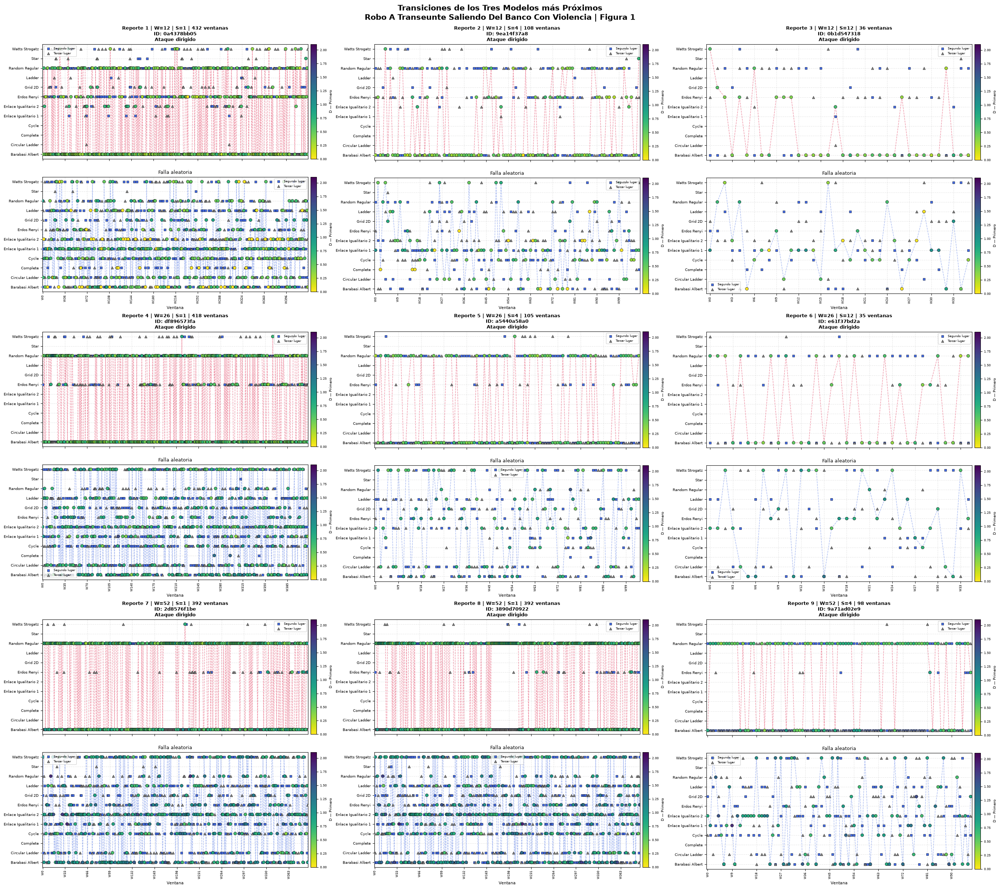

2026-10-07 06:39:11,692 - [plot_resilience_reports_grid] - INFO - Figura 2, casilla (1, 1): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W52_S12_5dcf66518a63454f83893edec8bba17a.pkl
2026-10-07 06:39:11,764 - [plot_resilience_reports_grid] - INFO - Figura 2, casilla (1, 2): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_9bc3a5f59b2d485c8d990ed7dbc84572.pkl
2026-10-07 06:39:11,828 - [plot_resilience_reports_grid] - INFO - Figura 2, casilla (1, 3): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W104_S1_ed938ff825964197aeb3113636d4ab3d.pkl
2026-10-07 06:39:11,893 - [plot_resilience_reports_grid] - INFO - Figura 2, casilla (2, 1): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W104_S4_d09dc1e2e0d74ed79f0a60e8c5f2d920.pkl
2026-10-07 06:39:11,956 - [plot_resilience_reports_grid] - INFO - Figura 2, casilla (2, 2): ROBO A TRANSEUNTE SALIENDO DEL BANCO CON VIOLENCIA_W104_S12_48a8cc986bf14e44a77ab3c6967567ca.pkl


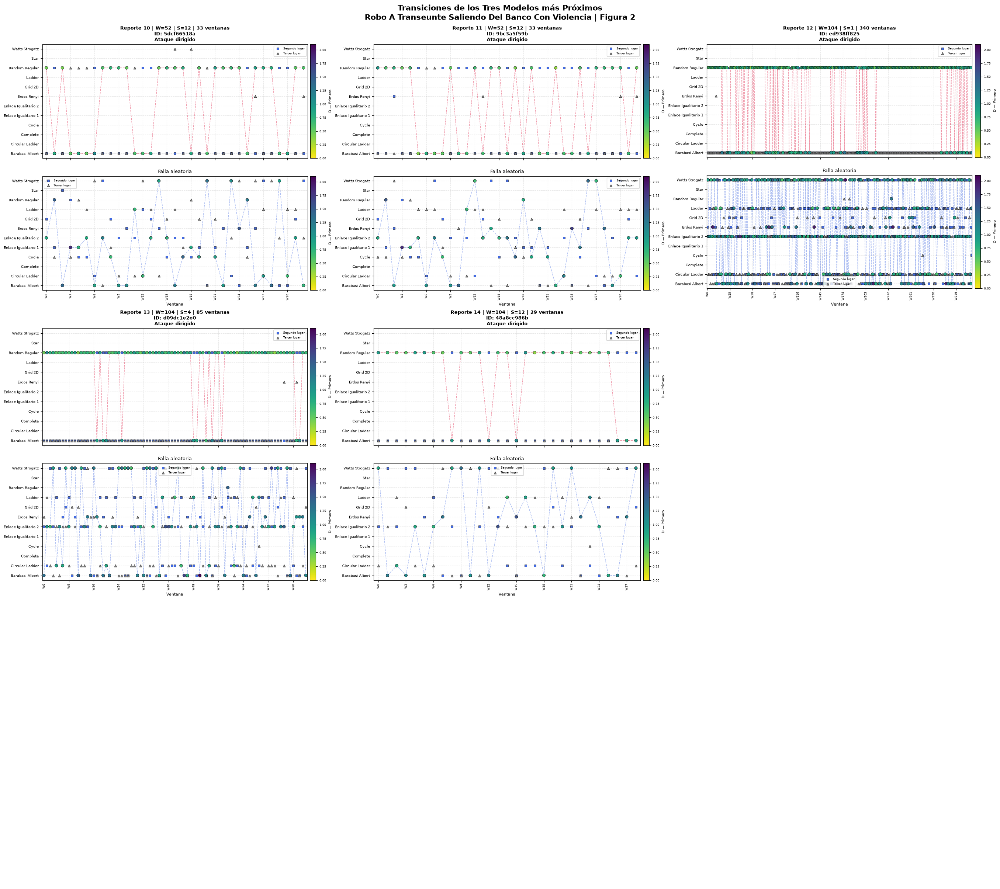

In [119]:
try:
    plot_resilience_reports_grid(
        report_path=REPORT_PATH,
        crime_name=TARGET_CRIME,
    )
except Exception as err:
    logger.error(f"Fallo al generar la cuadrícula: {err}")

#### Histograma General

In [4]:
# [EJECUCIÓN] Renderizado gráfico de la red
# INPUT:  visibility_graph (nx.Graph), TARGET_CRIME (str)
# OUTPUT: None (despliegue en output)

try:
    fig = plot_weekly_network_nodes(global_visibility_graph, TARGET_CRIME)
    fig.show()
except Exception as err:
    logger.error(f"Error al renderizar el gráfico: {err}")

2026-10-08 01:44:55,377 - [<module>] - ERROR - Error al renderizar el gráfico: name 'plot_weekly_network_nodes' is not defined


#### Reporte Individual de Cambio de Red

In [ ]:
# [SANDBOX] Selección y visualización de un reporte de resiliencia
# INPUT:  REPORT_PATH (Path), nombre_delito (str)
# OUTPUT: Selector de archivos y gráfica del reporte seleccionado

from pathlib import Path
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output


carpeta_delito = Path(REPORT_PATH) / nombre_delito

if not carpeta_delito.is_dir():
    raise FileNotFoundError(
        f"No existe el directorio: {carpeta_delito}"
    )

archivos = sorted(carpeta_delito.glob("*.pkl"))

if not archivos:
    raise FileNotFoundError(
        f"No hay archivos .pkl en: {carpeta_delito}"
    )


selector_reporte = widgets.Dropdown(
    options=[
        (archivo.name, str(archivo))
        for archivo in archivos
    ],
    description="Reporte:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"},
)

boton_graficar = widgets.Button(
    description="Graficar reporte",
    icon="bar-chart",
    button_style="primary",
)

salida_grafica = widgets.Output()


def mostrar_reporte_seleccionado(_):
    boton_graficar.disabled = True

    try:
        with salida_grafica:
            clear_output(wait=True)

            try:
                ruta_reporte = Path(selector_reporte.value)
                df_reporte_seleccionado = pd.read_pickle(ruta_reporte)

                if not isinstance(df_reporte_seleccionado, pd.DataFrame):
                    raise ValueError(
                        "El archivo no contiene un DataFrame."
                    )

                if df_reporte_seleccionado.empty:
                    raise ValueError("El reporte está vacío.")

                # Leer los parámetros registrados en este experimento.
                campos = (
                    "experiment_id",
                    "crime_name",
                    "window_size",
                    "step_size",
                )

                faltantes = (
                    set(campos) - set(df_reporte_seleccionado.columns)
                )

                if faltantes:
                    raise ValueError(
                        f"Faltan columnas de metadatos: {sorted(faltantes)}"
                    )

                metadatos = {}

                for campo in campos:
                    valores = (
                        df_reporte_seleccionado[campo]
                        .drop_duplicates()
                    )

                    if len(valores) != 1 or pd.isna(valores.iloc[0]):
                        raise ValueError(
                            f"'{campo}' debe contener un único valor válido. "
                            "Cada archivo debe corresponder a un experimento."
                        )

                    metadatos[campo] = valores.iloc[0]

                print(f"Archivo: {ruta_reporte.name}")
                print(f"Experimento: {metadatos['experiment_id']}")
                print(
                    f"Ventana: {metadatos['window_size']} semanas | "
                    f"Paso: {metadatos['step_size']} semanas"
                )

                plot_rolling_resilience_categorical_transitions123(
                    df_resilience_test_report=df_reporte_seleccionado,
                    crime_name=str(metadatos["crime_name"]),
                    window_size=int(metadatos["window_size"]),
                    step_size=int(metadatos["step_size"]),
                )

            except Exception as err:
                print(f"No se pudo generar la gráfica: {err}")

    finally:
        boton_graficar.disabled = False


boton_graficar.on_click(mostrar_reporte_seleccionado)

display(
    widgets.VBox([
        selector_reporte,
        boton_graficar,
        salida_grafica,
    ])
)